# Benchmarking Human Pose Estimation Models

**MSc Artificial Intelligence — Project Block 6 (AY 2025/26)**
University of Bedfordshire

---

## Aim

This notebook benchmarks three human pose estimation systems — **OpenPose**, **MediaPipe Pose**
and **YOLO Pose (Ultralytics YOLOv8-pose)** — on two public multi-person datasets,
**CrowdPose** and **JRDB-Pose**, under a *single standardised evaluation protocol*.

The particular focus of the project is **occlusion handling**. JRDB-Pose was chosen precisely
because every ground-truth keypoint carries an explicit visibility label
(`0 = invisible`, `1 = occluded`, `2 = visible`). That lets occlusion robustness be
**measured directly** rather than inferred, which is the core novelty of the evaluation.

## What this notebook contains

| Section | Block 6 task | Content |
|---|---|---|
| 1 | Task 1 | Dataset loaders returning one unified structure, plus dataset statistics |
| 2 | Task 2 | Ground-truth skeleton visualisation (JRDB colour-coded by visibility) |
| 3 | Task 3 | `PoseModel` abstract interface + YOLO / MediaPipe / OpenPose wrappers |
| 4 | Task 4 | The common 12-joint keypoint set and all five explicit mapping tables |
| 5 | Task 5 | Matching, OKS / PCK / speed / missing-keypoint-rate benchmark |
| 6 | Task 6 | Occlusion analysis on JRDB-Pose using the visibility labels |
| 7 | — | Summary and next steps |

## Design rules followed throughout

1. **Everything runs on CPU.** No GPU is required at any point.
2. **All comparisons use one common 12-joint set** (Section 4), so no model is
   advantaged by having a richer native skeleton.
3. **Nothing is hard-coded from the literature.** Every number in every table below is
   produced by code executed in this notebook.
4. **Reproducible.** All sampling is seeded and the exact software/hardware
   configuration is recorded in Section 0.2.

---

# Section 0 — Configuration and Environment

## 0.1 Configuration cell

**Every path and tunable parameter lives in this one cell.** To point the notebook at a
different copy of the datasets, change only the values here — nothing below needs editing.

The expected on-disk layout is:

```
DATA_ROOT/
├── crowdpose/
│   ├── images/                              # 20,000 CrowdPose .jpg files
│   └── crowdpose_annotations/
│       └── mmpose_crowdpose_val.json        # COCO-style annotation file
└── jrdb/
    ├── images/
    │   └── image_2/<scene>/000123.jpg       # individual camera frames
    └── labels/
        └── labels_2d_pose_coco/
            └── <scene>_image2.json          # one COCO-style JSON per scene+camera
```

In [2]:
# =============================================================================
#  CONFIGURATION  --  the only cell you need to edit to re-point the notebook
# =============================================================================
from pathlib import Path

# ---- 1. Where the project lives -------------------------------------------------
# By default the notebook uses the folder it is sitting in, so the project can be
# copied anywhere and run without editing anything. To point it at data held
# somewhere else, replace this line with an explicit path, e.g.
#     PROJECT_ROOT = Path(r"D:\pose_project")
PROJECT_ROOT = Path.cwd()

DATA_ROOT    = PROJECT_ROOT / "data"
MODEL_DIR    = PROJECT_ROOT / "models"      # local model weights (kept offline)
RESULTS_DIR  = PROJECT_ROOT / "results_mac"     # CSV tables + saved figures

# ---- 2. CrowdPose ---------------------------------------------------------------
CROWDPOSE_IMAGE_DIR = DATA_ROOT / "crowdpose" / "images"
CROWDPOSE_ANN_FILE  = DATA_ROOT / "crowdpose" / "crowdpose_annotations" / "mmpose_crowdpose_val.json"

# ---- 3. JRDB-Pose ---------------------------------------------------------------
# Individual camera frames (not the stitched panorama), with one COCO-style
# label JSON per scene+camera.
JRDB_IMAGE_DIR = DATA_ROOT / "jrdb" / "images"
JRDB_LABEL_DIR = DATA_ROOT / "jrdb" / "labels" / "labels_2d_pose_coco"
# Runs of CONSECUTIVE annotated frames, kept apart from the scattered benchmark subset
# because only they can support the temporal-stability analysis in Section 7.
# Fetch with:  python tools/fetch_jrdb_sequences.py
JRDB_SEQUENCE_DIR = DATA_ROOT / "jrdb" / "sequences"

# ---- 4. Model weights -----------------------------------------------------------
YOLO_WEIGHTS         = MODEL_DIR / "yolov8n-pose.pt"          # YOLOv8n-pose (CPU friendly)
YOLO26_WEIGHTS       = MODEL_DIR / "yolo26n-pose.pt"          # latest YOLO generation (Sep 2025)
MEDIAPIPE_TASK_MODEL = MODEL_DIR / "pose_landmarker_full.task"  # used by the Tasks API path
OPENPOSE_ROOT        = Path(r"C:\openpose")                   # official C++ build, if you have one
# Converted original CMU COCO-18 weights, used when no C++ build is present (see Section 3.3).
# Fetch with:  python tools/setup_data.py --openpose
OPENPOSE_WEIGHTS     = MODEL_DIR / "openpose_body_coco18.pth"

# ---- 5. Benchmark subset sizes (kept small so the notebook runs on CPU) ----------
N_CROWDPOSE_IMAGES = 600    # images sampled from CrowdPose val
N_JRDB_IMAGES      = 600    # images sampled from the fetched JRDB frames
N_VIS_SAMPLES      = 4       # sample images shown per dataset in Sections 2 and 3
# Set both of the above to 150 / 220 to reproduce the smaller subset used in the interim
# report. OpenPose dominates the runtime: on CPU it costs roughly 2 s per image, so the
# full three-model run over this subset takes about an hour.

# ---- 6. Evaluation protocol constants -------------------------------------------
RANDOM_SEED        = 42      # every sampling step uses this
KPT_CONF_THRESHOLD = 0.30    # a predicted keypoint below this confidence counts as "missing"
DET_CONF_THRESHOLD = 0.25    # minimum person-detection score
MATCH_IOU_THRESHOLD = 0.30   # bbox IoU needed to accept a prediction<->GT person match
PCK_ALPHA          = 0.50    # PCK@0.5  (the headline accuracy metric)
PCK_ALPHA_STRICT   = 0.20    # PCK@0.2  (a stricter secondary reading)
MIN_GT_KEYPOINTS   = 4       # ignore GT persons with fewer labelled common keypoints

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration loaded.")
print(f"  project root        : {PROJECT_ROOT}")
print(f"  results ->          : {RESULTS_DIR}")
print()

# Check every input up front and say plainly what is missing, so a wrong path is
# caught here rather than surfacing as a confusing error ten cells later.
_checks = [
    ("CrowdPose images",   CROWDPOSE_IMAGE_DIR, "dir"),
    ("CrowdPose anns",     CROWDPOSE_ANN_FILE,  "file"),
    ("JRDB images",        JRDB_IMAGE_DIR,      "dir"),
    ("JRDB labels",        JRDB_LABEL_DIR,      "dir"),
    ("YOLO weights",       YOLO_WEIGHTS,        "file"),
    ("MediaPipe model",    MEDIAPIPE_TASK_MODEL, "file"),
    ("OpenPose weights",   OPENPOSE_WEIGHTS,    "file"),
    ("JRDB sequences",     JRDB_SEQUENCE_DIR,   "dir"),
]
_missing = []
for _label, _path, _kind in _checks:
    _ok = _path.is_dir() if _kind == "dir" else _path.is_file()
    print(f"  [{'OK ' if _ok else 'MISSING'}] {_label:<18} {_path}")
    if not _ok:
        _missing.append(_label)

if _missing:
    print(f"\n  !! {len(_missing)} input(s) not found: {', '.join(_missing)}")
    print( "     Fetch everything with:   python tools/setup_data.py")
    print( "     Or set PROJECT_ROOT above to the folder that holds data/ and models/.")
    print( "     The notebook still runs: whatever is missing is reported and skipped.")
else:
    print("\n  All inputs present.")

Configuration loaded.
  project root        : /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models
  results ->          : /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac

  [OK ] CrowdPose images   /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/data/crowdpose/images
  [OK ] CrowdPose anns     /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/data/crowdpose/crowdpose_annotations/mmpose_crowdpose_val.json
  [OK ] JRDB images        /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/data/jrdb/images
  [OK ] JRDB labels        /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/data/jrdb/labels/labels_2d_pose_coco
  [OK ] YOLO weights       /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/models/yolov8n-pose.pt
  [OK ] MediaPipe model    /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/models/pose_landmarker_full.task
  [OK ] OpenPose weights   /Users/fwfw/Desktop/Benchmarking Huma

## 0.2 Reproducibility record

Reproducibility is a marked criterion of the project, so the exact hardware and library
versions used to produce every number below are recorded here. Random seeds are fixed
in the configuration cell (`RANDOM_SEED`) and applied to `random`, `numpy` and `torch`.

In [3]:
# ---- Imports used throughout the notebook ----------------------------------------
import os, sys, json, time, glob, math, random, platform, warnings
from abc import ABC, abstractmethod
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore", category=UserWarning)
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 9})

# ---- Fix every random seed we control --------------------------------------------
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
try:
    import torch
    torch.manual_seed(RANDOM_SEED)
    torch.use_deterministic_algorithms(False)   # CPU inference only; determinism not enforced in cuDNN
except Exception:
    torch = None


def _version(module_name: str) -> str:
    """Return an installed package version, or a short 'not installed' marker."""
    try:
        import importlib.metadata as md
        return md.version(module_name)
    except Exception:
        try:
            return __import__(module_name).__version__
        except Exception:
            return "not installed"


def _cpu_name() -> str:
    """Best-effort CPU model string, portable across OSes."""
    name = platform.processor() or ""
    if sys.platform == "win32":
        name = os.environ.get("PROCESSOR_IDENTIFIER", name)
    elif sys.platform.startswith("linux"):
        try:
            for line in open("/proc/cpuinfo"):
                if line.startswith("model name"):
                    name = line.split(":", 1)[1].strip()
                    break
        except Exception:
            pass
    return name or "unknown"


env_rows = [
    ("Python",            sys.version.split()[0]),
    ("Platform",          f"{platform.system()} {platform.release()} ({platform.machine()})"),
    ("CPU",               _cpu_name()),
    ("Logical CPU cores", str(os.cpu_count())),
    ("Execution device",  "CPU (no GPU used anywhere in this notebook)"),
    ("Run timestamp",     time.strftime("%Y-%m-%d %H:%M:%S")),
    ("Random seed",       str(RANDOM_SEED)),
]
for pkg in ["numpy", "pandas", "opencv-python", "matplotlib", "torch",
            "torchvision", "ultralytics", "mediapipe", "scipy", "nbformat"]:
    env_rows.append((pkg, _version(pkg)))

env_df = pd.DataFrame(env_rows, columns=["Item", "Value"])
print("=" * 74)
print("HARDWARE / SOFTWARE CONFIGURATION  (recorded for reproducibility)")
print("=" * 74)
for item, value in env_rows:
    print(f"  {item:<20}: {value}")
env_df.to_csv(RESULTS_DIR / "environment.csv", index=False)
print("=" * 74)
print(f"Saved -> {RESULTS_DIR / 'environment.csv'}")

HARDWARE / SOFTWARE CONFIGURATION  (recorded for reproducibility)
  Python              : 3.12.3
  Platform            : Darwin 27.0.0 (arm64)
  CPU                 : arm
  Logical CPU cores   : 8
  Execution device    : CPU (no GPU used anywhere in this notebook)
  Run timestamp       : 2026-10-22 10:39:01
  Random seed         : 42
  numpy               : 2.5.4
  pandas              : 3.0.6
  opencv-python       : 5.0.0.93
  matplotlib          : 3.11.2
  torch               : 2.14.1
  torchvision         : 0.29.1
  ultralytics         : 8.4.183
  mediapipe           : 1.1.1
  scipy               : 1.18.1
  nbformat            : 5.11.1
Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/environment.csv


---

# Section 1 — Task 1: Load and understand both datasets

## 1.1 Inspect the raw annotation files *before* writing any parser

The two datasets store their annotations differently, and published descriptions of them do
not always match the files that are actually distributed. So before committing to a parser,
this section **loads one annotation file from each dataset and prints its real structure** —
top-level keys, the `categories` block (which carries the authoritative keypoint order) and
one complete example annotation. The loaders in Section 1.2 are written against what is
printed here, not against an assumption.

In [4]:
def describe_json(path: Path, title: str, n_example: int = 1) -> Optional[dict]:
    """Print the real structure of a COCO-style annotation file, defensively."""
    print("=" * 78)
    print(title)
    print("=" * 78)
    if not path.is_file():
        print(f"  !! FILE NOT FOUND: {path}")
        print("     Check the paths in the configuration cell (Section 0.1).")
        return None
    try:
        with open(path, encoding="utf-8") as fh:
            data = json.load(fh)
    except Exception as exc:                       # corrupt / truncated download
        print(f"  !! Could not parse {path.name}: {type(exc).__name__}: {exc}")
        return None

    print(f"  file            : {path.name}  ({path.stat().st_size/1e6:.1f} MB)")
    print(f"  top-level keys  : {list(data.keys())}")
    for key, val in data.items():
        if isinstance(val, list):
            print(f"    - {key:<14}: list of {len(val):,}")
        elif isinstance(val, dict):
            print(f"    - {key:<14}: dict {list(val.keys())[:6]}")

    cats = data.get("categories") or []
    if cats:
        print("\n  categories[0]:")
        for k, v in cats[0].items():
            if k == "keypoints":
                print(f"    keypoints ({len(v)}):")
                for i, name in enumerate(v):
                    print(f"        {i:>2}  {name}")
            elif k == "skeleton":
                print(f"    skeleton  : {len(v)} limb links, e.g. {v[:4]}")
            else:
                print(f"    {k:<10}: {v}")

    if data.get("images"):
        print("\n  images[0]:")
        print("    " + json.dumps(data["images"][0], indent=2).replace("\n", "\n    "))

    anns = data.get("annotations") or []
    if anns:
        ann = anns[n_example - 1]
        print(f"\n  annotations[{n_example-1}]  (keys: {list(ann.keys())}):")
        shown = {k: v for k, v in ann.items() if k != "keypoints"}
        print("    " + json.dumps(shown, indent=2).replace("\n", "\n    "))
        kp = ann.get("keypoints")
        if kp:
            triplets = [kp[i:i + 3] for i in range(0, len(kp), 3)]
            names = cats[0]["keypoints"] if cats and "keypoints" in cats[0] else \
                    [f"kpt{i}" for i in range(len(triplets))]
            print(f"    keypoints: {len(kp)} numbers = {len(triplets)} (x, y, v) triplets")
            for name, (x, y, v) in zip(names, triplets):
                print(f"        {name:<16} x={x:<8.1f} y={y:<8.1f} v={v}")
    print()
    return data


# --- CrowdPose -------------------------------------------------------------------
_cp_raw = describe_json(CROWDPOSE_ANN_FILE, "RAW STRUCTURE 1/2 — CrowdPose annotation file")

# --- JRDB-Pose: one scene file (they all share the same schema) -------------------
_jrdb_files = sorted(JRDB_LABEL_DIR.glob("*.json")) if JRDB_LABEL_DIR.is_dir() else []
print(f"JRDB-Pose label files found: {len(_jrdb_files)}")
for f in _jrdb_files:
    print(f"   - {f.name}  ({f.stat().st_size/1e6:.2f} MB)")
print()
_jrdb_raw = describe_json(_jrdb_files[0], "RAW STRUCTURE 2/2 — JRDB-Pose scene label file") \
            if _jrdb_files else None

RAW STRUCTURE 1/2 — CrowdPose annotation file
  file            : mmpose_crowdpose_val.json  (10.3 MB)
  top-level keys  : ['info', 'categories', 'images', 'annotations']
    - info          : dict ['description', 'year', 'date_created']
    - categories    : list of 1
    - images        : list of 2,000
    - annotations   : list of 8,527

  categories[0]:
    supercategory: person
    id        : 1
    name      : person
    keypoints (14):
         0  left_shoulder
         1  right_shoulder
         2  left_elbow
         3  right_elbow
         4  left_wrist
         5  right_wrist
         6  left_hip
         7  right_hip
         8  left_knee
         9  right_knee
        10  left_ankle
        11  right_ankle
        12  head
        13  neck
    skeleton  : 13 limb links, e.g. [[12, 13], [13, 0], [13, 1], [0, 2]]

  images[0]:
    {
      "file_name": "114203.jpg",
      "id": 114203,
      "height": 1000,
      "width": 795,
      "crowdIndex": 0.76
    }

  annotations[0] 

## 1.2 Unified data structures and dataset loaders

Both datasets are now parsed into **one common in-memory structure**, so that every later
section (visualisation, inference, matching, metrics) is written once and works for both:

* `GTPerson` — one annotated person: a `(K, 3)` array of `(x, y, visibility)` keypoints,
  a bounding box in `(x, y, w, h)` form, an optional `track_id`, and the dataset's keypoint names.
* `ImageSample` — one image: its path, id, size, its list of `GTPerson`s, and a free-form
  `meta` dict for dataset-specific extras (CrowdPose's `crowdIndex`, JRDB's scene and camera).

Two dataset-specific details had to be handled, both discovered from the printout above:

1. **CrowdPose** stores 14 keypoints in the order
   `left/right shoulder, left/right elbow, left/right wrist, left/right hip, left/right knee,
   left/right ankle, head, neck`, and supplies a `bbox` per annotation plus a `crowdIndex`
   per image.
2. **JRDB-Pose** stores 17 keypoints in the order printed above
   (`head, right eye, left eye, right shoulder, center shoulder, left shoulder, ...`) — note
   this differs from the ordering given on the dataset website, which is why the loader reads
   the order out of the file's own `categories` block rather than hard-coding it.
   The per-camera JRDB files carry **no `bbox` field**, so the loader derives each person's box
   from the extent of their labelled keypoints plus a small margin, clipped to the image.
   This is stated explicitly because the derived box is what person-matching uses in Section 5.

In [5]:
# =============================================================================
#  Unified ground-truth structures
# =============================================================================

@dataclass
class GTPerson:
    """One annotated person, in a form shared by both datasets."""
    keypoints: np.ndarray                       # (K, 3) float array of (x, y, visibility)
    bbox: Tuple[float, float, float, float]     # (x, y, w, h) in pixels
    keypoint_names: Sequence[str]               # names for the K rows, in order
    track_id: Optional[int] = None              # JRDB only; None for CrowdPose
    ann_id: Optional[int] = None

    @property
    def num_labelled(self) -> int:
        """Keypoints with a non-zero visibility flag."""
        return int((self.keypoints[:, 2] > 0).sum())


@dataclass
class ImageSample:
    """One image plus every person annotated in it."""
    image_id: int
    image_path: Path
    width: int
    height: int
    persons: List[GTPerson] = field(default_factory=list)
    meta: dict = field(default_factory=dict)

    @property
    def exists(self) -> bool:
        return self.image_path.is_file()

    def load_bgr(self) -> Optional[np.ndarray]:
        """Read the image with OpenCV; returns None instead of raising if unreadable."""
        if not self.exists:
            return None
        img = cv2.imread(str(self.image_path))
        return img if img is not None and img.size else None


def bbox_from_keypoints(kpts: np.ndarray, img_w: int, img_h: int,
                        margin: float = 0.12) -> Tuple[float, float, float, float]:
    """Derive an (x, y, w, h) box from labelled keypoints, with a margin, clipped to the image.

    Used for JRDB-Pose, whose per-camera annotations carry keypoints but no bounding box.
    """
    valid = kpts[kpts[:, 2] > 0]
    if len(valid) == 0:
        return (0.0, 0.0, 0.0, 0.0)
    x0, y0 = float(valid[:, 0].min()), float(valid[:, 1].min())
    x1, y1 = float(valid[:, 0].max()), float(valid[:, 1].max())
    mx, my = (x1 - x0) * margin, (y1 - y0) * margin
    x0, y0 = max(0.0, x0 - mx), max(0.0, y0 - my)
    x1, y1 = min(float(img_w), x1 + mx), min(float(img_h), y1 + my)
    return (x0, y0, max(1.0, x1 - x0), max(1.0, y1 - y0))


class PoseDataset(ABC):
    """Common interface for both benchmark datasets."""
    name: str = "dataset"
    keypoint_names: Sequence[str] = ()
    skeleton: Sequence[Tuple[int, int]] = ()
    # True when v == 0 still carries a real annotated coordinate (JRDB-Pose "invisible"),
    # False when v == 0 simply means "not annotated" and (x, y) is (0, 0) (CrowdPose).
    # This distinction decides which keypoints are evaluable, so it must not be guessed.
    annotates_invisible: bool = False

    def __init__(self):
        self.samples: List[ImageSample] = []

    @abstractmethod
    def load(self, limit: Optional[int] = None, seed: int = RANDOM_SEED) -> List[ImageSample]:
        ...

    def statistics(self) -> dict:
        """Counts used for the Task 1 statistics printout."""
        n_persons = sum(len(s.persons) for s in self.samples)
        per_img = [len(s.persons) for s in self.samples]
        labelled = [p.num_labelled for s in self.samples for p in s.persons]
        vis_counts = {0: 0, 1: 0, 2: 0}
        for s in self.samples:
            for p in s.persons:
                for v in p.keypoints[:, 2].astype(int):
                    vis_counts[int(v)] = vis_counts.get(int(v), 0) + 1
        return {
            "dataset": self.name,
            "images": len(self.samples),
            "person_instances": n_persons,
            "keypoints_per_person(defined)": len(self.keypoint_names),
            "persons_per_image_mean": float(np.mean(per_img)) if per_img else 0.0,
            "persons_per_image_max": int(np.max(per_img)) if per_img else 0,
            "labelled_kpts_per_person_mean": float(np.mean(labelled)) if labelled else 0.0,
            "total_keypoint_slots": n_persons * len(self.keypoint_names),
            "visibility_counts": vis_counts,
        }

In [8]:
class CrowdPoseDataset(PoseDataset):
    """Loader for the COCO-style CrowdPose annotation file (14 keypoints per person)."""
    name = "CrowdPose"
    annotates_invisible = False         # CrowdPose v == 0 means "not annotated", (x, y) == (0, 0)

    def __init__(self, ann_file: Path, image_dir: Path):
        super().__init__()
        self.ann_file, self.image_dir = Path(ann_file), Path(image_dir)
        self.keypoint_names, self.skeleton = (), ()

    def load(self, limit: Optional[int] = None, seed: int = RANDOM_SEED) -> List[ImageSample]:
        if not self.ann_file.is_file():
            print(f"[CrowdPose] annotation file missing: {self.ann_file} -- returning no samples.")
            return []
        with open(self.ann_file, encoding="utf-8") as fh:
            data = json.load(fh)

        # Keypoint order and limb links are read from the file itself, not assumed.
        cat = (data.get("categories") or [{}])[0]
        self.keypoint_names = tuple(cat.get("keypoints", []))
        self.skeleton = tuple(tuple(link) for link in cat.get("skeleton", []))
        n_kpt = len(self.keypoint_names)

        by_image: Dict[int, List[dict]] = {}
        for ann in data.get("annotations", []):
            if ann.get("iscrowd", 0):                    # crowd regions carry no usable pose
                continue
            if not ann.get("keypoints"):
                continue
            by_image.setdefault(ann["image_id"], []).append(ann)

        # Keep only images that have annotations AND are actually present on disk.
        candidates = [im for im in data.get("images", [])
                      if by_image.get(im["id"]) and (self.image_dir / im["file_name"]).is_file()]
        missing = sum(1 for im in data.get("images", [])
                      if by_image.get(im["id"]) and not (self.image_dir / im["file_name"]).is_file())
        if missing:
            print(f"[CrowdPose] {missing} annotated images are not on disk and were skipped.")

        # Seeded, reproducible subset.
        rng = random.Random(seed)
        candidates.sort(key=lambda im: im["id"])
        if limit is not None and limit < len(candidates):
            candidates = rng.sample(candidates, limit)
            candidates.sort(key=lambda im: im["id"])

        samples = []
        for im in candidates:
            persons = []
            for ann in by_image[im["id"]]:
                kp = np.asarray(ann["keypoints"], dtype=np.float32)
                if kp.size != n_kpt * 3:                 # malformed row: skip it, do not crash
                    continue
                kp = kp.reshape(n_kpt, 3)
                bbox = ann.get("bbox") or bbox_from_keypoints(kp, im["width"], im["height"])
                persons.append(GTPerson(keypoints=kp,
                                        bbox=tuple(float(v) for v in bbox),
                                        keypoint_names=self.keypoint_names,
                                        track_id=None, ann_id=ann.get("id")))
            if not persons:
                continue
            samples.append(ImageSample(
                image_id=im["id"],
                image_path=self.image_dir / im["file_name"],
                width=int(im["width"]), height=int(im["height"]),
                persons=persons,
                meta={"crowdIndex": im.get("crowdIndex"), "file_name": im["file_name"]},
            ))
        self.samples = samples
        return samples

In [9]:
class JRDBPoseDataset(PoseDataset):
    """Loader for JRDB-Pose per-scene/per-camera COCO-style label files (17 keypoints).

    Every keypoint carries a visibility flag in {0, 1, 2}:
        0 = invisible   (out of frame, or especially difficult to annotate)
        1 = occluded    (hidden, but its location is reasonably inferable)
        2 = visible     (fully visible and in view of the camera)
    That flag is what makes the direct occlusion analysis in Section 6 possible.
    """
    name = "JRDB-Pose"
    annotates_invisible = True          # JRDB labels a location even for v == 0
    VISIBILITY_LABELS = {0: "invisible", 1: "occluded", 2: "visible"}

    def __init__(self, label_dir: Path, image_dir: Path):
        super().__init__()
        self.label_dir, self.image_dir = Path(label_dir), Path(image_dir)
        self.keypoint_names, self.skeleton = (), ()

    def load(self, limit: Optional[int] = None, seed: int = RANDOM_SEED) -> List[ImageSample]:
        if not self.label_dir.is_dir():
            print(f"[JRDB-Pose] label directory missing: {self.label_dir} -- returning no samples.")
            return []
        label_files = sorted(self.label_dir.glob("*.json"))
        if not label_files:
            print(f"[JRDB-Pose] no .json label files under {self.label_dir} -- returning no samples.")
            return []

        all_samples, uid = [], 0
        for lf in label_files:
            try:
                with open(lf, encoding="utf-8") as fh:
                    data = json.load(fh)
            except Exception as exc:
                print(f"[JRDB-Pose] skipping unreadable {lf.name}: {type(exc).__name__}: {exc}")
                continue

            cat = (data.get("categories") or [{}])[0]
            if not self.keypoint_names:                   # schema is identical across scene files
                self.keypoint_names = tuple(cat.get("keypoints", []))
                self.skeleton = tuple(tuple(l) for l in cat.get("skeleton", []))
            n_kpt = len(self.keypoint_names)

            by_image: Dict[int, List[dict]] = {}
            for ann in data.get("annotations", []):
                if ann.get("is_crowd", ann.get("iscrowd", 0)):
                    continue
                if ann.get("keypoints"):
                    by_image.setdefault(ann["image_id"], []).append(ann)

            for im in data.get("images", []):
                anns = by_image.get(im["id"])
                if not anns:
                    continue
                img_path = self.image_dir / Path(im["file_name"])
                if not img_path.is_file():                # only the fetched subset is on disk
                    continue
                w, h = int(im["width"]), int(im["height"])
                persons = []
                for ann in anns:
                    kp = np.asarray(ann["keypoints"], dtype=np.float32)
                    if kp.size != n_kpt * 3:
                        continue
                    kp = kp.reshape(n_kpt, 3)
                    # Per-camera JRDB files carry no bbox, so it is derived from the keypoints.
                    bbox = ann.get("bbox") or bbox_from_keypoints(kp, w, h)
                    persons.append(GTPerson(
                        keypoints=kp, bbox=tuple(float(v) for v in bbox),
                        keypoint_names=self.keypoint_names,
                        track_id=ann.get("track_id"), ann_id=ann.get("id")))
                if not persons:
                    continue
                uid += 1
                parts = Path(im["file_name"]).parts        # "image_2/<scene>/000123.jpg"
                all_samples.append(ImageSample(
                    image_id=uid, image_path=img_path, width=w, height=h, persons=persons,
                    meta={"scene": parts[1] if len(parts) > 1 else lf.stem,
                          "camera": parts[0] if parts else "?",
                          "frame": Path(im["file_name"]).stem,
                          "label_file": lf.name,
                          "file_name": im["file_name"]},
                ))

        # Seeded subset, spread round-robin over scenes so no single scene dominates.
        rng = random.Random(seed)
        if limit is not None and limit < len(all_samples):
            by_scene: Dict[str, List[ImageSample]] = {}
            for s in all_samples:
                by_scene.setdefault(s.meta["scene"], []).append(s)
            scenes, picked = sorted(by_scene), []
            i = 0
            while len(picked) < limit and any(by_scene[s] for s in scenes):
                pool = by_scene[scenes[i % len(scenes)]]
                if pool:
                    picked.append(pool.pop(rng.randrange(len(pool))))
                i += 1
            all_samples = picked
        all_samples.sort(key=lambda s: (s.meta["scene"], s.meta["frame"]))
        self.samples = all_samples
        return all_samples

## 1.3 Load the benchmark subsets and print dataset statistics

Both loaders are now run over a **seeded subset** of each dataset (sizes set by
`N_CROWDPOSE_IMAGES` / `N_JRDB_IMAGES` in the configuration cell), so that the whole notebook
completes in a reasonable time on CPU while remaining exactly reproducible.

The statistics printed below are the Task 1 deliverable: number of images, number of person
instances, keypoints per person, and — for JRDB-Pose — the **distribution of the 0/1/2
visibility labels**, which is the raw material for the occlusion analysis in Section 6.

In [10]:
# ---- Instantiate and load both datasets ------------------------------------------
crowdpose = CrowdPoseDataset(CROWDPOSE_ANN_FILE, CROWDPOSE_IMAGE_DIR)
jrdb      = JRDBPoseDataset(JRDB_LABEL_DIR, JRDB_IMAGE_DIR)

t0 = time.perf_counter()
cp_samples = crowdpose.load(limit=N_CROWDPOSE_IMAGES, seed=RANDOM_SEED)
jr_samples = jrdb.load(limit=N_JRDB_IMAGES, seed=RANDOM_SEED)
print(f"Loaded in {time.perf_counter() - t0:.1f} s\n")

DATASETS = {d.name: d for d in (crowdpose, jrdb) if d.samples}
if not DATASETS:
    print("!! No dataset could be loaded. Check the paths in Section 0.1 before continuing.")


def print_dataset_report(ds: PoseDataset) -> dict:
    """Print the Task 1 statistics block for one dataset and return the stats dict."""
    st = ds.statistics()
    print("=" * 78)
    print(f"DATASET STATISTICS — {ds.name}")
    print("=" * 78)
    print(f"  images in benchmark subset  : {st['images']:,}")
    print(f"  person instances            : {st['person_instances']:,}")
    print(f"  keypoints defined per person: {st['keypoints_per_person(defined)']}")
    print(f"  persons per image           : mean {st['persons_per_image_mean']:.2f}, "
          f"max {st['persons_per_image_max']}")
    print(f"  labelled keypoints / person : mean {st['labelled_kpts_per_person_mean']:.2f} "
          f"(of {st['keypoints_per_person(defined)']})")
    print(f"  total keypoint slots        : {st['total_keypoint_slots']:,}")

    print(f"\n  keypoint order as defined in the annotation file:")
    for i, nm in enumerate(ds.keypoint_names):
        print(f"      {i:>2}  {nm}")

    total = sum(st["visibility_counts"].values()) or 1
    print(f"\n  visibility flag distribution over all {total:,} keypoint slots:")
    labels = getattr(ds, "VISIBILITY_LABELS", {0: "v=0", 1: "v=1", 2: "v=2"})
    for v in sorted(st["visibility_counts"]):
        c = st["visibility_counts"][v]
        bar = "#" * int(round(50 * c / total))
        print(f"      v={v} ({labels.get(v, '?'):<10}) {c:>8,}  {100*c/total:5.1f}%  {bar}")
    return st


cp_stats = print_dataset_report(crowdpose) if crowdpose.samples else None
print()
jr_stats = print_dataset_report(jrdb) if jrdb.samples else None

# ---- Dataset-specific extras ------------------------------------------------------
if crowdpose.samples:
    ci = [s.meta["crowdIndex"] for s in cp_samples if s.meta.get("crowdIndex") is not None]
    if ci:
        print("\n" + "=" * 78)
        print("CrowdPose crowd index (0 = uncrowded, 1 = heavily crowded)")
        print("=" * 78)
        print(f"  mean {np.mean(ci):.3f} | median {np.median(ci):.3f} | "
              f"min {np.min(ci):.3f} | max {np.max(ci):.3f}")
        # Top edge follows the data: CrowdPose crowdIndex can exceed 1.0.
        edges = [0.0, 0.2, 0.4, 0.6, 0.8, max(1.0001, float(np.max(ci)) + 1e-4)]
        hist, _ = np.histogram(ci, bins=edges)
        for lo, hi, c in zip(edges[:-1], edges[1:], hist):
            print(f"    crowdIndex [{lo:.1f}, {hi:.2f}) : {c:>4} images  "
                  + "#" * int(round(40 * c / max(1, len(ci)))))
        assert hist.sum() == len(ci), "histogram must account for every image"

if jrdb.samples:
    scenes = sorted({s.meta["scene"] for s in jr_samples})
    tracks = {(s.meta["scene"], p.track_id) for s in jr_samples for p in s.persons
              if p.track_id is not None}
    print("\n" + "=" * 78)
    print("JRDB-Pose subset composition")
    print("=" * 78)
    print(f"  scenes covered      : {len(scenes)}")
    for sc in scenes:
        n_img = sum(1 for s in jr_samples if s.meta["scene"] == sc)
        n_per = sum(len(s.persons) for s in jr_samples if s.meta["scene"] == sc)
        print(f"      {sc:<48} {n_img:>4} images, {n_per:>5} persons")
    print(f"  distinct person track_ids : {len(tracks)}  "
          f"(these enable the temporal-stability work listed in Section 7)")

Loaded in 0.5 s

DATASET STATISTICS — CrowdPose
  images in benchmark subset  : 600
  person instances            : 2,504
  keypoints defined per person: 14
  persons per image           : mean 4.17, max 13
  labelled keypoints / person : mean 9.45 (of 14)
  total keypoint slots        : 35,056

  keypoint order as defined in the annotation file:
       0  left_shoulder
       1  right_shoulder
       2  left_elbow
       3  right_elbow
       4  left_wrist
       5  right_wrist
       6  left_hip
       7  right_hip
       8  left_knee
       9  right_knee
      10  left_ankle
      11  right_ankle
      12  head
      13  neck

  visibility flag distribution over all 35,056 keypoint slots:
      v=0 (v=0       )   11,390   32.5%  ################
      v=1 (v=1       )   15,562   44.4%  ######################
      v=2 (v=2       )    8,104   23.1%  ############

DATASET STATISTICS — JRDB-Pose
  images in benchmark subset  : 198
  person instances            : 541
  keypoints defined

---

# Section 2 — Task 2: Visualise the ground-truth keypoints

Before trusting any metric, the parsed annotations must be checked visually: if the keypoint
order or the coordinate convention were wrong, the skeletons would be visibly scrambled and
every number afterwards would be meaningless. This section therefore draws the ground truth
straight from the unified structures produced in Section 1.

Two drawing modes are used:

* **CrowdPose** — one colour per person, so that crowding and person separation are visible.
* **JRDB-Pose** — keypoints colour-coded **by visibility flag**
  (<span style="color:#00a000">green = visible (2)</span>,
  <span style="color:#e07000">orange = occluded (1)</span>,
  <span style="color:#d00000">red = invisible (0)</span>), with a legend.
  This makes the occlusion structure of the dataset immediately apparent and previews
  exactly what Section 6 measures numerically.

In [11]:
# =============================================================================
#  Drawing helpers (shared by Sections 2, 3 and 6)
# =============================================================================

# Colour-blind-safe qualitative palette, used to give each person a distinct colour.
PERSON_COLORS = [
    (230, 159, 0), (86, 180, 233), (0, 158, 115), (240, 228, 66),
    (0, 114, 178), (213, 94, 0), (204, 121, 167), (150, 150, 150),
]
# Visibility colours, in BGR for OpenCV: 0 invisible = red, 1 occluded = orange, 2 visible = green
VIS_COLORS_BGR = {0: (0, 0, 208), 1: (0, 112, 224), 2: (0, 160, 0)}
VIS_COLORS_RGB = {k: (v[2], v[1], v[0]) for k, v in VIS_COLORS_BGR.items()}


def _person_color_bgr(idx: int) -> Tuple[int, int, int]:
    r, g, b = PERSON_COLORS[idx % len(PERSON_COLORS)]
    return (b, g, r)


def draw_skeleton(img: np.ndarray,
                  keypoints: np.ndarray,
                  skeleton: Sequence[Tuple[int, int]],
                  color: Tuple[int, int, int] = (0, 200, 0),
                  color_by_visibility: bool = False,
                  bbox: Optional[Sequence[float]] = None,
                  label: Optional[str] = None,
                  radius: int = 3,
                  thickness: int = 2,
                  draw_invisible: bool = True) -> np.ndarray:
    """Draw one person's skeleton onto a BGR image (modified in place, and returned).

    keypoints : (K, 3) array of (x, y, v). v == 0 means invisible/unlabelled.
    skeleton  : sequence of 0-based (i, j) index pairs to join with a line.
    """
    h, w = img.shape[:2]

    def _ok(i: int) -> bool:
        """A keypoint we are willing to draw: in range and with usable coordinates."""
        if not (0 <= i < len(keypoints)):
            return False
        x, y, v = keypoints[i]
        if not draw_invisible and v <= 0:
            return False
        # CrowdPose (and COCO) store an unannotated keypoint as the placeholder (0, 0, 0).
        # Drawing those joins limbs to the image origin, so they are skipped. JRDB-Pose
        # annotates a real location even at v == 0, and those are still drawn (in red).
        if v <= 0 and x == 0 and y == 0:
            return False
        return np.isfinite(x) and np.isfinite(y) and -w <= x <= 2 * w and -h <= y <= 2 * h

    # --- limbs ---
    for i, j in skeleton:
        if _ok(i) and _ok(j):
            # A limb is only solid if both ends are at least occluded (v >= 1).
            faint = bool(keypoints[i][2] == 0 or keypoints[j][2] == 0)
            cv2.line(img,
                     (int(round(keypoints[i][0])), int(round(keypoints[i][1]))),
                     (int(round(keypoints[j][0])), int(round(keypoints[j][1]))),
                     color, max(1, thickness - 1) if faint else thickness,
                     lineType=cv2.LINE_AA)

    # --- joints ---
    for i in range(len(keypoints)):
        if not _ok(i):
            continue
        x, y, v = keypoints[i]
        c = VIS_COLORS_BGR.get(int(v), color) if color_by_visibility else color
        cv2.circle(img, (int(round(x)), int(round(y))), radius, c, -1, lineType=cv2.LINE_AA)
        cv2.circle(img, (int(round(x)), int(round(y))), radius, (255, 255, 255), 1,
                   lineType=cv2.LINE_AA)

    # --- box + label ---
    if bbox is not None and bbox[2] > 0 and bbox[3] > 0:
        x, y, bw, bh = [int(round(v)) for v in bbox]
        cv2.rectangle(img, (x, y), (x + bw, y + bh), color, 1, lineType=cv2.LINE_AA)
        if label:
            cv2.putText(img, label, (x, max(11, y - 4)), cv2.FONT_HERSHEY_SIMPLEX,
                        0.4, color, 1, cv2.LINE_AA)
    return img


def render_gt(sample: ImageSample,
              skeleton: Sequence[Tuple[int, int]],
              color_by_visibility: bool = False) -> Optional[np.ndarray]:
    """Return an RGB copy of the sample image with every ground-truth person drawn on it."""
    img = sample.load_bgr()
    if img is None:
        return None
    canvas = img.copy()
    for pi, person in enumerate(sample.persons):
        col = _person_color_bgr(pi)
        draw_skeleton(canvas, person.keypoints, skeleton,
                      color=col, color_by_visibility=color_by_visibility,
                      bbox=person.bbox,
                      label=(f"id{person.track_id}" if person.track_id is not None else f"p{pi}"))
    return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


def show_grid(images: List[np.ndarray], titles: List[str], suptitle: str,
              ncols: int = 2, legend_handles: Optional[list] = None,
              figsize_per: Tuple[float, float] = (6.4, 4.4)) -> None:
    """Display a grid of already-rendered RGB images inline."""
    images = [im for im in images if im is not None]
    if not images:
        print(f"[{suptitle}] nothing to display (no readable images).")
        return
    nrows = int(math.ceil(len(images) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(figsize_per[0] * ncols, figsize_per[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, ti in zip(axes, images, titles):
        ax.imshow(im)
        ax.set_title(ti, fontsize=8)
        ax.axis("off")
    for ax in axes[len(images):]:
        ax.axis("off")
    if legend_handles:
        fig.legend(handles=legend_handles, loc="lower center", ncol=len(legend_handles),
                   frameon=False, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(suptitle, fontsize=11)
    # h_pad keeps each row's title clear of the image above it.
    fig.tight_layout(rect=(0, 0.02, 1, 0.96), h_pad=2.2)
    plt.show()


def pick_samples(samples: List[ImageSample], n: int, seed: int = RANDOM_SEED,
                 prefer_busy: bool = True, spread_key: Optional[str] = None) -> List[ImageSample]:
    """Seeded choice of n sample images, biased toward images with several people.

    spread_key names a `meta` field (e.g. "scene"); when given, the picks are spread
    round-robin across its distinct values so one busy scene cannot supply every sample.
    """
    if not samples:
        return []
    rng = random.Random(seed)
    if spread_key:
        groups: Dict[str, List[ImageSample]] = {}
        for s in samples:
            groups.setdefault(str(s.meta.get(spread_key, "?")), []).append(s)
        for key in groups:
            groups[key].sort(key=lambda s: -len(s.persons))
            groups[key] = groups[key][: max(3, n)]         # busiest few frames per group
        keys = sorted(groups)
        rng.shuffle(keys)
        picked, i = [], 0
        while len(picked) < n and any(groups[k] for k in keys):
            pool = groups[keys[i % len(keys)]]
            if pool:
                picked.append(pool.pop(rng.randrange(len(pool))))
            i += 1
        return picked
    pool = sorted(samples, key=lambda s: -len(s.persons))[: max(n * 3, n)] if prefer_busy else list(samples)
    return rng.sample(pool, min(n, len(pool)))


print("Drawing helpers ready.")

Drawing helpers ready.


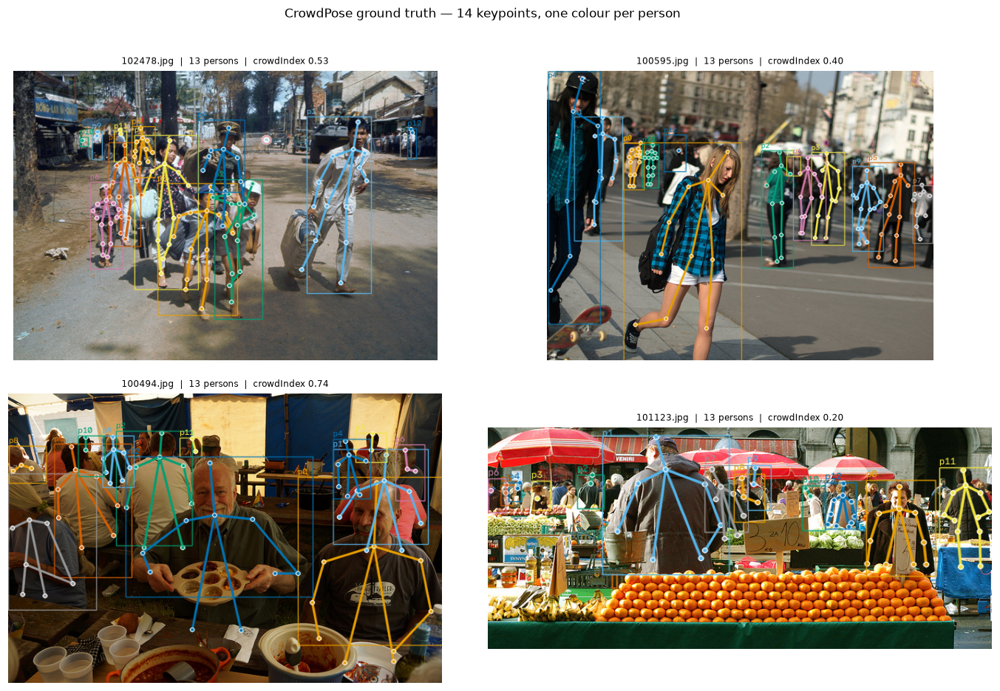

In [12]:
# ---- 2.1  CrowdPose ground truth: one colour per person --------------------------
if crowdpose.samples:
    cp_vis = pick_samples(cp_samples, N_VIS_SAMPLES)
    imgs, titles = [], []
    for s in cp_vis:
        rgb = render_gt(s, crowdpose.skeleton, color_by_visibility=False)
        if rgb is None:
            print(f"[CrowdPose] could not read {s.image_path}")
            continue
        imgs.append(rgb)
        ci = s.meta.get("crowdIndex")
        titles.append(f"{s.meta['file_name']}  |  {len(s.persons)} persons"
                      + (f"  |  crowdIndex {ci:.2f}" if ci is not None else ""))
    show_grid(imgs, titles,
              "CrowdPose ground truth — 14 keypoints, one colour per person",
              ncols=2)
else:
    print("CrowdPose not loaded; skipping its ground-truth visualisation.")

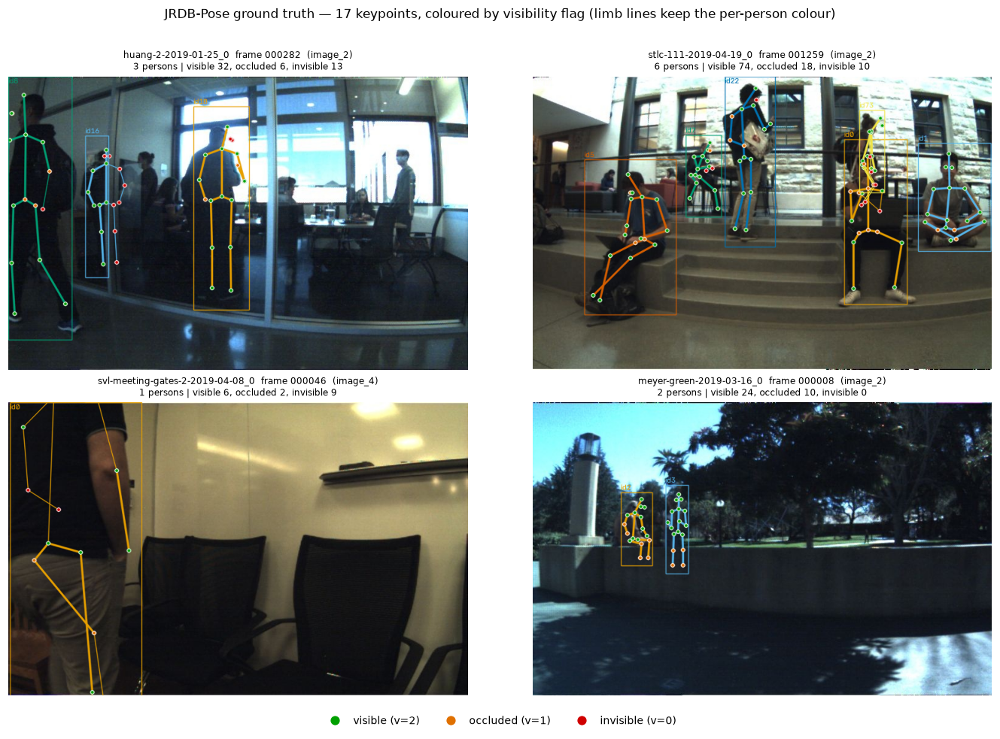

Across the whole JRDB-Pose benchmark subset:
   v=2 visible   :   6,013  ( 65.4% of all annotated keypoint slots)
   v=1 occluded  :   2,201  ( 23.9% of all annotated keypoint slots)
   v=0 invisible :     983  ( 10.7% of all annotated keypoint slots)

23.9% of ground-truth keypoints are explicitly labelled as occluded -- this is the signal Section 6 exploits.


In [13]:
# ---- 2.2  JRDB-Pose ground truth: keypoints colour-coded by visibility -----------
if jrdb.samples:
    jr_vis = pick_samples(jr_samples, N_VIS_SAMPLES, spread_key="scene")
    imgs, titles = [], []
    for s in jr_vis:
        rgb = render_gt(s, jrdb.skeleton, color_by_visibility=True)
        if rgb is None:
            print(f"[JRDB-Pose] could not read {s.image_path}")
            continue
        vis = np.concatenate([p.keypoints[:, 2] for p in s.persons]).astype(int)
        imgs.append(rgb)
        titles.append(f"{s.meta['scene']}  frame {s.meta['frame']}  ({s.meta['camera']})\n"
                      f"{len(s.persons)} persons | visible {int((vis==2).sum())}, "
                      f"occluded {int((vis==1).sum())}, invisible {int((vis==0).sum())}")

    legend = [Line2D([0], [0], marker="o", color="none", label=f"{lab} (v={v})",
                     markerfacecolor=np.array(VIS_COLORS_RGB[v]) / 255.0,
                     markeredgecolor="white", markersize=9)
              for v, lab in [(2, "visible"), (1, "occluded"), (0, "invisible")]]

    show_grid(imgs, titles,
              "JRDB-Pose ground truth — 17 keypoints, coloured by visibility flag "
              "(limb lines keep the per-person colour)",
              ncols=2, legend_handles=legend)

    # Quantify what the colours show, so the visual and the numbers agree.
    allv = np.concatenate([p.keypoints[:, 2] for s in jr_samples for p in s.persons]).astype(int)
    print("Across the whole JRDB-Pose benchmark subset:")
    for v, lab in [(2, "visible"), (1, "occluded"), (0, "invisible")]:
        print(f"   v={v} {lab:<10}: {int((allv==v).sum()):>7,}  ({100*(allv==v).mean():5.1f}% "
              f"of all annotated keypoint slots)")
    print(f"\n{100*(allv==1).mean():.1f}% of ground-truth keypoints are explicitly labelled as "
          f"occluded -- this is the signal Section 6 exploits.")
else:
    print("JRDB-Pose not loaded; skipping its ground-truth visualisation.")

---

# Section 3 — Task 3: Get the models working on the datasets

## 3.1 A single wrapper interface

The three systems have completely different APIs, skeletons and multi-person behaviour.
To make the benchmark fair and the evaluation code write-once, they are all placed behind one
abstract base class:

```
PoseModel
├── available          -> bool  : can this model actually run here?
├── predict(image)     -> PredictionResult
└── native_keypoints   -> the model's own keypoint names, in its own order
```

`predict()` returns a `PredictionResult` holding a list of `PredictedPerson`
(**named** keypoints with a per-keypoint confidence, plus a person box and score) and the
**measured wall-clock inference time** for that image. Timing is taken around the model call
only — image loading and drawing are excluded — so the speed comparison in Section 5 is fair.

The three concrete wrappers, and the one important caveat for each:

| Wrapper | Backend | Native skeleton | Caveat |
|---|---|---|---|
| `YOLOPoseWrapper` | Ultralytics YOLOv8n-pose | COCO-17 | Natively multi-person; runs once per image |
| `MediaPipeWrapper` | MediaPipe Pose | 33 landmarks | **Single-person**: run on person crops, coordinates mapped back |
| `OpenPoseWrapper` | OpenPose — C++ build if present, else the original CMU weights in PyTorch | BODY_25 or COCO-18 | Cannot be pip-installed; see the **third deviation** below |

### The three deviations from the brief, stated up front

1. **MediaPipe version.** The brief asks for `mediapipe==0.10.14` and the legacy
   `mp.solutions.pose` API. That release publishes no wheel for the Python interpreter this
   notebook runs on (see Section 0.2), so it cannot be installed here. The wrapper therefore
   **tries the legacy `mp.solutions.pose` API first and falls back to the modern
   `mediapipe.tasks` `PoseLandmarker` API**. Both produce the *same 33-landmark BlazePose
   skeleton*, so the mapping in Section 4 and every metric downstream are unaffected. The
   Tasks path reads a `.task` model file cached locally under `models/`, so it also runs
   fully offline.
2. **MediaPipe person boxes.** MediaPipe Pose has no multi-person detector, so — as the brief
   allows — it is run on **ground-truth person crops**. This is generous to MediaPipe: it is
   handed perfect person *localisation*, and is never penalised for failing to find where the
   people are. It can still fail to return a pose from a correct crop, so its person recall is
   not automatically 100% — but its recall figures mean something different from YOLO's, and
   the two are not directly comparable. This is flagged again wherever it affects the reading
   of a result.
3. **OpenPose executor.** OpenPose is a C++ project with no pip package, and no compiled
   `pyopenpose` is available on this machine. Rather than drop the model — which would have
   left the whole benchmark with two systems and no bottom-up/top-down contrast worth the
   name — the wrapper runs **CMU's own released COCO-18 weights** (`pose_iter_440000`) through
   an equivalent PyTorch graph. The network, the part affinity fields and the greedy limb
   grouping are OpenPose's; only the executor differs, and the consequence is that OpenPose's
   *timings* are pessimistic while its *accuracy* is representative. Section 3.3 sets this out
   in full, and the caveat is repeated next to the speed chart in Section 5.

In [17]:

# =============================================================================
#  The common model interface
# =============================================================================

@dataclass
class PredictedPerson:
    """One detected person, in a model-independent form."""
    keypoints: Dict[str, Tuple[float, float, float]]   # native name -> (x, y, confidence)
    bbox: Tuple[float, float, float, float]            # (x, y, w, h) in full-image pixels
    score: float = 1.0                                 # person-level detection confidence

    def as_array(self, order: Sequence[str]) -> np.ndarray:
        """Return an (N, 3) array of (x, y, conf) for the requested keypoint names."""
        out = np.zeros((len(order), 3), dtype=np.float32)
        for i, nm in enumerate(order):
            if nm in self.keypoints:
                out[i] = self.keypoints[nm]
        return out


@dataclass
class PredictionResult:
    """Everything one model produced for one image, plus how long it took."""
    persons: List[PredictedPerson]
    inference_ms: float                                # wall clock, model call only
    model_name: str
    n_model_calls: int = 1                             # >1 for crop-based models
    error: Optional[str] = None                        # set instead of raising


class PoseModel(ABC):
    """Abstract base class every pose estimator wrapper implements."""
    name: str = "model"
    native_keypoints: Sequence[str] = ()

    def __init__(self):
        self.available: bool = False
        self.unavailable_reason: str = ""

    @abstractmethod
    def predict(self, image_bgr: np.ndarray,
                person_boxes: Optional[Sequence[Sequence[float]]] = None) -> PredictionResult:
        """Estimate poses in one BGR image.

        person_boxes is an optional list of (x, y, w, h) boxes, used only by
        single-person models that need to be pointed at each person in turn.
        """
        ...

    def warmup(self, image_bgr: np.ndarray) -> None:
        """Run once and discard, so lazy graph/weight loading does not pollute the timings."""
        if self.available:
            try:
                self.predict(image_bgr, person_boxes=[[0, 0, image_bgr.shape[1], image_bgr.shape[0]]])
            except Exception as exc:
                print(f"[{self.name}] warm-up failed: {type(exc).__name__}: {exc}")

    def __repr__(self) -> str:
        state = "available" if self.available else f"UNAVAILABLE ({self.unavailable_reason})"
        return f"<{self.__class__.__name__} {self.name}: {state}>"


# ---- Standard keypoint name lists for the three native skeletons -------------------
COCO17_KEYPOINTS = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle",
]

MEDIAPIPE33_KEYPOINTS = [
    "nose", "left_eye_inner", "left_eye", "left_eye_outer", "right_eye_inner",
    "right_eye", "right_eye_outer", "left_ear", "right_ear", "mouth_left",
    "mouth_right", "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_pinky", "right_pinky", "left_index",
    "right_index", "left_thumb", "right_thumb", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle", "left_heel",
    "right_heel", "left_foot_index", "right_foot_index",
]

# OpenPose's COCO release (pose_deploy_linevec) predicts 18 joints; BODY_25 is the newer
# head of the same family. Which of the two is in play depends on the OpenPose backend.
COCO18_KEYPOINTS = [
    "Nose", "Neck", "RShoulder", "RElbow", "RWrist", "LShoulder", "LElbow", "LWrist",
    "RHip", "RKnee", "RAnkle", "LHip", "LKnee", "LAnkle", "REye", "LEye", "REar", "LEar",
]

BODY25_KEYPOINTS = [
    "Nose", "Neck", "RShoulder", "RElbow", "RWrist", "LShoulder", "LElbow", "LWrist",
    "MidHip", "RHip", "RKnee", "RAnkle", "LHip", "LKnee", "LAnkle", "REye", "LEye",
    "REar", "LEar", "LBigToe", "LSmallToe", "LHeel", "RBigToe", "RSmallToe", "RHeel",
]

# Limb links, expressed on the native index of each skeleton, used only for drawing.
COCO17_SKELETON = [(5, 6), (5, 7), (7, 9), (6, 8), (8, 10), (5, 11), (6, 12), (11, 12),
                   (11, 13), (13, 15), (12, 14), (14, 16), (0, 1), (0, 2), (1, 3), (2, 4)]
MEDIAPIPE33_SKELETON = [(11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (11, 23),
                        (12, 24), (23, 24), (23, 25), (25, 27), (24, 26), (26, 28)]
COCO18_SKELETON = [(1, 2), (1, 5), (2, 3), (3, 4), (5, 6), (6, 7), (1, 8), (8, 9),
                   (9, 10), (1, 11), (11, 12), (12, 13), (1, 0), (0, 14), (0, 15),
                   (14, 16), (15, 17)]
BODY25_SKELETON = [(1, 2), (1, 5), (2, 3), (3, 4), (5, 6), (6, 7), (1, 8), (8, 9),
                   (9, 10), (10, 11), (8, 12), (12, 13), (13, 14), (0, 1)]

print("PoseModel interface defined.")

PoseModel interface defined.


In [18]:

class YOLOPoseWrapper(PoseModel):
    """Ultralytics YOLOv8-pose. Natively multi-person, outputs the COCO-17 skeleton."""
    name = "YOLOv8-pose"
    native_keypoints = COCO17_KEYPOINTS
    native_skeleton = COCO17_SKELETON

    def __init__(self, weights: Path, conf: float = DET_CONF_THRESHOLD, imgsz: int = 640):
        super().__init__()
        self.weights, self.conf, self.imgsz, self.model = Path(weights), conf, imgsz, None
        try:
            from ultralytics import YOLO
        except ImportError as exc:
            self.unavailable_reason = f"ultralytics not installed ({exc})"
            print(f"[{self.name}] UNAVAILABLE: {self.unavailable_reason}")
            print("    install with:  pip install ultralytics")
            return
        if not self.weights.is_file():
            self.unavailable_reason = f"weights not found at {self.weights}"
            print(f"[{self.name}] UNAVAILABLE: {self.unavailable_reason}")
            return
        try:
            self.model = YOLO(str(self.weights))
            self.model.to("cpu")                       # CPU-only, as required by the brief
            self.available = True
            print(f"[{self.name}] ready — weights {self.weights.name}, device CPU, imgsz {imgsz}")
        except Exception as exc:
            self.unavailable_reason = f"{type(exc).__name__}: {exc}"
            print(f"[{self.name}] UNAVAILABLE: {self.unavailable_reason}")

    def predict(self, image_bgr, person_boxes=None) -> PredictionResult:
        if not self.available:
            return PredictionResult([], 0.0, self.name, 0, self.unavailable_reason)
        try:
            t0 = time.perf_counter()
            res = self.model.predict(image_bgr, device="cpu", imgsz=self.imgsz,
                                     conf=self.conf, verbose=False)[0]
            dt = (time.perf_counter() - t0) * 1000.0
        except Exception as exc:
            return PredictionResult([], 0.0, self.name, 1, f"{type(exc).__name__}: {exc}")

        persons = []
        if res.keypoints is not None and res.keypoints.data is not None and len(res.keypoints.data):
            kdata = res.keypoints.data.cpu().numpy()          # (P, 17, 3) = x, y, conf
            boxes = res.boxes.xyxy.cpu().numpy() if res.boxes is not None else None
            scores = res.boxes.conf.cpu().numpy() if res.boxes is not None else None
            for i in range(kdata.shape[0]):
                kp = {nm: (float(kdata[i, j, 0]), float(kdata[i, j, 1]), float(kdata[i, j, 2]))
                      for j, nm in enumerate(self.native_keypoints)}
                if boxes is not None and i < len(boxes):
                    x1, y1, x2, y2 = boxes[i]
                    bbox = (float(x1), float(y1), float(x2 - x1), float(y2 - y1))
                else:                                          # fall back to the keypoint hull
                    arr = kdata[i][kdata[i, :, 2] > 0]
                    bbox = ((float(arr[:, 0].min()), float(arr[:, 1].min()),
                             float(arr[:, 0].ptp()), float(arr[:, 1].ptp()))
                            if len(arr) else (0.0, 0.0, 0.0, 0.0))
                persons.append(PredictedPerson(
                    keypoints=kp, bbox=bbox,
                    score=float(scores[i]) if scores is not None and i < len(scores) else 1.0))
        return PredictionResult(persons, dt, self.name, 1)

In [19]:

class MediaPipeWrapper(PoseModel):
    """MediaPipe Pose (BlazePose, 33 landmarks).

    MediaPipe Pose is a SINGLE-person estimator, so this wrapper runs it once per supplied
    person box (a crop, padded for context) and maps the normalised landmark coordinates back
    into full-image pixel coordinates.

    Two backends are supported and selected automatically:
      * "solutions" - the legacy ``mp.solutions.pose`` API (mediapipe 0.10.x <= 0.10.9)
      * "tasks"     - the modern ``mediapipe.tasks`` PoseLandmarker API
    Both emit the same 33-landmark skeleton, so everything downstream is identical.
    """
    name = "MediaPipe-Pose"
    native_keypoints = MEDIAPIPE33_KEYPOINTS
    native_skeleton = MEDIAPIPE33_SKELETON

    def __init__(self, task_model: Optional[Path] = None,
                 model_complexity: int = 1, crop_pad: float = 0.25,
                 min_detection_confidence: float = 0.2):
        super().__init__()
        self.backend, self._impl, self.crop_pad = None, None, crop_pad
        try:
            import mediapipe as mp
        except ImportError as exc:
            self.unavailable_reason = f"mediapipe not installed ({exc})"
            print(f"[{self.name}] UNAVAILABLE: {self.unavailable_reason}")
            print("    install with:  pip install mediapipe")
            return
        self._mp = mp
        mp_version = _version("mediapipe")

        # --- preferred: legacy solutions API, exactly as the brief specifies ---
        if hasattr(mp, "solutions") and hasattr(mp.solutions, "pose"):
            try:
                self._impl = mp.solutions.pose.Pose(
                    static_image_mode=True, model_complexity=model_complexity,
                    enable_segmentation=False,
                    min_detection_confidence=min_detection_confidence)
                self.backend, self.available = "solutions", True
                print(f"[{self.name}] ready — legacy mp.solutions.pose API "
                      f"(mediapipe {mp_version}), 33 landmarks, CPU")
                return
            except Exception as exc:
                print(f"[{self.name}] legacy solutions API present but failed to start "
                      f"({type(exc).__name__}: {exc}); trying the Tasks API.")

        # --- fallback: modern Tasks API (this is what runs on newer mediapipe builds) ---
        try:
            from mediapipe.tasks.python import vision, BaseOptions
        except Exception as exc:
            self.unavailable_reason = (f"mediapipe {mp_version} exposes neither mp.solutions.pose "
                                       f"nor mediapipe.tasks ({exc})")
            print(f"[{self.name}] UNAVAILABLE: {self.unavailable_reason}")
            return
        task_model = Path(task_model) if task_model else None
        if not task_model or not task_model.is_file():
            self.unavailable_reason = (f"mediapipe {mp_version} needs the Tasks API, but the model "
                                       f"file was not found at {task_model}")
            print(f"[{self.name}] UNAVAILABLE: {self.unavailable_reason}")
            print("    download pose_landmarker_full.task from storage.googleapis.com/mediapipe-models")
            return
        try:
            opts = vision.PoseLandmarkerOptions(
                base_options=BaseOptions(model_asset_path=str(task_model)),
                running_mode=vision.RunningMode.IMAGE,
                num_poses=1,
                min_pose_detection_confidence=min_detection_confidence)
            self._impl = vision.PoseLandmarker.create_from_options(opts)
            self.backend, self.available = "tasks", True
            print(f"[{self.name}] ready — mediapipe.tasks PoseLandmarker "
                  f"(mediapipe {mp_version}), model {task_model.name}, 33 landmarks, CPU")
            print(f"    note: mediapipe=={mp_version} publishes no mp.solutions.pose on this "
                  f"Python build, so the Tasks API is used. Same 33-landmark skeleton.")
        except Exception as exc:
            self.unavailable_reason = f"{type(exc).__name__}: {exc}"
            print(f"[{self.name}] UNAVAILABLE: {self.unavailable_reason}")

    # -- internals ------------------------------------------------------------------
    def _landmarks_on_crop(self, crop_bgr: np.ndarray):
        """Return a list of 33 (x_norm, y_norm, confidence) tuples, or None if no pose found."""
        rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
        if self.backend == "solutions":
            res = self._impl.process(rgb)
            if not res.pose_landmarks:
                return None
            return [(lm.x, lm.y, float(getattr(lm, "visibility", 1.0)))
                    for lm in res.pose_landmarks.landmark]
        mp_img = self._mp.Image(image_format=self._mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))
        res = self._impl.detect(mp_img)
        if not res.pose_landmarks:
            return None
        return [(lm.x, lm.y, float(getattr(lm, "visibility", 1.0)))
                for lm in res.pose_landmarks[0]]

    def predict(self, image_bgr, person_boxes=None) -> PredictionResult:
        if not self.available:
            return PredictionResult([], 0.0, self.name, 0, self.unavailable_reason)
        H, W = image_bgr.shape[:2]
        # With no boxes supplied, fall back to treating the whole frame as one person.
        boxes = list(person_boxes) if person_boxes else [[0, 0, W, H]]

        persons, total_ms, calls = [], 0.0, 0
        for bx in boxes:
            x, y, w, h = [float(v) for v in bx]
            if w <= 1 or h <= 1:
                continue
            # Pad the crop: BlazePose needs some context around the person.
            px, py = w * self.crop_pad, h * self.crop_pad
            x0, y0 = int(max(0, x - px)), int(max(0, y - py))
            x1, y1 = int(min(W, x + w + px)), int(min(H, y + h + py))
            if x1 - x0 < 16 or y1 - y0 < 16:              # too small to be worth running
                continue
            crop = image_bgr[y0:y1, x0:x1]
            calls += 1
            try:
                t0 = time.perf_counter()
                lms = self._landmarks_on_crop(crop)
                total_ms += (time.perf_counter() - t0) * 1000.0
            except Exception as exc:
                print(f"[{self.name}] crop failed ({type(exc).__name__}: {exc}) — skipped")
                continue
            if lms is None:                                # no pose in this crop
                continue
            ch, cw = crop.shape[:2]
            kp = {}
            for nm, (nx, ny, conf) in zip(self.native_keypoints, lms):
                kp[nm] = (x0 + nx * cw, y0 + ny * ch, conf)   # map back to full-image pixels
            persons.append(PredictedPerson(keypoints=kp, bbox=(x, y, w, h), score=1.0))
        return PredictionResult(persons, total_ms, self.name, max(1, calls))

    def close(self):
        """Release the underlying graph (avoids noisy interpreter-shutdown warnings)."""
        try:
            if self._impl is not None:
                self._impl.close()
        except Exception:
            pass

### 3.3  OpenPose — and how it is run here

OpenPose is the bottom-up baseline this benchmark is built around, and it is the one model of
the three that is not a Python package. It ships as a C++ project that must be compiled against
Caffe, and exposes Python only through the `pyopenpose` module that build produces. There is no
`pip install openpose`.

That leaves two ways to put OpenPose in a benchmark, and this notebook supports both:

| backend | what it is | skeleton | when it is used |
|---|---|---|---|
| `pyopenpose` | the official CMU C++ build, driven through its Python API | BODY_25 | if a build is found at `OPENPOSE_ROOT` |
| `torch` | the **original CMU COCO-18 weights** (`pose_iter_440000.caffemodel`), run through an equivalent PyTorch graph | COCO-18 | otherwise — this is the path used for the results below |

The second backend is not a different model. `models/openpose_body_coco18.pth` is a direct,
name-preserving conversion of the weights CMU released for `pose_deploy_linevec.prototxt`: all
184 tensors load into the architecture defined in the next cell with no renaming and no
retraining. The network, the part affinity fields, the peak detection and the greedy limb
grouping below are the same algorithm the C++ binary runs — what differs is the executor
(PyTorch on CPU instead of Caffe) and the head, because CMU's COCO release predicts 18 joints
and 19 limbs where BODY_25 predicts 25 and 26.

**What that means for the comparison.** All three models are reduced to the same 12 common
joints in Section 4, and all 12 exist in both OpenPose skeletons, so the accuracy numbers are
directly comparable either way. The only figure that carries a caveat is speed: the PyTorch
backend is a research-grade executor and is *slower* than CMU's optimised C++ binary, so the
OpenPose timings in Section 5 should be read as an upper bound on its cost, not as the speed of
a tuned deployment. This is stated again next to the speed chart.

A second, deliberate difference from the other two models: OpenPose is **bottom-up**. It is
given the whole image once and finds every person itself, with no detector and no ground-truth
boxes — exactly like YOLOv8-pose and unlike MediaPipe, which is pointed at one person at a time.

In [20]:
# =============================================================================
#  OpenPose, PyTorch backend: the CMU COCO-18 network and its PAF decoder
# =============================================================================
# Everything in this cell is inert unless the PyTorch backend is actually used: it defines
# a graph and some array maths, and touches no files until the wrapper loads the weights.

from collections import OrderedDict

try:
    import torch
    import torch.nn as nn
    from scipy.ndimage import gaussian_filter
    _TORCH_OK, _TORCH_WHY = True, ""
except Exception as _exc:                       # torch/scipy absent -> backend simply unavailable
    _TORCH_OK, _TORCH_WHY = False, f"{type(_exc).__name__}: {_exc}"
    torch = nn = gaussian_filter = None


# ---- 1. The network -------------------------------------------------------------------
# pose_deploy_linevec: VGG-19 truncated to conv4_2 (output stride 8), then two CPM branches
# refined over six stages. Branch L1 regresses 38 part-affinity-field channels (19 limbs x 2
# components), branch L2 regresses 19 confidence maps (18 joints + background).

_VGG_CFG = [("conv1_1", 3, 64), ("conv1_2", 64, 64), ("pool1", 0, 0),
            ("conv2_1", 64, 128), ("conv2_2", 128, 128), ("pool2", 0, 0),
            ("conv3_1", 128, 256), ("conv3_2", 256, 256), ("conv3_3", 256, 256),
            ("conv3_4", 256, 256), ("pool3", 0, 0),
            ("conv4_1", 256, 512), ("conv4_2", 512, 512),
            ("conv4_3_CPM", 512, 256), ("conv4_4_CPM", 256, 128)]


def _named(layers):
    return nn.Sequential(OrderedDict(layers))


def _vgg():
    out = []
    for name, cin, cout in _VGG_CFG:
        if name.startswith("pool"):
            out.append((name, nn.MaxPool2d(2, 2, 0)))
        else:
            out.append((name, nn.Conv2d(cin, cout, 3, 1, 1)))
            out.append((name + "_relu", nn.ReLU(inplace=True)))
    return out


def _stage1(tail, cout):
    """Three 3x3 convs, a 1x1 widening to 512, then the 1x1 output layer."""
    out = []
    for i in (1, 2, 3):
        out.append((f"conv5_{i}_CPM_{tail}", nn.Conv2d(128, 128, 3, 1, 1)))
        out.append((f"conv5_{i}_CPM_{tail}_relu", nn.ReLU(inplace=True)))
    out.append((f"conv5_4_CPM_{tail}", nn.Conv2d(128, 512, 1, 1, 0)))
    out.append((f"conv5_4_CPM_{tail}_relu", nn.ReLU(inplace=True)))
    out.append((f"conv5_5_CPM_{tail}", nn.Conv2d(512, cout, 1, 1, 0)))
    return out


def _stage_n(stage, tail, cout):
    """Refinement stage: five 7x7 convs over [PAFs | heatmaps | features] = 185 channels."""
    out = []
    for i in (1, 2, 3, 4, 5):
        out.append((f"Mconv{i}_stage{stage}_{tail}",
                    nn.Conv2d(185 if i == 1 else 128, 128, 7, 1, 3)))
        out.append((f"Mconv{i}_stage{stage}_{tail}_relu", nn.ReLU(inplace=True)))
    out.append((f"Mconv6_stage{stage}_{tail}", nn.Conv2d(128, 128, 1, 1, 0)))
    out.append((f"Mconv6_stage{stage}_{tail}_relu", nn.ReLU(inplace=True)))
    out.append((f"Mconv7_stage{stage}_{tail}", nn.Conv2d(128, cout, 1, 1, 0)))
    return out


if _TORCH_OK:
    class OpenPoseCOCONet(nn.Module):
        """CMU OpenPose COCO-18 body network (pose_deploy_linevec.prototxt)."""

        N_PAF, N_HEAT, N_STAGES = 38, 19, 6

        def __init__(self):
            super().__init__()
            self.model0 = _named(_vgg())
            self.model1_1 = _named(_stage1("L1", self.N_PAF))
            self.model1_2 = _named(_stage1("L2", self.N_HEAT))
            for s in range(2, self.N_STAGES + 1):
                setattr(self, f"model{s}_1", _named(_stage_n(s, "L1", self.N_PAF)))
                setattr(self, f"model{s}_2", _named(_stage_n(s, "L2", self.N_HEAT)))

        def forward(self, x):
            feat = self.model0(x)
            paf, heat = self.model1_1(feat), self.model1_2(feat)
            for s in range(2, self.N_STAGES + 1):
                joined = torch.cat([paf, heat, feat], 1)
                paf = getattr(self, f"model{s}_1")(joined)
                heat = getattr(self, f"model{s}_2")(joined)
            return paf, heat

        @staticmethod
        def load_cmu_weights(path):
            """Load the converted CMU checkpoint, which keeps the original Caffe layer names."""
            net = OpenPoseCOCONet()
            raw = torch.load(str(path), map_location="cpu", weights_only=True)
            own = net.state_dict()
            # "model3_1.Mconv2_stage3_L1.weight" -> "Mconv2_stage3_L1.weight"
            mapped = {k: raw[k.split(".", 1)[1]] for k in own if k.split(".", 1)[1] in raw}
            if len(mapped) != len(own):
                missing = sorted(set(own) - set(mapped))[:4]
                raise KeyError(f"checkpoint matches {len(mapped)}/{len(own)} tensors; "
                               f"first unmatched: {missing}")
            net.load_state_dict(mapped, strict=True)
            net.eval()
            return net
else:
    OpenPoseCOCONet = None


# ---- 2. The decoder -------------------------------------------------------------------
# The network emits dense maps; turning them into people is the part-affinity-field parse
# described in Cao et al. (2017): find heatmap peaks, score every candidate limb by the line
# integral of the PAF along it, keep a one-to-one assignment per limb type, then merge limbs
# that share an endpoint into whole people.

# The 19 limbs the COCO model scores, on 0-based COCO-18 joint indices.
COCO18_LIMBS = [(1, 2), (1, 5), (2, 3), (3, 4), (5, 6), (6, 7), (1, 8), (8, 9), (9, 10),
                (1, 11), (11, 12), (12, 13), (1, 0), (0, 14), (14, 16), (0, 15), (15, 17),
                (2, 16), (5, 17)]
# Which pair of the 38 PAF channels carries each of those limbs.
COCO18_PAF_CHANNELS = [(12, 13), (20, 21), (14, 15), (16, 17), (22, 23), (24, 25), (0, 1),
                       (2, 3), (4, 5), (6, 7), (8, 9), (10, 11), (28, 29), (30, 31),
                       (34, 35), (32, 33), (36, 37), (18, 19), (26, 27)]

OP_STRIDE      = 8       # network output stride
OP_PAD_VALUE   = 128     # grey padding, as in the reference implementation
OP_HEAT_THRESH = 0.10    # a heatmap local maximum below this is not a candidate joint
OP_PAF_THRESH  = 0.05    # a sample point along a limb counts as supporting it above this
OP_PAF_SAMPLES = 10      # points sampled along each candidate limb
OP_MIN_PARTS   = 4       # a person assembled from fewer joints than this is discarded


def _op_forward_maps(net, image_bgr, boxsize=368, max_side=1100):
    """One forward pass at a single scale; returns (heatmaps, PAFs) at full image resolution."""
    h, w = image_bgr.shape[:2]
    scale = boxsize / h
    if max(h, w) * scale > max_side:            # keep very wide frames affordable on CPU
        scale = max_side / max(h, w)
    small = cv2.resize(image_bgr, (0, 0), fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    ph = (OP_STRIDE - small.shape[0] % OP_STRIDE) % OP_STRIDE
    pw = (OP_STRIDE - small.shape[1] % OP_STRIDE) % OP_STRIDE
    padded = cv2.copyMakeBorder(small, 0, ph, 0, pw, cv2.BORDER_CONSTANT,
                                value=(OP_PAD_VALUE,) * 3)

    x = np.transpose(np.float32(padded), (2, 0, 1)) / 256.0 - 0.5
    with torch.no_grad():
        paf_t, heat_t = net(torch.from_numpy(x[None]))

    def to_image(t):
        a = t[0].numpy().transpose(1, 2, 0)
        a = cv2.resize(a, (0, 0), fx=OP_STRIDE, fy=OP_STRIDE, interpolation=cv2.INTER_CUBIC)
        a = a[: padded.shape[0] - ph, : padded.shape[1] - pw, :]
        return cv2.resize(a, (w, h), interpolation=cv2.INTER_CUBIC)

    return to_image(heat_t), to_image(paf_t)


def _op_find_peaks(heatmap):
    """Local maxima per joint channel -> [(x, y, score, running_id), ...] for each of 18 joints."""
    peaks_per_joint, next_id = [], 0
    for j in range(18):
        m = gaussian_filter(heatmap[:, :, j], sigma=3)
        up, down = np.zeros_like(m), np.zeros_like(m)
        left, right = np.zeros_like(m), np.zeros_like(m)
        up[1:, :], down[:-1, :] = m[:-1, :], m[1:, :]
        left[:, 1:], right[:, :-1] = m[:, :-1], m[:, 1:]
        is_peak = ((m >= up) & (m >= down) & (m >= left) & (m >= right) & (m > OP_HEAT_THRESH))
        ys, xs = np.nonzero(is_peak)
        found = [(int(x), int(y), float(m[y, x]), next_id + i)
                 for i, (x, y) in enumerate(zip(xs, ys))]
        next_id += len(found)
        peaks_per_joint.append(found)
    return peaks_per_joint


def _op_connect(peaks_per_joint, paf, image_shape):
    """Score candidate limbs by the PAF line integral and keep a one-to-one matching."""
    h, w = image_shape[:2]
    per_limb = []
    for (a, b), (ch_x, ch_y) in zip(COCO18_LIMBS, COCO18_PAF_CHANNELS):
        peaks_a, peaks_b = peaks_per_joint[a], peaks_per_joint[b]
        if not peaks_a or not peaks_b:
            per_limb.append([])
            continue
        field = paf[:, :, [ch_x, ch_y]]
        candidates = []
        for i, pa in enumerate(peaks_a):
            for k, pb in enumerate(peaks_b):
                vec = np.array([pb[0] - pa[0], pb[1] - pa[1]], dtype=np.float32)
                length = float(np.linalg.norm(vec))
                if length < 1e-4:
                    continue
                xs = np.clip(np.round(np.linspace(pa[0], pb[0], OP_PAF_SAMPLES)), 0, w - 1)
                ys = np.clip(np.round(np.linspace(pa[1], pb[1], OP_PAF_SAMPLES)), 0, h - 1)
                along = field[ys.astype(int), xs.astype(int), :] @ (vec / length)
                # the reference implementation penalises limbs that are long for the frame,
                # which suppresses links between different people
                prior = min(0.5 * h / length - 1.0, 0.0)
                scored = float(along.mean() + prior)
                if (along > OP_PAF_THRESH).sum() > 0.8 * OP_PAF_SAMPLES and scored > 0:
                    candidates.append((i, k, float(along.mean()),
                                       scored + pa[2] + pb[2]))
        candidates.sort(key=lambda c: -c[3])
        used_a, used_b, kept = set(), set(), []
        for i, k, score, _total in candidates:
            if i in used_a or k in used_b:
                continue
            used_a.add(i)
            used_b.add(k)
            kept.append((peaks_a[i][3], peaks_b[k][3], score))
            if len(kept) >= min(len(peaks_a), len(peaks_b)):
                break
        per_limb.append(kept)
    return per_limb


def _op_group(peaks_per_joint, per_limb):
    """Merge limbs sharing an endpoint into people: rows of 18 peak ids + [score, n_parts]."""
    flat = [p for joint in peaks_per_joint for p in joint]
    people = np.full((0, 20), -1.0)
    for li, (a, b) in enumerate(COCO18_LIMBS):
        for id_a, id_b, score in per_limb[li]:
            owners = [r for r in range(len(people))
                      if people[r][a] == id_a or people[r][b] == id_b]
            if len(owners) == 1:
                r = owners[0]
                if people[r][b] != id_b:
                    people[r][b] = id_b
                    people[r][-1] += 1
                    people[r][-2] += flat[int(id_b)][2] + score
            elif len(owners) == 2:
                r1, r2 = owners
                shared = (((people[r1][:18] >= 0).astype(int)
                           + (people[r2][:18] >= 0).astype(int)) == 2)
                if not shared.any():                     # disjoint halves of one person: merge
                    people[r1][:18] += people[r2][:18] + 1
                    people[r1][-2:] += people[r2][-2:]
                    people[r1][-2] += score
                    people = np.delete(people, r2, axis=0)
                else:                                    # contradictory: extend the first only
                    people[r1][b] = id_b
                    people[r1][-1] += 1
                    people[r1][-2] += flat[int(id_b)][2] + score
            elif li < 17:                                # the two ear-shoulder limbs never start
                row = np.full(20, -1.0)                  # a new person, as in the reference code
                row[a], row[b] = id_a, id_b
                row[-1] = 2
                row[-2] = flat[int(id_a)][2] + flat[int(id_b)][2] + score
                people = np.vstack([people, row])
    keep = [r for r in range(len(people))
            if people[r][-1] >= OP_MIN_PARTS and people[r][-2] / people[r][-1] >= 0.4]
    return people[keep], flat


def openpose_decode(net, image_bgr):
    """Full OpenPose parse of one image -> list of (18, 3) arrays of (x, y, confidence)."""
    heat, paf = _op_forward_maps(net, image_bgr)
    peaks = _op_find_peaks(heat)
    limbs = _op_connect(peaks, paf, image_bgr.shape)
    rows, flat = _op_group(peaks, limbs)

    out = []
    for row in rows:
        kp = np.zeros((18, 3), dtype=np.float32)
        for j in range(18):
            pid = int(row[j])
            if pid >= 0:
                x, y, score, _ = flat[pid]
                kp[j] = (x, y, score)
        out.append(kp)
    return out


print("OpenPose COCO-18 network and PAF decoder defined"
      f"{'' if _TORCH_OK else f' (inactive: {_TORCH_WHY})'}.")

OpenPose COCO-18 network and PAF decoder defined.


In [21]:
class OpenPoseWrapper(PoseModel):
    """CMU OpenPose, run through whichever backend this machine can offer.

    Backend 1 (`pyopenpose`, BODY_25) is the official C++ build. It is preferred when present,
    but it cannot be pip-installed, so backend 2 (`torch`, COCO-18) runs the original CMU
    weights through an equivalent PyTorch graph instead. See the markdown above for what that
    does and does not change. If neither is available the wrapper reports why and marks itself
    unavailable, so the rest of the benchmark still runs.
    """
    name = "OpenPose"

    def __init__(self, openpose_root: Optional[Path] = None,
                 torch_weights: Optional[Path] = None,
                 net_resolution: str = "-1x368"):
        super().__init__()
        self.root = Path(openpose_root) if openpose_root else None
        self.torch_weights = Path(torch_weights) if torch_weights else None
        self.net_resolution = net_resolution
        self.backend = None                 # "pyopenpose" | "torch"
        self.skeleton_id = None             # "BODY_25"    | "COCO_18"
        self._op = self._wrapper = self._net = None
        self.available, self.unavailable_reason = False, ""
        self._reasons = []                  # why each backend was passed over

        if self._try_pyopenpose() or self._try_torch():
            return
        print(f"[{self.name}] UNAVAILABLE")
        for r in self._reasons:
            print(f"    - {r}")
        print("    " + "-" * 68)
        print("    To enable OpenPose, do either of:")
        print("      (a) download the converted CMU COCO-18 weights (209 MB) with")
        print("          python tools/setup_data.py --openpose")
        print("      (b) build the official C++ OpenPose with BUILD_PYTHON=ON and point")
        print("          OPENPOSE_ROOT at it in the configuration cell.")
        print("    Until then this model is SKIPPED and every other model, dataset, metric")
        print("    and figure in this notebook is unaffected.")
        print("    " + "-" * 68)
        self.unavailable_reason = "; ".join(self._reasons)

    # ---- backend 1: the official C++ build --------------------------------------------
    def _try_pyopenpose(self) -> bool:
        op_module = self._import_pyopenpose()
        if op_module is None:
            return False
        try:
            params = {
                "model_folder": str(self.root / "models") if self.root else "models/",
                "model_pose": "BODY_25",
                "net_resolution": self.net_resolution,
                "num_gpu": 0,                 # CPU only, matching the rest of the notebook
                "num_gpu_start": 0,
                "display": 0,
                "render_pose": 0,
            }
            self._wrapper = op_module.WrapperPython()
            self._wrapper.configure(params)
            self._wrapper.start()
        except Exception as exc:
            self._reasons.append(f"pyopenpose imported but failed to start "
                                 f"({type(exc).__name__}: {exc})")
            return False
        self._op = op_module
        self.backend, self.skeleton_id = "pyopenpose", "BODY_25"
        self.native_keypoints, self.native_skeleton = BODY25_KEYPOINTS, BODY25_SKELETON
        self.available = True
        print(f"[{self.name}] ready — native C++ build, BODY_25, "
              f"model folder {params['model_folder']}, CPU")
        return True

    def _import_pyopenpose(self):
        """Try every conventional location for the compiled pyopenpose module."""
        try:                                              # already on sys.path
            import pyopenpose as op
            return op
        except ImportError:
            pass
        if self.root is None or not self.root.is_dir():
            self._reasons.append(f"pyopenpose not importable and OPENPOSE_ROOT "
                                 f"({self.root}) does not exist")
            return None
        candidates = [self.root / "build" / "python" / "openpose" / "Release",
                      self.root / "build" / "python" / "openpose",
                      self.root / "build" / "python",
                      self.root / "python" / "openpose" / "Release",
                      self.root / "python"]
        for cand in candidates:
            if cand.is_dir():
                sys.path.append(str(cand))
                # the compiled module also needs the OpenPose DLLs/SOs on the library path
                for extra in [self.root / "build" / "x64" / "Release", self.root / "build" / "bin"]:
                    if extra.is_dir():
                        os.environ["PATH"] = str(extra) + os.pathsep + os.environ.get("PATH", "")
                try:
                    import pyopenpose as op
                    return op
                except ImportError:
                    continue
        self._reasons.append(f"no compiled pyopenpose module found under {self.root}")
        return None

    # ---- backend 2: the original CMU weights in PyTorch --------------------------------
    def _try_torch(self) -> bool:
        if not _TORCH_OK:
            self._reasons.append(f"PyTorch backend unusable ({_TORCH_WHY})")
            return False
        if self.torch_weights is None or not self.torch_weights.is_file():
            self._reasons.append(f"CMU COCO-18 weights not found at {self.torch_weights}")
            return False
        try:
            self._net = OpenPoseCOCONet.load_cmu_weights(self.torch_weights)
        except Exception as exc:
            self._reasons.append(f"weights present but would not load "
                                 f"({type(exc).__name__}: {exc})")
            return False
        self.backend, self.skeleton_id = "torch", "COCO_18"
        self.native_keypoints, self.native_skeleton = COCO18_KEYPOINTS, COCO18_SKELETON
        self.available = True
        size_mb = self.torch_weights.stat().st_size / 1e6
        print(f"[{self.name}] ready — original CMU COCO-18 weights via PyTorch, CPU "
              f"({size_mb:.0f} MB, {sum(p.numel() for p in self._net.parameters())/1e6:.1f}M params)")
        print(f"    note: research-grade executor, so its timings are an upper bound "
              f"on OpenPose's cost")
        return True

    # ---- inference ---------------------------------------------------------------------
    def predict(self, image_bgr, person_boxes=None) -> PredictionResult:
        """Bottom-up: the whole image goes in once, person_boxes is deliberately ignored."""
        if not self.available:
            return PredictionResult([], 0.0, self.name, 0, self.unavailable_reason)
        try:
            t0 = time.perf_counter()
            raw = (self._predict_pyopenpose(image_bgr) if self.backend == "pyopenpose"
                   else openpose_decode(self._net, image_bgr))
            dt = (time.perf_counter() - t0) * 1000.0
        except Exception as exc:
            return PredictionResult([], 0.0, self.name, 1, f"{type(exc).__name__}: {exc}")

        persons = []
        for arr in raw:
            arr = np.asarray(arr, dtype=np.float32)
            kp = {nm: (float(arr[j, 0]), float(arr[j, 1]), float(arr[j, 2]))
                  for j, nm in enumerate(self.native_keypoints) if j < arr.shape[0]}
            valid = arr[arr[:, 2] > 0]
            bbox = ((float(valid[:, 0].min()), float(valid[:, 1].min()),
                     float(valid[:, 0].max() - valid[:, 0].min()),
                     float(valid[:, 1].max() - valid[:, 1].min()))
                    if len(valid) else (0.0, 0.0, 0.0, 0.0))
            persons.append(PredictedPerson(
                keypoints=kp, bbox=bbox,
                score=float(valid[:, 2].mean()) if len(valid) else 0.0))
        return PredictionResult(persons, dt, self.name, 1)

    def _predict_pyopenpose(self, image_bgr):
        datum = self._op.Datum()
        datum.cvInputData = image_bgr
        self._wrapper.emplaceAndPop(self._op.VectorDatum([datum]))
        kps = getattr(datum, "poseKeypoints", None)        # (P, 25, 3) = x, y, confidence
        if kps is None or getattr(kps, "ndim", 0) != 3:
            return []
        return [kps[i] for i in range(kps.shape[0])]

In [22]:
# =============================================================================
#  Instantiate the three wrappers. Any that cannot run is reported and skipped.
# =============================================================================
print("Initialising models (CPU only)\n" + "-" * 78)
yolo_model = YOLOPoseWrapper(YOLO_WEIGHTS)
print()
yolo26_model = YOLOPoseWrapper(YOLO26_WEIGHTS)
yolo26_model.name = "YOLO26-pose"
print()
mp_model   = MediaPipeWrapper(task_model=MEDIAPIPE_TASK_MODEL)
print()
op_model   = OpenPoseWrapper(OPENPOSE_ROOT, torch_weights=OPENPOSE_WEIGHTS)

ALL_MODELS   = [yolo_model, yolo26_model, mp_model, op_model]   # yolo26 added
MODELS       = [m for m in ALL_MODELS if m.available]     # only these are benchmarked
SKIPPED      = [m for m in ALL_MODELS if not m.available]

print("\n" + "=" * 78)
print("MODEL AVAILABILITY")
print("=" * 78)
for m in ALL_MODELS:
    mark = "RUN " if m.available else "SKIP"
    backend = f" via {m.backend}" if getattr(m, "backend", None) else ""
    detail = (f"{len(m.native_keypoints)} native keypoints{backend}"
              if m.available else m.unavailable_reason)
    print(f"  [{mark}] {m.name:<16} {detail}")
if not MODELS:
    print("\n!! No model is available — Sections 5 and 6 will produce empty tables.")
else:
    print(f"\n{len(MODELS)} of {len(ALL_MODELS)} models will be benchmarked: "
          f"{', '.join(m.name for m in MODELS)}")
    if SKIPPED:
        print(f"Skipped without error: {', '.join(m.name for m in SKIPPED)}")

# ---- Warm-up: the first call loads weights/graphs lazily, which would otherwise be -----
# ---- charged to the first image and distort the speed comparison in Section 5.    -----
_warm_src = (cp_samples or jr_samples)
if _warm_src and MODELS:
    _warm_img = _warm_src[0].load_bgr()
    if _warm_img is not None:
        print("\nWarming up models (timings below exclude this)...")
        for m in MODELS:
            t0 = time.perf_counter()
            m.warmup(_warm_img)
            print(f"  {m.name:<16} warm-up {1000*(time.perf_counter()-t0):7.1f} ms")

Initialising models (CPU only)
------------------------------------------------------------------------------
[YOLOv8-pose] ready — weights yolov8n-pose.pt, device CPU, imgsz 640

[YOLOv8-pose] ready — weights yolo26n-pose.pt, device CPU, imgsz 640



I0000 00:00:1792663384.837557  211481 init-domain.cc:134] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792663384.958429  211484 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792663385.006709  211486 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


[MediaPipe-Pose] ready — mediapipe.tasks PoseLandmarker (mediapipe 1.1.1), model pose_landmarker_full.task, 33 landmarks, CPU
    note: mediapipe==1.1.1 publishes no mp.solutions.pose on this Python build, so the Tasks API is used. Same 33-landmark skeleton.

[OpenPose] ready — original CMU COCO-18 weights via PyTorch, CPU (209 MB, 52.3M params)
    note: research-grade executor, so its timings are an upper bound on OpenPose's cost

MODEL AVAILABILITY
  [RUN ] YOLOv8-pose      17 native keypoints
  [RUN ] YOLO26-pose      17 native keypoints
  [RUN ] MediaPipe-Pose   33 native keypoints via tasks
  [RUN ] OpenPose         18 native keypoints via torch

4 of 4 models will be benchmarked: YOLOv8-pose, YOLO26-pose, MediaPipe-Pose, OpenPose

Warming up models (timings below exclude this)...
  YOLOv8-pose      warm-up   762.2 ms
  YOLO26-pose      warm-up   184.2 ms


W0000 00:00:1792663386.516763  211483 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


  MediaPipe-Pose   warm-up    45.7 ms
  OpenPose         warm-up  1048.2 ms


## 3.2 Run the available models and compare predictions against ground truth

Each available model is now run on the same sample images from both datasets, and its output
is drawn beside the ground truth. This is a *qualitative* check that the wrappers are wired up
correctly — that coordinates are in full-image pixel space, that MediaPipe's crop coordinates
are mapped back properly, and that nothing is mirrored or transposed. The quantitative
comparison follows in Section 5.

Note when reading the MediaPipe panels: it is given the ground-truth person boxes, so it
returns exactly one skeleton per annotated person by construction. YOLO, by contrast, has to
find the people itself, so missed or spurious detections are visible in its panels.

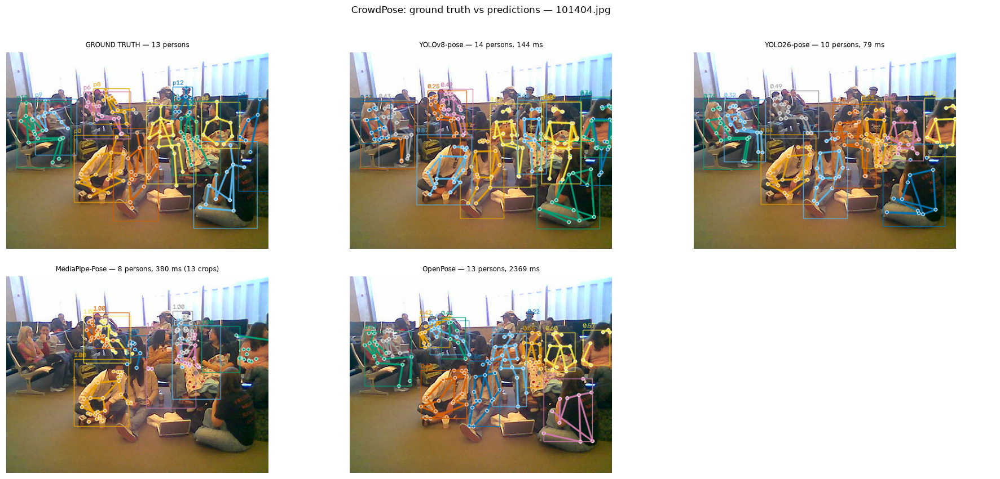

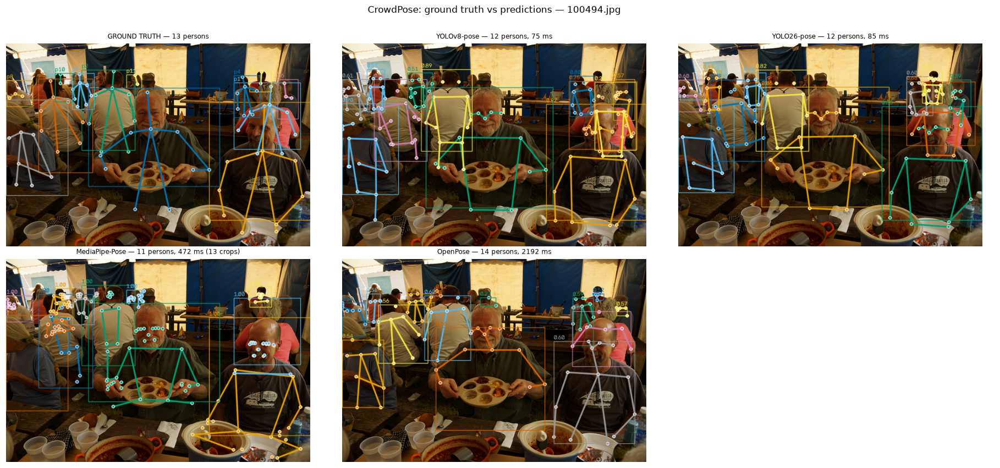

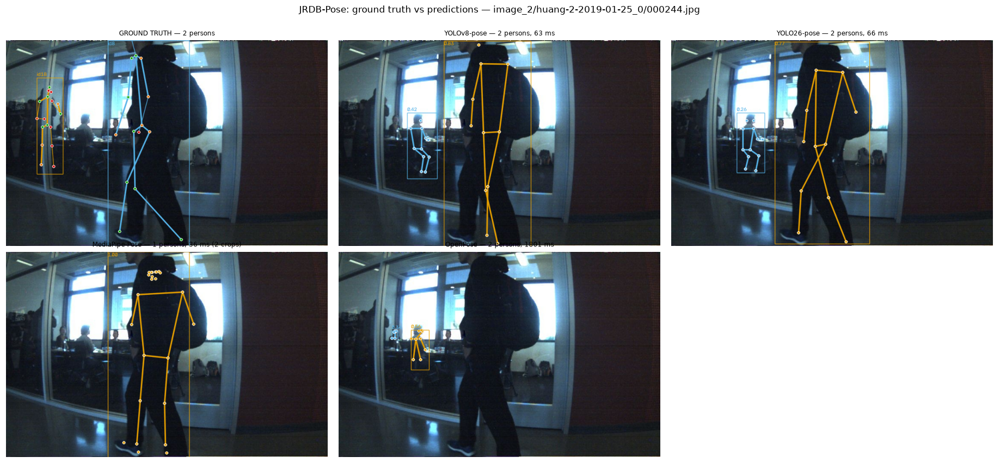

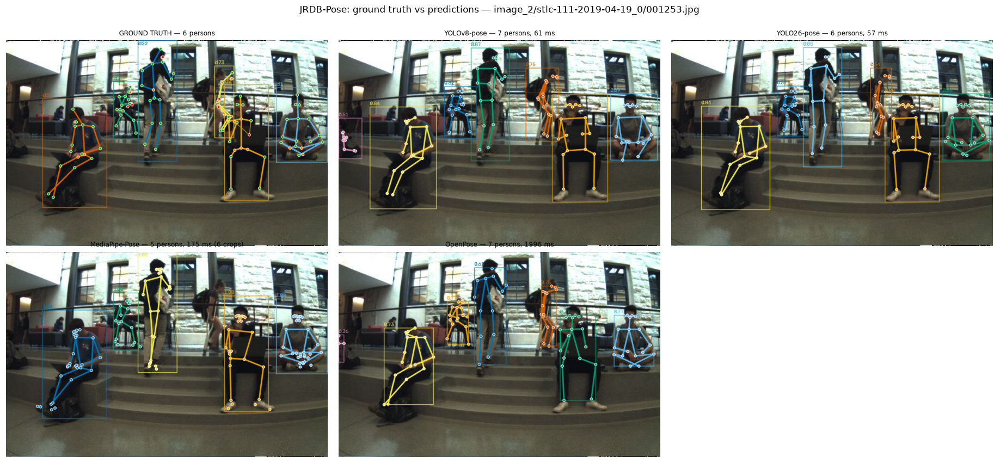

In [23]:
def render_prediction(image_bgr: np.ndarray, result: PredictionResult,
                      model: PoseModel, conf_thr: float = KPT_CONF_THRESHOLD) -> np.ndarray:
    """Draw a model's predicted skeletons (one colour per detected person) on a copy."""
    canvas = image_bgr.copy()
    for pi, person in enumerate(result.persons):
        arr = person.as_array(model.native_keypoints)
        # Reuse the visibility slot of draw_skeleton: keep only confident keypoints.
        vis = np.where(arr[:, 2] >= conf_thr, 2.0, 0.0)
        kp = np.column_stack([arr[:, 0], arr[:, 1], vis])
        draw_skeleton(canvas, kp, getattr(model, "native_skeleton", []),
                      color=_person_color_bgr(pi), bbox=person.bbox,
                      label=f"{person.score:.2f}", draw_invisible=False)
    return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


def compare_gt_and_predictions(samples: List[ImageSample], skeleton, dataset_name: str,
                               models: List[PoseModel], n: int = 2,
                               spread_key: Optional[str] = None) -> None:
    """For n sample images, show ground truth and every available model side by side."""
    chosen = pick_samples(samples, n, seed=RANDOM_SEED, spread_key=spread_key)
    if not chosen:
        print(f"[{dataset_name}] no samples to visualise.")
        return
    for s in chosen:
        img = s.load_bgr()
        if img is None:
            print(f"[{dataset_name}] could not read {s.image_path}; skipped.")
            continue
        panels = [render_gt(s, skeleton, color_by_visibility=(dataset_name == "JRDB-Pose"))]
        titles = [f"GROUND TRUTH — {len(s.persons)} persons"]
        gt_boxes = [p.bbox for p in s.persons]
        for m in models:
            res = m.predict(img, person_boxes=gt_boxes)
            if res.error:
                print(f"[{dataset_name}] {m.name} error on {s.image_path.name}: {res.error}")
                continue
            panels.append(render_prediction(img, res, m))
            titles.append(f"{m.name} — {len(res.persons)} persons, "
                          f"{res.inference_ms:.0f} ms"
                          + (f" ({res.n_model_calls} crops)" if res.n_model_calls > 1 else ""))
        name = s.meta.get("file_name", s.image_path.name)
        show_grid(panels, titles,
                  f"{dataset_name}: ground truth vs predictions — {name}",
                  ncols=min(3, len(panels)), figsize_per=(5.6, 4.0))


if MODELS:
    if crowdpose.samples:
        compare_gt_and_predictions(cp_samples, crowdpose.skeleton, "CrowdPose", MODELS, n=2)
    if jrdb.samples:
        compare_gt_and_predictions(jr_samples, jrdb.skeleton, "JRDB-Pose", MODELS, n=2,
                                   spread_key="scene")
else:
    print("No model available — skipping the qualitative comparison.")

---

# Section 4 — Task 4: One common keypoint set

The five skeletons involved are all different — CrowdPose has 14 joints, JRDB-Pose 17,
COCO/YOLO 17, MediaPipe 33 and OpenPose BODY_25. Comparing them directly would be unfair:
a model whose native skeleton happens to align better with a dataset would score higher for
reasons that have nothing to do with pose accuracy.

Every metric in this notebook is therefore computed on **one common set of 12 joints**, the
joints that exist in *all five* skeletons:

```
left/right shoulder,  left/right elbow,  left/right wrist,
left/right hip,       left/right knee,   left/right ankle
```

Head, face, ear, neck, hand and foot-detail joints are deliberately excluded: they are either
absent from some skeleton or defined too differently across them to compare honestly.

Mapping is done with **explicit index dictionaries**, printed in full below so the protocol is
auditable. One mapping needs a note:

* **JRDB-Pose ankles.** JRDB-Pose has no "ankle" joint; its closest joints are
  `right foot` (15) and `left foot` (16), which mark the ankle/foot position. These are mapped
  to the common ankle slots. This is a documented approximation, applied identically to all
  models, so it cannot favour one of them — but it does mean the absolute ankle numbers on
  JRDB-Pose carry a small systematic offset and are best read as *relative* comparisons.

In [24]:
# =============================================================================
#  The common 12-joint set, and every skeleton -> common mapping
# =============================================================================
COMMON_KEYPOINTS = [
    "left_shoulder",  "right_shoulder",
    "left_elbow",     "right_elbow",
    "left_wrist",     "right_wrist",
    "left_hip",       "right_hip",
    "left_knee",      "right_knee",
    "left_ankle",     "right_ankle",
]
N_COMMON = len(COMMON_KEYPOINTS)
COMMON_INDEX = {nm: i for i, nm in enumerate(COMMON_KEYPOINTS)}

# Limb links on the COMMON indices, used when drawing the mapped skeletons.
COMMON_SKELETON = [(0, 1), (0, 2), (2, 4), (1, 3), (3, 5),
                   (0, 6), (1, 7), (6, 7), (6, 8), (8, 10), (7, 9), (9, 11)]

# --- Dataset skeletons -> common ---------------------------------------------------
# CrowdPose-14 order: L/R shoulder, L/R elbow, L/R wrist, L/R hip, L/R knee, L/R ankle,
#                     head, neck  -> its first 12 entries already are the common set.
CROWDPOSE14_TO_COMMON = {
    "left_shoulder": 0,  "right_shoulder": 1,
    "left_elbow":    2,  "right_elbow":    3,
    "left_wrist":    4,  "right_wrist":    5,
    "left_hip":      6,  "right_hip":      7,
    "left_knee":     8,  "right_knee":     9,
    "left_ankle":   10,  "right_ankle":   11,
}

# JRDB-17 order (read from the label files): head, right eye, left eye, right shoulder,
# center shoulder, left shoulder, right elbow, left elbow, center hip, right wrist,
# right hip, left hip, left wrist, right knee, left knee, right foot, left foot.
# NOTE: "foot" is JRDB's closest joint to an ankle (see the markdown above).
JRDB17_TO_COMMON = {
    "left_shoulder":  5,  "right_shoulder":  3,
    "left_elbow":     7,  "right_elbow":     6,
    "left_wrist":    12,  "right_wrist":     9,
    "left_hip":      11,  "right_hip":      10,
    "left_knee":     14,  "right_knee":     13,
    "left_ankle":    16,  "right_ankle":    15,   # JRDB "left foot" / "right foot"
}

# --- Model skeletons -> common ------------------------------------------------------
COCO17_TO_COMMON = {
    "left_shoulder":  5,  "right_shoulder":  6,
    "left_elbow":     7,  "right_elbow":     8,
    "left_wrist":     9,  "right_wrist":    10,
    "left_hip":      11,  "right_hip":      12,
    "left_knee":     13,  "right_knee":     14,
    "left_ankle":    15,  "right_ankle":    16,
}

MEDIAPIPE33_TO_COMMON = {
    "left_shoulder": 11,  "right_shoulder": 12,
    "left_elbow":    13,  "right_elbow":    14,
    "left_wrist":    15,  "right_wrist":    16,
    "left_hip":      23,  "right_hip":      24,
    "left_knee":     25,  "right_knee":     26,
    "left_ankle":    27,  "right_ankle":    28,
}

COCO18_TO_COMMON = {
    "left_shoulder":  5,  "right_shoulder":  2,
    "left_elbow":     6,  "right_elbow":     3,
    "left_wrist":     7,  "right_wrist":     4,
    "left_hip":      11,  "right_hip":       8,
    "left_knee":     12,  "right_knee":      9,
    "left_ankle":    13,  "right_ankle":    10,
}

BODY25_TO_COMMON = {
    "left_shoulder":  5,  "right_shoulder":  2,
    "left_elbow":     6,  "right_elbow":     3,
    "left_wrist":     7,  "right_wrist":     4,
    "left_hip":      12,  "right_hip":       9,
    "left_knee":     13,  "right_knee":     10,
    "left_ankle":    14,  "right_ankle":    11,
}

# OpenPose emits one of two skeletons depending on which backend loaded (Section 3.3), so its
# entry is selected from the wrapper rather than hard-coded. Both cover all 12 common joints,
# which is what keeps the comparison valid either way.
OPENPOSE_SKELETONS = {
    "BODY_25": ("OpenPose BODY_25", BODY25_TO_COMMON, BODY25_KEYPOINTS),
    "COCO_18": ("OpenPose COCO-18", COCO18_TO_COMMON, COCO18_KEYPOINTS),
}

# Which of the two OpenPose skeletons is in play is read off the wrapper. Tooling that runs
# only the data and mapping cells (tools/build_review_folder.py) never instantiates it, so
# this falls back to COCO-18 — the backend the committed results use.
_OPENPOSE_SKELETON = getattr(globals().get("op_model"), "skeleton_id", None) or "COCO_18"

# Which mapping belongs to which model / dataset.
MODEL_MAPPINGS = {
    "YOLOv8-pose":   ("COCO-17",      COCO17_TO_COMMON,      COCO17_KEYPOINTS),
    "MediaPipe-Pose": ("MediaPipe-33", MEDIAPIPE33_TO_COMMON, MEDIAPIPE33_KEYPOINTS),
    "OpenPose":      OPENPOSE_SKELETONS[_OPENPOSE_SKELETON],
}
MODEL_MAPPINGS["YOLO26-pose"] = MODEL_MAPPINGS["YOLOv8-pose"]   # same COCO-17 skeleton
DATASET_MAPPINGS = {
    "CrowdPose":  ("CrowdPose-14", CROWDPOSE14_TO_COMMON),
    "JRDB-Pose":  ("JRDB-17",      JRDB17_TO_COMMON),
}


def validate_mappings() -> None:
    """Fail loudly if any mapping is incomplete or points outside its skeleton."""
    checks = [
        ("CrowdPose-14", CROWDPOSE14_TO_COMMON, tuple(crowdpose.keypoint_names) or ("",) * 14),
        ("JRDB-17",      JRDB17_TO_COMMON,      tuple(jrdb.keypoint_names) or ("",) * 17),
        ("COCO-17",      COCO17_TO_COMMON,      COCO17_KEYPOINTS),
        ("MediaPipe-33", MEDIAPIPE33_TO_COMMON, MEDIAPIPE33_KEYPOINTS),
        ("BODY_25",      BODY25_TO_COMMON,      BODY25_KEYPOINTS),
        ("COCO-18",      COCO18_TO_COMMON,      COCO18_KEYPOINTS),
    ]
    problems = []
    for label, mapping, names in checks:
        missing = set(COMMON_KEYPOINTS) - set(mapping)
        if missing:
            problems.append(f"{label}: missing common joints {sorted(missing)}")
        for cn, idx in mapping.items():
            if not (0 <= idx < len(names)):
                problems.append(f"{label}: {cn} -> index {idx} is out of range "
                                f"(skeleton has {len(names)} joints)")
        if len(set(mapping.values())) != len(mapping):
            problems.append(f"{label}: two common joints map to the same native index")
    if problems:
        raise ValueError("Keypoint mapping is invalid:\n  " + "\n  ".join(problems))
    print(f"All {len(checks)} mappings validated: each covers all {N_COMMON} common joints, "
          f"with in-range, one-to-one indices.")
    _backend = getattr(globals().get("op_model"), "backend", None)
    print(f"OpenPose is mapped from its {MODEL_MAPPINGS['OpenPose'][0]} skeleton "
          f"(backend: {_backend or 'not instantiated'}).")


validate_mappings()

All 6 mappings validated: each covers all 12 common joints, with in-range, one-to-one indices.
OpenPose is mapped from its OpenPose COCO-18 skeleton (backend: torch).


In [27]:
# ---- Print the full mapping table (the Task 4 deliverable) -----------------------
def _named(mapping: Dict[str, int], names: Sequence[str]) -> List[str]:
    """Render 'index (native name)' for each common joint, in common order."""
    out = []
    for cn in COMMON_KEYPOINTS:
        i = mapping[cn]
        nm = names[i] if i < len(names) else "?"
        out.append(f"{i:>2}  {nm}")
    return out


cp_names = tuple(crowdpose.keypoint_names) or tuple(f"kpt{i}" for i in range(14))
jr_names = tuple(jrdb.keypoint_names) or tuple(f"kpt{i}" for i in range(17))

mapping_table = pd.DataFrame({
    "common joint": COMMON_KEYPOINTS,
    "CrowdPose-14": _named(CROWDPOSE14_TO_COMMON, cp_names),
    "JRDB-17":      _named(JRDB17_TO_COMMON, jr_names),
    "COCO-17 (YOLO)": _named(COCO17_TO_COMMON, COCO17_KEYPOINTS),
    "MediaPipe-33": _named(MEDIAPIPE33_TO_COMMON, MEDIAPIPE33_KEYPOINTS),
    "BODY_25 (OpenPose)": _named(BODY25_TO_COMMON, BODY25_KEYPOINTS),
})

print("=" * 118)
print(f"COMMON KEYPOINT MAPPING — every metric in Sections 5 and 6 uses only these "
      f"{N_COMMON} joints")
print("=" * 118)
with pd.option_context("display.max_colwidth", 30, "display.width", 200):
    print(mapping_table.to_string(index=False))
print("=" * 118)

print("\nJoints present natively but EXCLUDED from the common set:")
for label, names, mapping in [
        ("CrowdPose-14", cp_names, CROWDPOSE14_TO_COMMON),
        ("JRDB-17",      jr_names, JRDB17_TO_COMMON),
        ("COCO-17",      COCO17_KEYPOINTS, COCO17_TO_COMMON),
        ("MediaPipe-33", MEDIAPIPE33_KEYPOINTS, MEDIAPIPE33_TO_COMMON),
        ("BODY_25",      BODY25_KEYPOINTS, BODY25_TO_COMMON)]:
    used = set(mapping.values())
    left = [n for i, n in enumerate(names) if i not in used]
    print(f"  {label:<14} ({len(left):>2} excluded): {', '.join(left) if left else '-'}")

mapping_table.to_csv(RESULTS_DIR / "keypoint_mapping.csv", index=False)
print(f"\nSaved -> {RESULTS_DIR / 'keypoint_mapping.csv'}")

COMMON KEYPOINT MAPPING — every metric in Sections 5 and 6 uses only these 12 joints
  common joint       CrowdPose-14            JRDB-17     COCO-17 (YOLO)       MediaPipe-33 BODY_25 (OpenPose)
 left_shoulder   0  left_shoulder   5  left shoulder   5  left_shoulder  11  left_shoulder       5  LShoulder
right_shoulder  1  right_shoulder  3  right shoulder  6  right_shoulder 12  right_shoulder       2  RShoulder
    left_elbow      2  left_elbow      7  left elbow      7  left_elbow     13  left_elbow          6  LElbow
   right_elbow     3  right_elbow     6  right elbow     8  right_elbow    14  right_elbow          3  RElbow
    left_wrist      4  left_wrist     12  left wrist      9  left_wrist     15  left_wrist          7  LWrist
   right_wrist     5  right_wrist     9  right wrist    10  right_wrist    16  right_wrist          4  RWrist
      left_hip        6  left_hip       11  left hip       11  left_hip       23  left_hip           12  LHip
     right_hip       7  right_hip  

In [28]:
# ---- Conversion helpers: everything becomes an (12, 3) array in common order ------

def gt_to_common(person: GTPerson, mapping: Dict[str, int]) -> np.ndarray:
    """Ground-truth person -> (12, 3) array of (x, y, visibility) in common joint order."""
    out = np.zeros((N_COMMON, 3), dtype=np.float32)
    for ci, cn in enumerate(COMMON_KEYPOINTS):
        ni = mapping[cn]
        if ni < len(person.keypoints):
            out[ci] = person.keypoints[ni]
    return out


def pred_to_common(person: PredictedPerson, mapping: Dict[str, int],
                   native_names: Sequence[str]) -> np.ndarray:
    """Predicted person -> (12, 3) array of (x, y, confidence) in common joint order."""
    out = np.zeros((N_COMMON, 3), dtype=np.float32)
    for ci, cn in enumerate(COMMON_KEYPOINTS):
        ni = mapping[cn]
        if ni < len(native_names):
            nm = native_names[ni]
            if nm in person.keypoints:
                out[ci] = person.keypoints[nm]
    return out


# ---- Sanity check: mapped GT joints must sit where those joints visually are -------
# A wrong mapping is the single most damaging silent error possible here, so it is checked
# numerically: for a correct mapping, mapped shoulders sit above mapped hips, which sit above
# mapped knees, in the great majority of upright pedestrian annotations.
def check_mapping_geometry(samples: List[ImageSample], mapping: Dict[str, int],
                           label: str) -> None:
    ok = tot = 0
    for s in samples:
        for p in s.persons:
            c = gt_to_common(p, mapping)
            sh = c[[0, 1]]; hp = c[[6, 7]]; kn = c[[8, 9]]
            if (sh[:, 2] > 0).all() and (hp[:, 2] > 0).all() and (kn[:, 2] > 0).all():
                tot += 1
                if sh[:, 1].mean() < hp[:, 1].mean() < kn[:, 1].mean():
                    ok += 1
    if tot == 0:
        print(f"  {label:<12}: not enough fully-labelled persons to check")
        return
    frac = ok / tot
    verdict = "OK" if frac > 0.8 else "SUSPICIOUS - check the mapping!"
    print(f"  {label:<12}: shoulders above hips above knees in {ok}/{tot} "
          f"({100*frac:.1f}%) of persons  ->  {verdict}")


print("Geometric sanity check of the ground-truth mappings")
print("-" * 78)
if crowdpose.samples:
    check_mapping_geometry(cp_samples, CROWDPOSE14_TO_COMMON, "CrowdPose")
if jrdb.samples:
    check_mapping_geometry(jr_samples, JRDB17_TO_COMMON, "JRDB-Pose")

Geometric sanity check of the ground-truth mappings
------------------------------------------------------------------------------
  CrowdPose   : shoulders above hips above knees in 1159/1260 (92.0%) of persons  ->  OK
  JRDB-Pose   : shoulders above hips above knees in 443/465 (95.3%) of persons  ->  OK


---

# Section 5 — Task 5: The benchmarking framework

## 5.1 The evaluation protocol

Exactly the same protocol is applied to every model on every dataset. It has four steps.

### Step 1 — Person matching
Predictions are matched to ground-truth people **greedily by bounding-box IoU**: all
prediction/ground-truth pairs are sorted by IoU, and the highest-IoU pair is accepted first,
then the next, never reusing a person on either side. A pair is only accepted at
`IoU >= MATCH_IOU_THRESHOLD` (0.30). Ground-truth people left unmatched are *not* discarded —
they are counted as completely missed, which is what stops a model that simply detects fewer
people from scoring artificially well.

### Step 2 — Accuracy
* **OKS (Object Keypoint Similarity)** — the COCO similarity measure,
  `OKS = mean_i exp(-d_i^2 / (2 s^2 k_i^2))` over annotated common joints, with `s^2` the
  ground-truth box area and `k_i = 2 sigma_i` the standard COCO per-joint constants
  (restricted to the 12 common joints). Reported as a mean over matched person pairs.
* **PCK@0.5** — a keypoint counts as correct if it lands within `0.5 x reference size` of the
  ground-truth joint. The reference is the person's **torso length** (shoulder midpoint to hip
  midpoint) when both are annotated, and `0.5 x sqrt(bbox area)` otherwise — which approximates
  torso length for a normal person aspect ratio. A person-relative reference is used, rather
  than raw pixels, precisely because the two datasets have very different image scales
  (CrowdPose photos vs 752x480 JRDB robot camera frames). **PCK@0.2** is also reported as a
  stricter reading. PCK is computed over **all** annotated common keypoints, so joints
  belonging to an undetected person count as incorrect.

### Step 3 — Speed
Mean wall-clock inference time per image (ms) and the corresponding FPS, timed around the
model call only. For MediaPipe, one "image" means all of its per-person crops for that image
added together, since that is what it costs to process the frame; per-crop cost is reported
separately so the two are not confused.

### Step 4 — Missing keypoint rate
The percentage of annotated common ground-truth keypoints for which the model produced **no
usable output** — either the person was never detected, or the joint came back with a
confidence below `KPT_CONF_THRESHOLD` (0.30). This is reported separately from accuracy
because a model can be precise on what it emits while silently omitting a great deal, and the
occlusion analysis in Section 6 depends on telling those two failure modes apart.

*A caveat on the threshold.* The same 0.30 is applied to all three models, which is the only
defensible choice without per-model tuning, but the three confidence scores are not the same
quantity: YOLOv8-pose emits a keypoint objectness, MediaPipe a landmark presence/visibility
score, and OpenPose the raw height of a part-confidence-map peak. They are calibrated
differently, so the missing-keypoint rate should be read as *"how much does this model, at a
common operating point, decline to commit to"* — a property of the model's confidence
behaviour as much as of its sight. On the CrowdPose subset roughly 14% of the keypoints
OpenPose emits fall between its own detection floor and this threshold. Sweeping the
threshold per model would isolate the two effects; it is out of scope here, and is listed in
Section 8 as further work. PCK, which is reported alongside, is unaffected by this for any
keypoint that clears the threshold.

In [29]:
# =============================================================================
#  Metric primitives
# =============================================================================

# COCO per-keypoint sigmas, restricted to the 12 common joints and kept in common order.
COMMON_SIGMAS = np.array([
    0.079, 0.079,   # shoulders
    0.072, 0.072,   # elbows
    0.062, 0.062,   # wrists
    0.107, 0.107,   # hips
    0.087, 0.087,   # knees
    0.089, 0.089,   # ankles
], dtype=np.float64)


def bbox_iou(a: Sequence[float], b: Sequence[float]) -> float:
    """IoU of two (x, y, w, h) boxes."""
    ax0, ay0, aw, ah = a
    bx0, by0, bw, bh = b
    if aw <= 0 or ah <= 0 or bw <= 0 or bh <= 0:
        return 0.0
    ax1, ay1, bx1, by1 = ax0 + aw, ay0 + ah, bx0 + bw, by0 + bh
    ix = max(0.0, min(ax1, bx1) - max(ax0, bx0))
    iy = max(0.0, min(ay1, by1) - max(ay0, by0))
    inter = ix * iy
    union = aw * ah + bw * bh - inter
    return float(inter / union) if union > 0 else 0.0


def greedy_match(pred_boxes: List[Sequence[float]], gt_boxes: List[Sequence[float]],
                 iou_thr: float = MATCH_IOU_THRESHOLD) -> Dict[int, int]:
    """Greedy highest-IoU-first matching. Returns {gt_index: pred_index}."""
    pairs = []
    for gi, gb in enumerate(gt_boxes):
        for pi, pb in enumerate(pred_boxes):
            iou = bbox_iou(pb, gb)
            if iou >= iou_thr:
                pairs.append((iou, gi, pi))
    pairs.sort(reverse=True)
    matched, used_gt, used_pred = {}, set(), set()
    for iou, gi, pi in pairs:
        if gi in used_gt or pi in used_pred:
            continue
        matched[gi] = pi
        used_gt.add(gi)
        used_pred.add(pi)
    return matched


def reference_size(gt_common: np.ndarray, bbox: Sequence[float]) -> float:
    """Person-relative length used to normalise PCK distances.

    Primary: torso length (shoulder midpoint to hip midpoint) from the ground truth.
    Fallback: 0.5 * sqrt(bbox area), which approximates torso length for a person-shaped box.
    """
    sh, hp = gt_common[[0, 1]], gt_common[[6, 7]]
    if (sh[:, 2] > 0).all() and (hp[:, 2] > 0).all():
        torso = float(np.linalg.norm(sh[:, :2].mean(axis=0) - hp[:, :2].mean(axis=0)))
        if torso > 1.0:
            return torso
    area = max(1.0, float(bbox[2]) * float(bbox[3]))
    return 0.5 * math.sqrt(area)


def person_oks(gt_common: np.ndarray, pred_common: np.ndarray,
               bbox: Sequence[float], conf_thr: float = KPT_CONF_THRESHOLD) -> Optional[float]:
    """COCO OKS between one GT person and one predicted person, on the common joints."""
    valid = gt_common[:, 2] > 0
    if not valid.any():
        return None
    area = max(1.0, float(bbox[2]) * float(bbox[3]))
    k = 2.0 * COMMON_SIGMAS
    d2 = ((pred_common[:, 0] - gt_common[:, 0]) ** 2 +
          (pred_common[:, 1] - gt_common[:, 1]) ** 2)
    e = d2 / (2.0 * area * (k ** 2) + np.finfo(float).eps)
    sim = np.exp(-e)
    # A joint the model did not emit (or emitted below threshold) contributes zero similarity.
    sim = np.where(pred_common[:, 2] >= conf_thr, sim, 0.0)
    return float(sim[valid].mean())


print("Metric primitives ready (IoU matching, OKS, PCK reference size).")

Metric primitives ready (IoU matching, OKS, PCK reference size).


In [30]:
# =============================================================================
#  The evaluation loop: run one model over one dataset and record every keypoint
# =============================================================================

def evaluate(model: PoseModel, dataset: PoseDataset, samples: List[ImageSample],
             gt_mapping: Dict[str, int], use_gt_boxes_for_crops: bool = True,
             progress_every: int = 25) -> Tuple[dict, pd.DataFrame]:
    """Run `model` over `samples` and return (summary dict, per-keypoint records DataFrame).

    The per-keypoint DataFrame is the raw material for both the Section 5 tables and the
    Section 6 occlusion analysis, so no metric is ever computed twice from different data.
    """
    model_map, native_names = None, None
    if model.name in MODEL_MAPPINGS:
        _, model_map, native_names = MODEL_MAPPINGS[model.name]
    if model_map is None:
        raise KeyError(f"No common-set mapping registered for model {model.name!r}")

    records, per_image_ms, per_call_ms = [], [], []
    n_gt = n_pred = n_matched = 0
    n_unreadable = n_errors = 0
    oks_values = []

    t_start = time.perf_counter()
    for si, sample in enumerate(samples, 1):
        img = sample.load_bgr()
        if img is None:                                   # unreadable file: skip, do not crash
            n_unreadable += 1
            continue

        gt_boxes = [p.bbox for p in sample.persons]
        # Single-person models are pointed at each annotated person in turn (see Section 3.1).
        boxes_arg = gt_boxes if use_gt_boxes_for_crops else None
        result = model.predict(img, person_boxes=boxes_arg)
        if result.error:
            n_errors += 1
            continue

        per_image_ms.append(result.inference_ms)
        if result.n_model_calls:
            per_call_ms.append(result.inference_ms / result.n_model_calls)

        pred_common = [pred_to_common(p, model_map, native_names) for p in result.persons]
        pred_boxes = [p.bbox for p in result.persons]
        n_pred += len(result.persons)

        matches = greedy_match(pred_boxes, gt_boxes)

        for gi, person in enumerate(sample.persons):
            gtc = gt_to_common(person, gt_mapping)
            if int((gtc[:, 2] > 0).sum()) < MIN_GT_KEYPOINTS:
                continue                                   # too sparsely annotated to score
            n_gt += 1
            pi = matches.get(gi)
            is_matched = pi is not None
            if is_matched:
                n_matched += 1
                pc = pred_common[pi]
                oks = person_oks(gtc, pc, person.bbox)
                if oks is not None:
                    oks_values.append(oks)
            else:
                pc, oks = None, None

            ref = reference_size(gtc, person.bbox)
            for j in range(N_COMMON):
                v = int(gtc[j, 2])
                # A joint is evaluable if it is labelled (v > 0), or if the dataset annotates
                # a real location even for v == 0 (JRDB-Pose "invisible"). CrowdPose v == 0
                # rows are placeholders at (0, 0) and must not be scored.
                if v <= 0 and not (dataset.annotates_invisible
                                   and (gtc[j, 0] != 0 or gtc[j, 1] != 0)):
                    continue
                if is_matched and pc[j, 2] >= KPT_CONF_THRESHOLD:
                    dist = float(math.hypot(pc[j, 0] - gtc[j, 0], pc[j, 1] - gtc[j, 1]))
                    missing = False
                else:
                    dist, missing = float("nan"), True
                records.append({
                    "dataset": dataset.name, "model": model.name,
                    "image_id": sample.image_id, "gt_person": gi,
                    "track_id": person.track_id,
                    "joint": j, "joint_name": COMMON_KEYPOINTS[j],
                    "visibility": v, "matched": is_matched, "missing": missing,
                    "dist": dist, "ref": ref,
                    "norm_dist": dist / ref if (ref > 0 and not missing) else float("nan"),
                    "correct_pck05": (not missing) and dist <= PCK_ALPHA * ref,
                    "correct_pck02": (not missing) and dist <= PCK_ALPHA_STRICT * ref,
                    "person_oks": oks,
                })
        if progress_every and si % progress_every == 0:
            print(f"    {si}/{len(samples)} images  "
                  f"({time.perf_counter() - t_start:.0f}s elapsed)", flush=True)

    df = pd.DataFrame(records)
    # Section 5 headline metrics use LABELLED keypoints only (visibility > 0), so CrowdPose
    # and JRDB-Pose are treated identically. The v == 0 rows JRDB provides are kept in `df`
    # for the occlusion analysis in Section 6, but excluded from the summary below.
    scored = df[df["visibility"] > 0] if not df.empty else df
    n_eval = len(scored)
    mean_ms = float(np.mean(per_image_ms)) if per_image_ms else float("nan")
    summary = {
        "dataset": dataset.name,
        "model": model.name,
        "images_evaluated": len(per_image_ms),
        "gt_persons": n_gt,
        "predicted_persons": n_pred,
        "matched_persons": n_matched,
        "detection_recall_%": 100.0 * n_matched / n_gt if n_gt else float("nan"),
        "evaluable_keypoints": n_eval,
        "OKS_mean(matched)": float(np.mean(oks_values)) if oks_values else float("nan"),
        "PCK@0.5_%": 100.0 * scored["correct_pck05"].mean() if n_eval else float("nan"),
        "PCK@0.2_%": 100.0 * scored["correct_pck02"].mean() if n_eval else float("nan"),
        "missing_kpt_rate_%": 100.0 * scored["missing"].mean() if n_eval else float("nan"),
        "mean_ms_per_image": mean_ms,
        "FPS": 1000.0 / mean_ms if mean_ms and mean_ms > 0 else float("nan"),
        "mean_ms_per_model_call": float(np.mean(per_call_ms)) if per_call_ms else float("nan"),
        "unreadable_images": n_unreadable,
        "inference_errors": n_errors,
    }
    return summary, df


print("Evaluation loop defined.")

Evaluation loop defined.


In [31]:
# =============================================================================
#  Run every available model over every loaded dataset
# =============================================================================
BENCH_TARGETS = []
if crowdpose.samples:
    BENCH_TARGETS.append((crowdpose, cp_samples, CROWDPOSE14_TO_COMMON))
if jrdb.samples:
    BENCH_TARGETS.append((jrdb, jr_samples, JRDB17_TO_COMMON))

summaries, all_records = [], []
if not MODELS or not BENCH_TARGETS:
    print("Nothing to benchmark (no available model, or no dataset loaded).")
else:
    total = len(MODELS) * len(BENCH_TARGETS)
    print(f"Benchmarking {len(MODELS)} model(s) on {len(BENCH_TARGETS)} dataset(s) "
          f"= {total} runs, CPU only.\n")
    run_i = 0
    bench_t0 = time.perf_counter()
    for ds, samples, gt_map in BENCH_TARGETS:
        for model in MODELS:
            run_i += 1
            print(f"[{run_i}/{total}] {model.name} on {ds.name} "
                  f"({len(samples)} images)...", flush=True)
            try:
                s, df = evaluate(model, ds, samples, gt_map)
            except Exception as exc:
                print(f"    FAILED: {type(exc).__name__}: {exc}")
                continue
            summaries.append(s)
            if not df.empty:
                all_records.append(df)
            print(f"    done — PCK@0.5 {s['PCK@0.5_%']:.1f}% | OKS {s['OKS_mean(matched)']:.3f} "
                  f"| missing {s['missing_kpt_rate_%']:.1f}% "
                  f"| {s['mean_ms_per_image']:.0f} ms/img ({s['FPS']:.1f} FPS)\n", flush=True)
    print(f"All runs finished in {time.perf_counter() - bench_t0:.0f} s.")

records_df = pd.concat(all_records, ignore_index=True) if all_records else pd.DataFrame()
results_df = pd.DataFrame(summaries)
print(f"\nCollected {len(records_df):,} per-keypoint evaluation records "
      f"across {len(results_df)} model x dataset runs.")

Benchmarking 4 model(s) on 2 dataset(s) = 8 runs, CPU only.

[1/8] YOLOv8-pose on CrowdPose (600 images)...
    25/600 images  (2s elapsed)
    50/600 images  (4s elapsed)
    75/600 images  (6s elapsed)
    100/600 images  (9s elapsed)
    125/600 images  (11s elapsed)
    150/600 images  (13s elapsed)
    175/600 images  (14s elapsed)
    200/600 images  (16s elapsed)
    225/600 images  (18s elapsed)
    250/600 images  (20s elapsed)
    275/600 images  (22s elapsed)
    300/600 images  (24s elapsed)
    325/600 images  (25s elapsed)
    350/600 images  (27s elapsed)
    375/600 images  (29s elapsed)
    400/600 images  (31s elapsed)
    425/600 images  (33s elapsed)
    450/600 images  (35s elapsed)
    475/600 images  (36s elapsed)
    500/600 images  (38s elapsed)
    525/600 images  (40s elapsed)
    550/600 images  (42s elapsed)
    575/600 images  (44s elapsed)
    600/600 images  (45s elapsed)
    done — PCK@0.5 85.1% | OKS 0.824 | missing 9.2% | 72 ms/img (13.9 FPS)

[2/8] Y

In [32]:
# =============================================================================
#  5.2  Summary table
# =============================================================================
from IPython.display import display

if results_df.empty:
    print("No results to summarise.")
else:
    display_cols = ["dataset", "model", "images_evaluated", "gt_persons", "matched_persons",
                    "detection_recall_%", "OKS_mean(matched)", "PCK@0.5_%", "PCK@0.2_%",
                    "missing_kpt_rate_%", "mean_ms_per_image", "FPS"]
    summary_table = (results_df[display_cols]
                     .sort_values(["dataset", "model"])
                     .reset_index(drop=True)
                     .round({"detection_recall_%": 1, "OKS_mean(matched)": 3,
                             "PCK@0.5_%": 1, "PCK@0.2_%": 1, "missing_kpt_rate_%": 1,
                             "mean_ms_per_image": 1, "FPS": 2}))
    print("=" * 100)
    print("BENCHMARK SUMMARY — all metrics computed on the common 12-joint set only")
    print("=" * 100)
    display(summary_table)

    # Full table, including the diagnostic columns, goes to CSV.
    csv_path = RESULTS_DIR / "benchmark_summary.csv"
    results_df.to_csv(csv_path, index=False)
    print(f"Saved full results table -> {csv_path}")
    if not records_df.empty:
        rec_path = RESULTS_DIR / "per_keypoint_records.csv"
        records_df.to_csv(rec_path, index=False)
        print(f"Saved {len(records_df):,} per-keypoint records -> {rec_path}")

    if SKIPPED:
        print(f"\nNot in the table (unavailable, skipped without error): "
              f"{', '.join(m.name for m in SKIPPED)}")
    print("\nReminder when reading the table: the two recall columns do NOT mean the same thing.")
    print("  YOLO      finds people itself, so its recall is genuine detection performance.")
    print("  MediaPipe is handed ground-truth person boxes (it has no multi-person detector),")
    print("            so it is never penalised for mis-localising a person; its recall counts")
    print("            only the crops in which BlazePose failed to return any pose at all.")

BENCHMARK SUMMARY — all metrics computed on the common 12-joint set only


,dataset,model,images_evaluated,gt_persons,matched_persons,detection_recall_%,OKS_mean(matched),PCK@0.5_%,PCK@0.2_%,missing_kpt_rate_%,mean_ms_per_image,FPS
0,CrowdPose,MediaPipe-Pose,600,1972,1705,86.5,0.584,60.2,42.8,19.8,120.9,8.27
1,CrowdPose,OpenPose,600,1972,1653,83.8,0.771,70.3,65.0,27.1,1544.6,0.65
2,CrowdPose,YOLO26-pose,600,1972,1843,93.5,0.843,85.8,73.6,9.8,71.5,13.99
3,CrowdPose,YOLOv8-pose,600,1972,1833,93.0,0.824,85.1,69.3,9.2,71.8,13.93
4,JRDB-Pose,MediaPipe-Pose,198,540,399,73.9,0.666,57.0,42.2,34.5,81.7,12.23
5,JRDB-Pose,OpenPose,198,540,439,81.3,0.720,66.6,51.9,30.0,2197.5,0.46
6,JRDB-Pose,YOLO26-pose,198,540,493,91.3,0.747,79.0,56.2,14.1,66.2,15.11
7,JRDB-Pose,YOLOv8-pose,198,540,485,89.8,0.755,79.0,55.4,14.0,110.8,9.02


Saved full results table -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/benchmark_summary.csv
Saved 102,024 per-keypoint records -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/per_keypoint_records.csv

Reminder when reading the table: the two recall columns do NOT mean the same thing.
  YOLO      finds people itself, so its recall is genuine detection performance.
  MediaPipe is handed ground-truth person boxes (it has no multi-person detector),
            so it is never penalised for mis-localising a person; its recall counts
            only the crops in which BlazePose failed to return any pose at all.


## 5.3 Comparison charts

The same numbers again, as grouped bar charts, so the model-to-model and dataset-to-dataset
differences can be read at a glance. Four separate panels are used rather than one combined
chart with two y-axes: accuracy (%), similarity (0–1) and speed (FPS) are different quantities
and putting them on shared axes would misrepresent them. Every bar is directly labelled with
its value, so nothing has to be judged by bar length or colour alone.

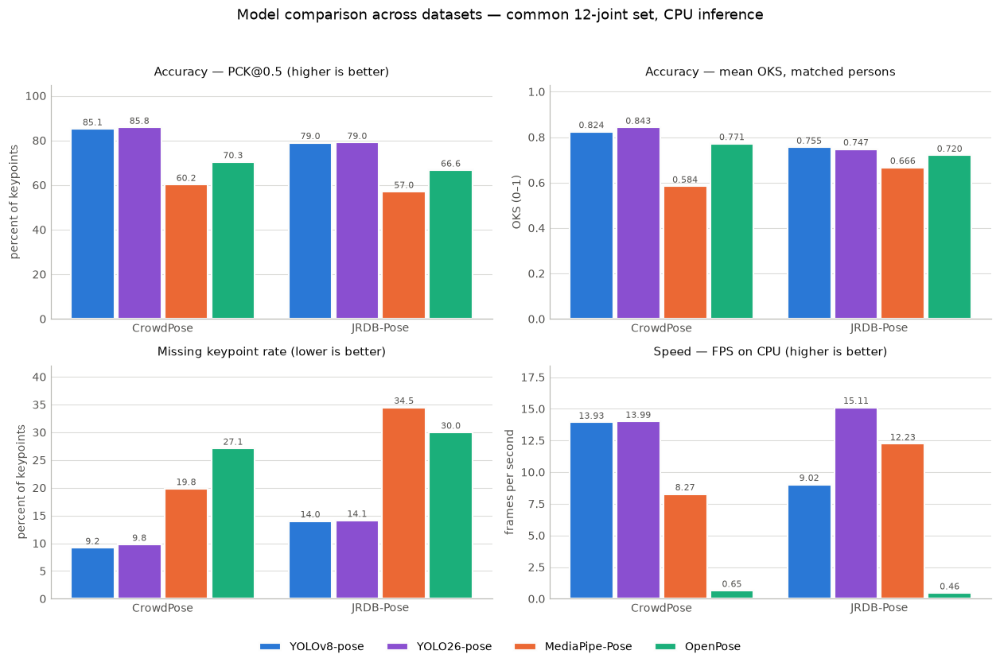

Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/benchmark_comparison.png

NOTE on the speed panel: OpenPose here is CMU's own network run through a
  research-grade PyTorch graph, not CMU's optimised C++ binary (Section 3.3).
  Its FPS is therefore an UPPER BOUND on OpenPose's true cost — a tuned build
  would be faster. The accuracy panels are unaffected: same weights, same
  algorithm. MediaPipe's cost is also not like-for-like, since it is invoked
  once per annotated person rather than once per image; the summary table
  reports its per-call time separately for exactly that reason.


In [33]:
# =============================================================================
#  Chart styling: a fixed, colour-blind-validated categorical palette.
#  Colours are assigned to MODELS in a fixed order and never cycled, so a model
#  keeps the same colour in every figure in this notebook.
# =============================================================================
MODEL_PALETTE = {
    "YOLOv8-pose":    "#2a78d6",   # blue
    "YOLO26-pose":    "#8a4fd0",   # violet
    "MediaPipe-Pose": "#eb6834",   # orange
    "OpenPose":       "#1baf7a",   # aqua
}
GRID_KW = dict(axis="y", color="#d8d8d4", linewidth=0.7, alpha=0.9)


def _style_axes(ax, ylabel: str, title: str) -> None:
    """Recessive grid and axes; the data carries the emphasis."""
    ax.set_axisbelow(True)
    ax.grid(**GRID_KW)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b9b9b4")
    ax.tick_params(colors="#52514e", length=0)
    ax.set_ylabel(ylabel, color="#52514e", fontsize=9)
    ax.set_title(title, fontsize=10, color="#0b0b0b", pad=8)


def grouped_bars(ax, table: pd.DataFrame, value_col: str, ylabel: str, title: str,
                 fmt: str = "{:.1f}") -> None:
    """One grouped bar panel: x = dataset, one bar per model, value labelled on each bar."""
    datasets = list(dict.fromkeys(table["dataset"]))
    models = [m for m in MODEL_PALETTE if m in set(table["model"])]
    if not datasets or not models:
        ax.axis("off")
        return
    n = len(models)
    width = min(0.28, 0.8 / n)
    xs = np.arange(len(datasets), dtype=float)
    for mi, model in enumerate(models):
        vals = []
        for d in datasets:
            row = table[(table["dataset"] == d) & (table["model"] == model)]
            vals.append(float(row[value_col].iloc[0]) if len(row) else np.nan)
        # 2px surface gap between adjacent bars keeps the groups legible.
        offs = (mi - (n - 1) / 2) * (width + 0.015)
        bars = ax.bar(xs + offs, vals, width, label=model,
                      color=MODEL_PALETTE[model], edgecolor="#fcfcfb", linewidth=1.4)
        for b, v in zip(bars, vals):
            if np.isfinite(v):
                ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v),
                            textcoords="offset points", xytext=(0, 3),
                            ha="center", fontsize=7.5, color="#52514e")
    ax.set_xticks(xs)
    ax.set_xticklabels(datasets, fontsize=9)
    finite = table[value_col].replace([np.inf, -np.inf], np.nan).dropna()
    if len(finite):
        ax.set_ylim(0, float(finite.max()) * 1.22)
    _style_axes(ax, ylabel, title)


if results_df.empty:
    print("No results to chart.")
else:
    panels = [
        ("PCK@0.5_%",          "percent of keypoints",   "Accuracy — PCK@0.5 (higher is better)", "{:.1f}"),
        ("OKS_mean(matched)",  "OKS (0–1)",              "Accuracy — mean OKS, matched persons",  "{:.3f}"),
        ("missing_kpt_rate_%", "percent of keypoints",   "Missing keypoint rate (lower is better)", "{:.1f}"),
        ("FPS",                "frames per second",      "Speed — FPS on CPU (higher is better)", "{:.2f}"),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.6))
    for ax, (col, ylab, title, fmt) in zip(axes.ravel(), panels):
        grouped_bars(ax, results_df, col, ylab, title, fmt)
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=max(1, len(labels)),
               frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.005))
    fig.suptitle("Model comparison across datasets — common 12-joint set, CPU inference",
                 fontsize=12)
    fig.tight_layout(rect=(0, 0.05, 1, 0.95))
    fig.savefig(RESULTS_DIR / "benchmark_comparison.png", bbox_inches="tight")
    plt.show()
    print(f"Saved -> {RESULTS_DIR / 'benchmark_comparison.png'}")

    # The speed panel needs a caveat the other three do not: the models are not all running
    # on comparably optimised executors, and saying so is the difference between a fair
    # reading and a misleading one.
    if op_model.available and op_model.backend == "torch":
        print()
        print("NOTE on the speed panel: OpenPose here is CMU's own network run through a")
        print("  research-grade PyTorch graph, not CMU's optimised C++ binary (Section 3.3).")
        print("  Its FPS is therefore an UPPER BOUND on OpenPose's true cost — a tuned build")
        print("  would be faster. The accuracy panels are unaffected: same weights, same")
        print("  algorithm. MediaPipe's cost is also not like-for-like, since it is invoked")
        print("  once per annotated person rather than once per image; the summary table")
        print("  reports its per-call time separately for exactly that reason.")

PER-JOINT PCK@0.5 (%) — common joints only


dataset             CrowdPose                                       JRDB-Pose  \
model          MediaPipe-Pose OpenPose YOLO26-pose YOLOv8-pose MediaPipe-Pose   
joint_name                                                                      
left_shoulder            67.9     82.8        91.2        90.3           65.9   
right_shoulder           68.3     82.7        91.2        90.5           63.3   
left_elbow               58.0     70.2        86.2        87.4           47.4   
right_elbow              59.0     72.6        86.3        86.2           46.3   
left_wrist               55.5     62.1        80.2        81.8           31.5   
right_wrist              57.0     63.9        81.0        80.2           40.6   
left_hip                 66.1     72.8        90.5        89.4           67.8   
right_hip                66.2     72.3        89.7        89.4           64.8   
left_knee                53.5     65.6        82.4        81.4           55.9   
right_knee               54.0     65.3        84.2        82.3           54.3   
left_ankle               54.5     63.0        80.2        77.6           52.0   
right_ankle              54.2     60.8        80.4        78.3           50.4   

dataset                                          
model          OpenPose YOLO26-pose YOLOv8-pose  
joint_name                                       
left_shoulder      71.7        80.9        80.9  
right_shoulder     73.9        79.8        80.7  
left_elbow         53.5        72.8        75.4  
right_elbow        55.0        69.3        70.9  
left_wrist         40.7        62.0        66.1  
right_wrist        48.0        61.7        62.4  
left_hip           74.8        88.0        86.5  
right_hip          75.6        87.4        87.4  
left_knee          68.0        79.8        79.8  
right_knee         68.7        80.4        78.1  
left_ankle         61.3        71.9        75.4  
right_ankle        56.3        68.3        67.6

Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/per_joint_pck.csv


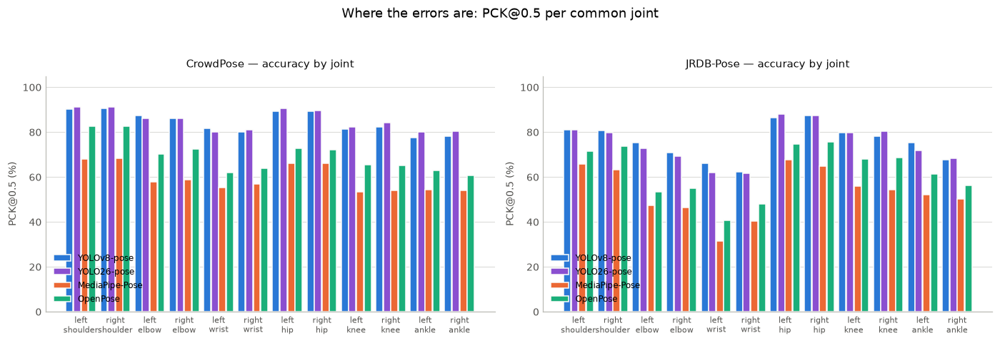


Proximal (shoulders + hips) vs distal (wrists + ankles) PCK@0.5:
  CrowdPose   MediaPipe-Pose   proximal  67.1%   distal  55.4%   drop  11.7 pp
  CrowdPose   OpenPose         proximal  77.8%   distal  62.5%   drop  15.2 pp
  CrowdPose   YOLO26-pose      proximal  90.7%   distal  80.5%   drop  10.2 pp
  CrowdPose   YOLOv8-pose      proximal  89.9%   distal  79.7%   drop  10.2 pp
  JRDB-Pose   MediaPipe-Pose   proximal  65.5%   distal  43.6%   drop  21.9 pp
  JRDB-Pose   OpenPose         proximal  74.0%   distal  51.6%   drop  22.4 pp
  JRDB-Pose   YOLO26-pose      proximal  84.0%   distal  66.0%   drop  18.1 pp
  JRDB-Pose   YOLOv8-pose      proximal  83.9%   distal  67.9%   drop  16.0 pp


In [34]:
# =============================================================================
#  5.4  Per-joint breakdown — which joints actually cost each model its accuracy
# =============================================================================
if records_df.empty:
    print("No per-keypoint records to break down.")
else:
    joint_pck = (records_df.groupby(["dataset", "model", "joint", "joint_name"])["correct_pck05"]
                 .mean().mul(100).reset_index(name="PCK@0.5_%"))
    joint_tab = (joint_pck.pivot_table(index="joint_name", columns=["dataset", "model"],
                                       values="PCK@0.5_%")
                 .reindex(COMMON_KEYPOINTS).round(1))
    print("=" * 100)
    print("PER-JOINT PCK@0.5 (%) — common joints only")
    print("=" * 100)
    display(joint_tab)
    joint_tab.to_csv(RESULTS_DIR / "per_joint_pck.csv")
    print(f"Saved -> {RESULTS_DIR / 'per_joint_pck.csv'}")

    datasets = list(dict.fromkeys(records_df["dataset"]))
    fig, axes = plt.subplots(1, len(datasets), figsize=(6.4 * len(datasets), 4.4), squeeze=False)
    for ax, dname in zip(axes.ravel(), datasets):
        sub = joint_pck[joint_pck["dataset"] == dname]
        models = [m for m in MODEL_PALETTE if m in set(sub["model"])]
        xs = np.arange(N_COMMON, dtype=float)
        n = max(1, len(models))
        width = min(0.34, 0.82 / n)
        for mi, model in enumerate(models):
            s = sub[sub["model"] == model].set_index("joint")["PCK@0.5_%"]
            vals = [float(s.get(j, np.nan)) for j in range(N_COMMON)]
            offs = (mi - (n - 1) / 2) * (width + 0.015)
            ax.bar(xs + offs, vals, width, label=model, color=MODEL_PALETTE[model],
                   edgecolor="#fcfcfb", linewidth=1.0)
        ax.set_xticks(xs)
        ax.set_xticklabels([k.replace("_", "\n") for k in COMMON_KEYPOINTS], fontsize=7)
        ax.set_ylim(0, 105)
        _style_axes(ax, "PCK@0.5 (%)", f"{dname} — accuracy by joint")
        if len(models) > 1:
            ax.legend(frameon=False, fontsize=8, loc="lower left")
    fig.suptitle("Where the errors are: PCK@0.5 per common joint", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    fig.savefig(RESULTS_DIR / "per_joint_pck.png", bbox_inches="tight")
    plt.show()

    # Distal joints (wrists, ankles) are the classic failure case; quantify it rather
    # than asserting it.
    prox = ["left_shoulder", "right_shoulder", "left_hip", "right_hip"]
    dist = ["left_wrist", "right_wrist", "left_ankle", "right_ankle"]
    print("\nProximal (shoulders + hips) vs distal (wrists + ankles) PCK@0.5:")
    for (dname, mname), g in records_df.groupby(["dataset", "model"]):
        p = 100 * g[g["joint_name"].isin(prox)]["correct_pck05"].mean()
        d = 100 * g[g["joint_name"].isin(dist)]["correct_pck05"].mean()
        print(f"  {dname:<11} {mname:<16} proximal {p:5.1f}%   distal {d:5.1f}%   "
              f"drop {p - d:5.1f} pp")

In [ ]:
# PCK threshold comparison using saved benchmark predictions.
# No model inference is performed.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

records = pd.read_csv(RESULTS_DIR / "per_keypoint_records.csv")

# Match Section 5's headline scoring population:
# include labelled joints only, with missing predictions counted as incorrect.
scored = records.loc[records["visibility"] > 0].copy()

# Read Boolean values safely from CSV.
missing = (
    scored["missing"].astype(str).str.strip().str.lower()
    .map({"true": True, "false": False})
)
if missing.isna().any():
    raise ValueError("Unexpected values in the 'missing' column.")

scored["_missing"] = missing
scored["_distance"] = pd.to_numeric(
    scored["norm_dist"], errors="coerce"
)

# Missing joints may have NaN distances; accepted joints should not.
invalid = (
    ~scored["_missing"]
    & ~np.isfinite(scored["_distance"])
)
if invalid.any():
    raise ValueError("Some accepted predictions have invalid distances.")

thresholds = [0.2, 0.5, 1.0]
rows = []

for (dataset, model), group in scored.groupby(
    ["dataset", "model"], sort=False
):
    row = {
        "Dataset": dataset,
        "Model": model,
        "Evaluated joints": len(group),
    }

    for alpha in thresholds:
        correct = (
            ~group["_missing"]
            & (group["_distance"] <= alpha)
        )
        row[f"PCK@{alpha:.1f} (%)"] = 100 * correct.mean()

    row["Gain 0.2→0.5 (pp)"] = (
        row["PCK@0.5 (%)"] - row["PCK@0.2 (%)"]
    )
    row["Gain 0.5→1.0 (pp)"] = (
        row["PCK@1.0 (%)"] - row["PCK@0.5 (%)"]
    )
    row["Missing (%)"] = 100 * group["_missing"].mean()
    rows.append(row)

pck_table = pd.DataFrame(rows)

if pck_table.empty:
    raise ValueError("No eligible records found.")

print("PCK THRESHOLD COMPARISON")
print("Same labelled joints and predictions at every threshold.")
print("Missing predictions count as incorrect at all thresholds.\n")
display(pck_table.round(2))

table_path = RESULTS_DIR / "pck_threshold_comparison.csv"
pck_table.to_csv(table_path, index=False)

# Plot one panel per dataset.
dataset_names = pck_table["Dataset"].unique()
fig, axes = plt.subplots(
    1, len(dataset_names),
    figsize=(7 * len(dataset_names), 5),
    squeeze=False
)

pck_columns = [f"PCK@{a:.1f} (%)" for a in thresholds]

for ax, dataset in zip(axes[0], dataset_names):
    subset = pck_table[pck_table["Dataset"] == dataset]

    for _, row in subset.iterrows():
        ax.plot(
            thresholds,
            row[pck_columns].to_numpy(dtype=float),
            marker="o", linewidth=2, label=row["Model"]
        )

    ax.set_title(dataset)
    ax.set_xlabel("PCK threshold × person reference length")
    ax.set_ylabel("Correct labelled joints (%)")
    ax.set_xticks(thresholds)
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle("Accuracy under strict, standard and lenient tolerances")
fig.tight_layout()

figure_path = RESULTS_DIR / "pck_threshold_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# Brief findings calculated directly from this run.
for dataset in dataset_names:
    subset = pck_table[pck_table["Dataset"] == dataset]
    print(f"\n{dataset}")

    for column in pck_columns:
        best = subset[column].max()
        winners = subset.loc[
            np.isclose(subset[column], best, rtol=0, atol=1e-9),
            "Model"
        ]
        print(f"  Highest {column}: {', '.join(winners)} — {best:.2f}")

    for _, row in subset.iterrows():
        print(
            f"  {row['Model']}: "
            f"+{row['Gain 0.2→0.5 (pp)']:.2f} pp from 0.2 to 0.5; "
            f"+{row['Gain 0.5→1.0 (pp)']:.2f} pp from 0.5 to 1.0; "
            f"{row['Missing (%)']:.2f}% missing."
        )

print(f"\nSaved: {table_path}")
print(f"Saved: {figure_path}")


MediaPipe — CrowdPose, sample 0
  Returned poses: 2
  Matched eligible people: 2/2
  Joints meeting confidence threshold: 17


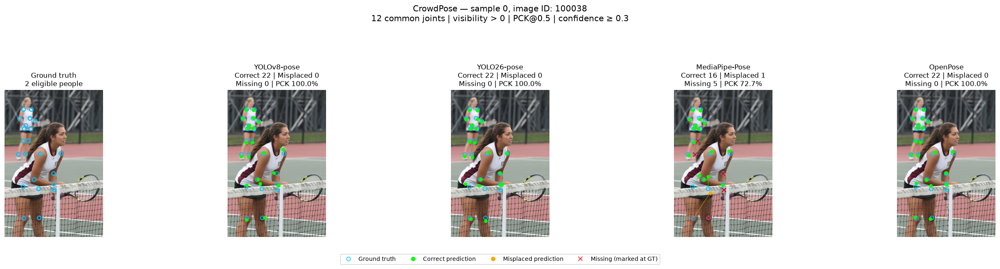

Saved: /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/error_examples/CrowdPose_sample_0.png

MediaPipe — CrowdPose, sample 1
  Returned poses: 1
  Matched eligible people: 1/2
  Joints meeting confidence threshold: 5


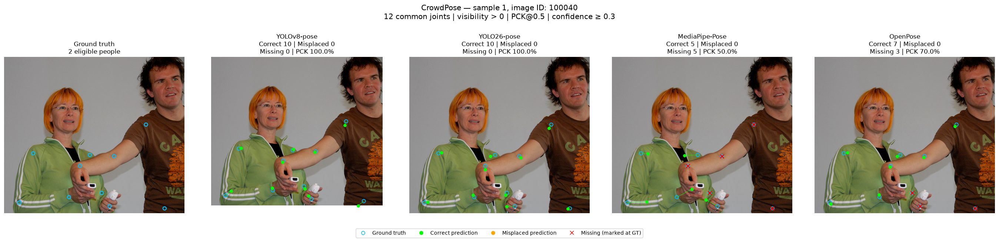

Saved: /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/error_examples/CrowdPose_sample_1.png

MediaPipe — CrowdPose, sample 2
  Returned poses: 5
  Matched eligible people: 5/9
  Joints meeting confidence threshold: 44


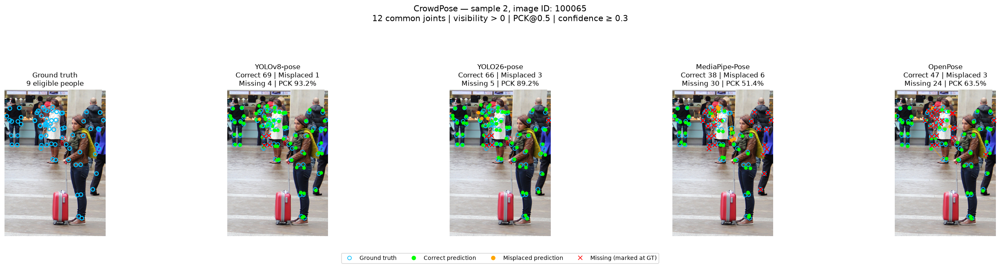

Saved: /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/error_examples/CrowdPose_sample_2.png

MediaPipe — JRDB-Pose, sample 0
  Returned poses: 3
  Matched eligible people: 3/3
  Joints meeting confidence threshold: 28


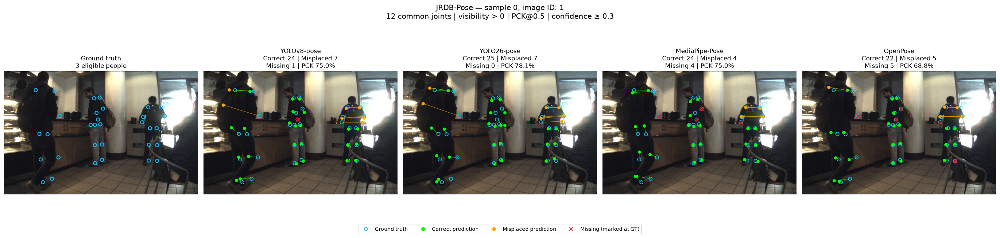

Saved: /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/error_examples/JRDB-Pose_sample_0.png

MediaPipe — JRDB-Pose, sample 1
  Returned poses: 3
  Matched eligible people: 3/3
  Joints meeting confidence threshold: 30


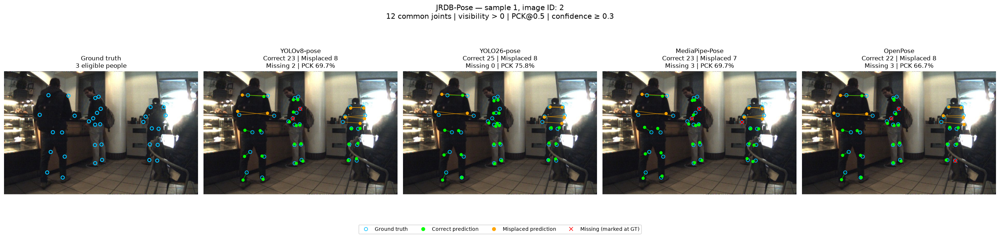

Saved: /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/error_examples/JRDB-Pose_sample_1.png

MediaPipe — JRDB-Pose, sample 2
  Returned poses: 3
  Matched eligible people: 3/3
  Joints meeting confidence threshold: 30


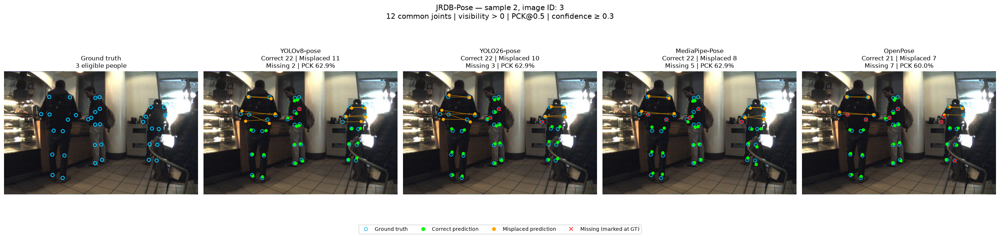

Saved: /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/error_examples/JRDB-Pose_sample_2.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Use [0, 1] for two examples per dataset.
EXAMPLE_INDICES = [0, 1, 2]

error_output = RESULTS_DIR / "error_examples"
error_output.mkdir(parents=True, exist_ok=True)

datasets = [
    ("CrowdPose", cp_samples, CROWDPOSE14_TO_COMMON),
    ("JRDB-Pose", jr_samples, JRDB17_TO_COMMON),
]

legend = [
    Line2D([], [], marker="o", linestyle="None",
           markerfacecolor="none", markeredgecolor="deepskyblue",
           label="Ground truth"),
    Line2D([], [], marker="o", linestyle="None",
           color="lime", label="Correct prediction"),
    Line2D([], [], marker="o", linestyle="None",
           color="orange", label="Misplaced prediction"),
    Line2D([], [], marker="x", linestyle="None",
           color="red", label="Missing (marked at GT)"),
]

for dataset_name, samples, gt_mapping in datasets:
    for sample_index in EXAMPLE_INDICES:
        if not 0 <= sample_index < len(samples):
            print(f"{dataset_name}: sample {sample_index} unavailable.")
            continue

        sample = samples[sample_index]
        image_bgr = sample.load_bgr()

        if image_bgr is None:
            print(f"{dataset_name}: cannot read sample {sample_index}.")
            continue

        image_rgb = image_bgr[:, :, ::-1]
        gt_boxes = [person.bbox for person in sample.persons]

        # Same eligibility rule as the headline benchmark.
        eligible = []
        for gi, person in enumerate(sample.persons):
            gt = gt_to_common(person, gt_mapping)
            valid = gt[:, 2] > 0

            if valid.sum() >= MIN_GT_KEYPOINTS:
                eligible.append((gi, person, gt, valid))

        if not eligible:
            print(f"{dataset_name}: no eligible people in sample {sample_index}.")
            continue

        fig, axes = plt.subplots(
            1, len(MODELS) + 1,
            figsize=(5 * (len(MODELS) + 1), 6),
            squeeze=False
        )
        axes = axes[0]

        for ax in axes:
            ax.imshow(image_rgb)
            ax.axis("off")

        # Ground-truth panel.
        for _, person, gt, valid in eligible:
            axes[0].scatter(
                gt[valid, 0], gt[valid, 1],
                s=35, facecolors="none",
                edgecolors="deepskyblue", linewidths=1.5
            )

        axes[0].set_title(
            f"Ground truth\n{len(eligible)} eligible people"
        )

        # Run each model on this same image.
        for ax, model in zip(axes[1:], MODELS):
            result = model.predict(image_bgr, person_boxes=gt_boxes)

            if result.error:
                ax.set_title(f"{model.name}\nInference error")
                print(f"{dataset_name} / {model.name}: {result.error}")
                continue

            _, model_mapping, native_names = MODEL_MAPPINGS[model.name]

            predictions = [
                pred_to_common(p, model_mapping, native_names)
                for p in result.persons
            ]

            matches = greedy_match(
                [p.bbox for p in result.persons],
                gt_boxes
            )

            # Diagnostics belong HERE, inside the model loop.
            if model.name == "MediaPipe-Pose":
                matched_people = sum(
                    gi in matches for gi, _, _, _ in eligible
                )

                accepted_joints = sum(
                    int((
                        (predictions[matches[gi]][:, 2]
                         >= KPT_CONF_THRESHOLD) & valid
                    ).sum())
                    for gi, _, _, valid in eligible
                    if gi in matches
                )

                print(
                    f"\nMediaPipe — {dataset_name}, sample {sample_index}\n"
                    f"  Returned poses: {len(result.persons)}\n"
                    f"  Matched eligible people: "
                    f"{matched_people}/{len(eligible)}\n"
                    f"  Joints meeting confidence threshold: "
                    f"{accepted_joints}"
                )

            counts = {"correct": 0, "misplaced": 0, "missing": 0}

            for gi, person, gt, valid in eligible:
                pi = matches.get(gi)
                pred = predictions[pi] if pi is not None else None
                tolerance = PCK_ALPHA * reference_size(gt, person.bbox)

                ax.scatter(
                    gt[valid, 0], gt[valid, 1],
                    s=35, facecolors="none",
                    edgecolors="deepskyblue", linewidths=1.2
                )

                for j in np.flatnonzero(valid):
                    gx, gy = gt[j, :2]

                    if pred is None or not (
                        pred[j, 2] >= KPT_CONF_THRESHOLD
                    ):
                        counts["missing"] += 1
                        ax.scatter(
                            gx, gy, marker="x", color="red",
                            s=45, linewidths=1.6
                        )
                        continue

                    px, py = pred[j, :2]
                    distance = float(np.hypot(px - gx, py - gy))
                    correct = distance <= tolerance

                    category = "correct" if correct else "misplaced"
                    colour = "lime" if correct else "orange"
                    counts[category] += 1

                    ax.plot(
                        [gx, px], [gy, py],
                        color=colour, linewidth=0.8, alpha=0.7
                    )
                    ax.scatter(px, py, color=colour, s=22)

            total = sum(counts.values())
            pck = (
                100 * counts["correct"] / total
                if total else float("nan")
            )

            ax.set_title(
                f"{model.name}\n"
                f"Correct {counts['correct']} | "
                f"Misplaced {counts['misplaced']}\n"
                f"Missing {counts['missing']} | PCK {pck:.1f}%"
            )

        fig.suptitle(
            f"{dataset_name} — sample {sample_index}, "
            f"image ID: {sample.image_id}\n"
            f"12 common joints | visibility > 0 | "
            f"PCK@{PCK_ALPHA:g} | confidence ≥ {KPT_CONF_THRESHOLD:g}",
            fontsize=13
        )

        fig.legend(
            handles=legend, loc="lower center",
            ncol=4, bbox_to_anchor=(0.5, 0.01)
        )
        fig.tight_layout(rect=[0, 0.10, 1, 0.88])

        save_path = (
            error_output / f"{dataset_name}_sample_{sample_index}.png"
        )
        fig.savefig(save_path, dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        print(f"Saved: {save_path}")

PCK THRESHOLD COMPARISON
Same labelled joints and predictions at every threshold.
Missing predictions count as incorrect at all thresholds.



,Dataset,Model,Evaluated joints,PCK@0.2 (%),PCK@0.5 (%),PCK@1.0 (%),Gain 0.2→0.5 (pp),Gain 0.5→1.0 (pp),Missing (%)
0,CrowdPose,YOLOv8-pose,19026,69.35,85.15,89.42,15.80,4.28,9.18
1,CrowdPose,YOLO26-pose,19026,73.58,85.80,89.09,12.21,3.29,9.78
2,CrowdPose,MediaPipe-Pose,19026,42.82,60.19,71.05,17.37,10.86,19.84
3,CrowdPose,OpenPose,19026,64.96,70.34,72.19,5.37,1.86,27.10
4,JRDB-Pose,YOLOv8-pose,5939,55.41,78.99,85.17,23.57,6.18,14.01
5,JRDB-Pose,YOLO26-pose,5939,56.24,79.02,84.83,22.78,5.81,14.11
6,JRDB-Pose,MediaPipe-Pose,5939,42.18,57.01,62.70,14.83,5.69,34.50
7,JRDB-Pose,OpenPose,5939,51.88,66.64,69.59,14.77,2.95,30.01


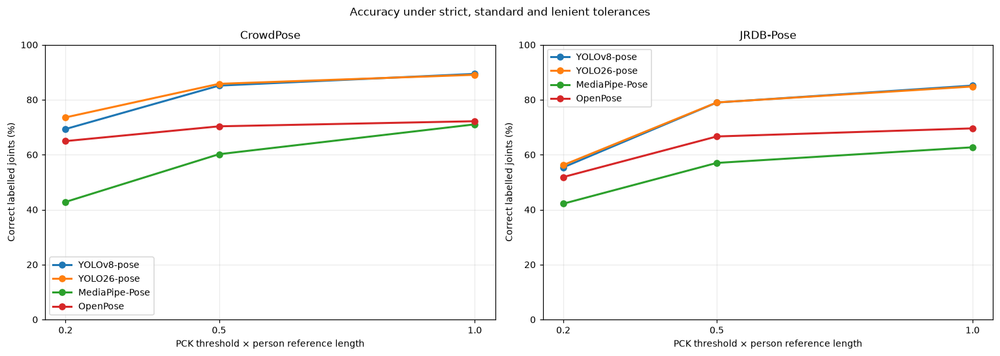


CrowdPose
  Highest PCK@0.2 (%): YOLO26-pose — 73.58
  Highest PCK@0.5 (%): YOLO26-pose — 85.80
  Highest PCK@1.0 (%): YOLOv8-pose — 89.42
  YOLOv8-pose: +15.80 pp from 0.2 to 0.5; +4.28 pp from 0.5 to 1.0; 9.18% missing.
  YOLO26-pose: +12.21 pp from 0.2 to 0.5; +3.29 pp from 0.5 to 1.0; 9.78% missing.
  MediaPipe-Pose: +17.37 pp from 0.2 to 0.5; +10.86 pp from 0.5 to 1.0; 19.84% missing.
  OpenPose: +5.37 pp from 0.2 to 0.5; +1.86 pp from 0.5 to 1.0; 27.10% missing.

JRDB-Pose
  Highest PCK@0.2 (%): YOLO26-pose — 56.24
  Highest PCK@0.5 (%): YOLO26-pose — 79.02
  Highest PCK@1.0 (%): YOLOv8-pose — 85.17
  YOLOv8-pose: +23.57 pp from 0.2 to 0.5; +6.18 pp from 0.5 to 1.0; 14.01% missing.
  YOLO26-pose: +22.78 pp from 0.2 to 0.5; +5.81 pp from 0.5 to 1.0; 14.11% missing.
  MediaPipe-Pose: +14.83 pp from 0.2 to 0.5; +5.69 pp from 0.5 to 1.0; 34.50% missing.
  OpenPose: +14.77 pp from 0.2 to 0.5; +2.95 pp from 0.5 to 1.0; 30.01% missing.

Saved: /Users/fwfw/Desktop/Benchmarking Human Pos

In [55]:
# PCK threshold comparison using saved benchmark predictions.
# No model inference is performed.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

records = pd.read_csv(RESULTS_DIR / "per_keypoint_records.csv")

# Match Section 5's headline scoring population:
# include labelled joints only, with missing predictions counted as incorrect.
scored = records.loc[records["visibility"] > 0].copy()

# Read Boolean values safely from CSV.
missing = (
    scored["missing"].astype(str).str.strip().str.lower()
    .map({"true": True, "false": False})
)
if missing.isna().any():
    raise ValueError("Unexpected values in the 'missing' column.")

scored["_missing"] = missing
scored["_distance"] = pd.to_numeric(
    scored["norm_dist"], errors="coerce"
)

# Missing joints may have NaN distances; accepted joints should not.
invalid = (
    ~scored["_missing"]
    & ~np.isfinite(scored["_distance"])
)
if invalid.any():
    raise ValueError("Some accepted predictions have invalid distances.")

thresholds = [0.2, 0.5, 1.0]
rows = []

for (dataset, model), group in scored.groupby(
    ["dataset", "model"], sort=False
):
    row = {
        "Dataset": dataset,
        "Model": model,
        "Evaluated joints": len(group),
    }

    for alpha in thresholds:
        correct = (
            ~group["_missing"]
            & (group["_distance"] <= alpha)
        )
        row[f"PCK@{alpha:.1f} (%)"] = 100 * correct.mean()

    row["Gain 0.2→0.5 (pp)"] = (
        row["PCK@0.5 (%)"] - row["PCK@0.2 (%)"]
    )
    row["Gain 0.5→1.0 (pp)"] = (
        row["PCK@1.0 (%)"] - row["PCK@0.5 (%)"]
    )
    row["Missing (%)"] = 100 * group["_missing"].mean()
    rows.append(row)

pck_table = pd.DataFrame(rows)

if pck_table.empty:
    raise ValueError("No eligible records found.")

print("PCK THRESHOLD COMPARISON")
print("Same labelled joints and predictions at every threshold.")
print("Missing predictions count as incorrect at all thresholds.\n")
display(pck_table.round(2))

table_path = RESULTS_DIR / "pck_threshold_comparison.csv"
pck_table.to_csv(table_path, index=False)

# Plot one panel per dataset.
dataset_names = pck_table["Dataset"].unique()
fig, axes = plt.subplots(
    1, len(dataset_names),
    figsize=(7 * len(dataset_names), 5),
    squeeze=False
)

pck_columns = [f"PCK@{a:.1f} (%)" for a in thresholds]

for ax, dataset in zip(axes[0], dataset_names):
    subset = pck_table[pck_table["Dataset"] == dataset]

    for _, row in subset.iterrows():
        ax.plot(
            thresholds,
            row[pck_columns].to_numpy(dtype=float),
            marker="o", linewidth=2, label=row["Model"]
        )

    ax.set_title(dataset)
    ax.set_xlabel("PCK threshold × person reference length")
    ax.set_ylabel("Correct labelled joints (%)")
    ax.set_xticks(thresholds)
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle("Accuracy under strict, standard and lenient tolerances")
fig.tight_layout()

figure_path = RESULTS_DIR / "pck_threshold_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# Brief findings calculated directly from this run.
for dataset in dataset_names:
    subset = pck_table[pck_table["Dataset"] == dataset]
    print(f"\n{dataset}")

    for column in pck_columns:
        best = subset[column].max()
        winners = subset.loc[
            np.isclose(subset[column], best, rtol=0, atol=1e-9),
            "Model"
        ]
        print(f"  Highest {column}: {', '.join(winners)} — {best:.2f}")

    for _, row in subset.iterrows():
        print(
            f"  {row['Model']}: "
            f"+{row['Gain 0.2→0.5 (pp)']:.2f} pp from 0.2 to 0.5; "
            f"+{row['Gain 0.5→1.0 (pp)']:.2f} pp from 0.5 to 1.0; "
            f"{row['Missing (%)']:.2f}% missing."
        )

print(f"\nSaved: {table_path}")
print(f"Saved: {figure_path}")

Saved: /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/pck_curve_crowdpose.png
Saved: /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/pck_curve_crowdpose.pdf


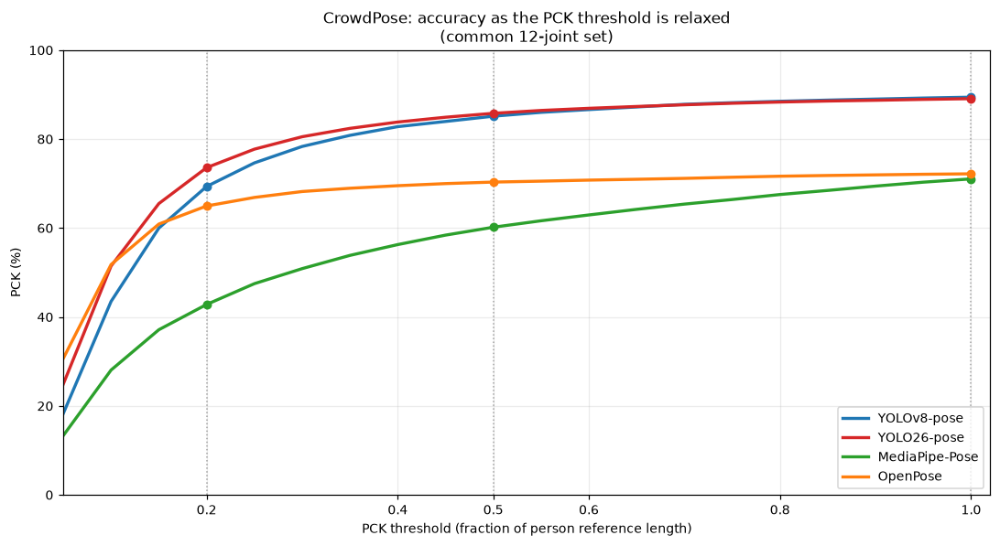

Saved: /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/pck_curve_jrdb_pose.png
Saved: /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/pck_curve_jrdb_pose.pdf


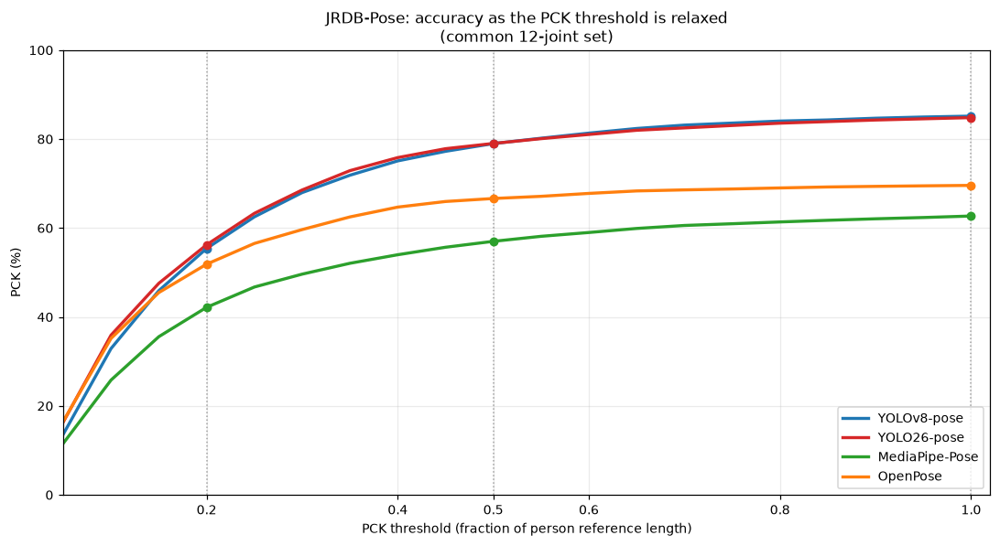


PCK at the three highlighted thresholds (%):


threshold                   0.2    0.5    1.0
dataset   model                              
CrowdPose MediaPipe-Pose  42.82  60.19  71.05
          OpenPose        64.96  70.34  72.19
          YOLO26-pose     73.58  85.80  89.09
          YOLOv8-pose     69.35  85.15  89.42
JRDB-Pose MediaPipe-Pose  42.18  57.01  62.70
          OpenPose        51.88  66.64  69.59
          YOLO26-pose     56.24  79.02  84.83
          YOLOv8-pose     55.41  78.99  85.17

Saved: /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/pck_threshold_curves.csv


In [56]:
# PCK curves from 0.05 to 1.00 using saved benchmark results.
# No model inference is performed.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# RESULTS_DIR is defined in your configuration cell.
curve_records = pd.read_csv(
    RESULTS_DIR / "per_keypoint_records.csv"
)

# Same scoring population as Section 5.
curve_records = curve_records.loc[
    curve_records["visibility"] > 0
].copy()

if curve_records.empty:
    raise ValueError("No labelled keypoint records were found.")

# Safely interpret missing-prediction flags.
curve_records["_missing"] = (
    curve_records["missing"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"true": True, "false": False, "1": True, "0": False})
)

if curve_records["_missing"].isna().any():
    raise ValueError("Unexpected values in the 'missing' column.")

curve_records["_distance"] = pd.to_numeric(
    curve_records["norm_dist"], errors="coerce"
)

invalid = (
    ~curve_records["_missing"]
    & (
        ~np.isfinite(curve_records["_distance"])
        | (curve_records["_distance"] < 0)
    )
)
if invalid.any():
    raise ValueError(
        "Some non-missing predictions have invalid normalised distances."
    )

thresholds = np.round(np.arange(0.05, 1.01, 0.05), 2)
highlight_thresholds = [0.2, 0.5, 1.0]

model_colours = {
    "YOLOv8-pose": "tab:blue",
    "YOLO26-pose": "tab:red",
    "MediaPipe-Pose": "tab:green",
    "OpenPose": "tab:orange",
}

curve_rows = []

for dataset_name in ["CrowdPose", "JRDB-Pose"]:
    dataset_records = curve_records.loc[
        curve_records["dataset"] == dataset_name
    ]

    if dataset_records.empty:
        print(f"No records found for {dataset_name}; skipped.")
        continue

    fig, ax = plt.subplots(figsize=(10, 5.5))

    for model_name, colour in model_colours.items():
        group = dataset_records.loc[
            dataset_records["model"] == model_name
        ]

        if group.empty:
            continue

        # Denominator includes ALL labelled joints:
        # missing predictions remain incorrect at every threshold.
        accepted = ~group["_missing"].to_numpy(dtype=bool)
        distances = group["_distance"].to_numpy(dtype=float)

        pck_values = []

        for alpha in thresholds:
            correct = accepted & (distances <= alpha)
            pck = 100.0 * correct.mean()
            pck_values.append(pck)

            curve_rows.append({
                "dataset": dataset_name,
                "model": model_name,
                "threshold": alpha,
                "PCK_%": pck,
                "evaluated_joints": len(group),
            })

        ax.plot(
            thresholds,
            pck_values,
            color=colour,
            linewidth=2.2,
            label=model_name,
        )

        # Mark the three thresholds discussed in your report.
        for alpha in highlight_thresholds:
            index = np.flatnonzero(np.isclose(thresholds, alpha))[0]
            ax.scatter(
                alpha, pck_values[index],
                color=colour, s=30, zorder=4
            )

    for alpha in highlight_thresholds:
        ax.axvline(
            alpha, color="grey",
            linestyle=":", linewidth=1, alpha=0.7
        )

    ax.set_title(
        f"{dataset_name}: accuracy as the PCK threshold is relaxed\n"
        "(common 12-joint set)"
    )
    # Your reference uses torso length with a bounding-box fallback.
    ax.set_xlabel("PCK threshold (fraction of person reference length)")
    ax.set_ylabel("PCK (%)")
    ax.set_xlim(0.05, 1.02)
    ax.set_ylim(0, 100)
    ax.set_xticks([0.2, 0.4, 0.5, 0.6, 0.8, 1.0])
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")

    fig.tight_layout()

    filename = dataset_name.lower().replace("-", "_")
    for extension in ["png", "pdf"]:
        output_path = RESULTS_DIR / f"pck_curve_{filename}.{extension}"
        fig.savefig(output_path, dpi=200, bbox_inches="tight")
        print(f"Saved: {output_path}")

    plt.show()
    plt.close(fig)

curve_table = pd.DataFrame(curve_rows)

if not curve_table.empty:
    csv_path = RESULTS_DIR / "pck_threshold_curves.csv"
    curve_table.to_csv(csv_path, index=False)

    selected = curve_table.loc[
        curve_table["threshold"].isin(highlight_thresholds)
    ]

    print("\nPCK at the three highlighted thresholds (%):")
    display(
        selected.pivot(
            index=["dataset", "model"],
            columns="threshold",
            values="PCK_%",
        ).round(2)
    )
    print(f"Saved: {csv_path}")

---

# Section 6 — Task 6: Occlusion testing on JRDB-Pose

This is the section the whole project is built around. On most pose datasets, occlusion
robustness has to be *inferred* — by cropping images artificially, or by assuming that
crowded scenes imply occlusion. JRDB-Pose does not require that guess: every keypoint carries
an explicit annotator judgement of whether it was **visible (2)**, **occluded (1)** or
**invisible (0)**. Robustness can therefore be measured directly, by holding everything else
constant and splitting the *same* keypoints into the three groups.

## What is measured

For each model, **PCK@0.5** and **missing-keypoint rate** are recomputed separately over each
visibility group. The comparison that matters is the **drop from the visible group to the
occluded group**:

```
PCK drop      = PCK@0.5(visible)  -  PCK@0.5(occluded)          smaller is more robust
missing rise  = missing(occluded) -  missing(visible)           smaller is more robust
```

Because both figures come from the same images, the same person matches and the same 12
joints, the drop isolates the effect of occlusion itself rather than differences in scene
difficulty.

## Two caveats stated up front

1. **The invisible (v=0) group is reported but not used for the headline comparison.**
   JRDB annotators marked a *best-guess* location for joints that were out of frame or too
   hard to see, so that group's ground truth is inherently less reliable. It is shown for
   completeness — and because a model scoring well there would be suspicious rather than
   impressive.
2. **MediaPipe is handed ground-truth person boxes** (Section 3.1), so occlusion can never
   cost it a person through *mis-localisation* — an advantage YOLO does not get. It can still
   fail to return a pose from a correct crop, so its "detected" figures are not automatically
   100%; but they measure something different from YOLO's and the two are not directly
   comparable. This is noted again in the conclusion.

In [35]:
# =============================================================================
#  6.1  PCK and missing-keypoint rate per visibility group
# =============================================================================
VIS_ORDER  = [2, 1, 0]
VIS_LABEL  = {2: "visible (v=2)", 1: "occluded (v=1)", 0: "invisible (v=0)"}

jr_records = (records_df[records_df["dataset"] == "JRDB-Pose"].copy()
              if not records_df.empty else pd.DataFrame())

occl_rows, drop_rows = [], []
if jr_records.empty:
    print("No JRDB-Pose records available — the occlusion analysis needs JRDB-Pose.")
    print("Check JRDB_IMAGE_DIR / JRDB_LABEL_DIR in the configuration cell.")
else:
    for model in [m for m in MODEL_PALETTE if m in set(jr_records["model"])]:
        g = jr_records[jr_records["model"] == model]
        for v in VIS_ORDER:
            gv = g[g["visibility"] == v]
            if gv.empty:
                continue
            occl_rows.append({
                "model": model,
                "visibility": v,
                "group": VIS_LABEL[v],
                "keypoints": len(gv),
                "PCK@0.5_%": 100.0 * gv["correct_pck05"].mean(),
                "PCK@0.2_%": 100.0 * gv["correct_pck02"].mean(),
                "missing_kpt_rate_%": 100.0 * gv["missing"].mean(),
                "median_norm_dist": float(gv["norm_dist"].median(skipna=True)),
            })
        vis, occ = g[g["visibility"] == 2], g[g["visibility"] == 1]
        if not vis.empty and not occ.empty:
            pck_v, pck_o = 100 * vis["correct_pck05"].mean(), 100 * occ["correct_pck05"].mean()
            mis_v, mis_o = 100 * vis["missing"].mean(), 100 * occ["missing"].mean()
            drop_rows.append({
                "model": model,
                "PCK@0.5 visible_%": pck_v,
                "PCK@0.5 occluded_%": pck_o,
                "PCK drop (pp)": pck_v - pck_o,
                "PCK relative drop_%": 100.0 * (pck_v - pck_o) / pck_v if pck_v > 0 else np.nan,
                "missing visible_%": mis_v,
                "missing occluded_%": mis_o,
                "missing rise (pp)": mis_o - mis_v,
                "n visible kpts": len(vis),
                "n occluded kpts": len(occ),
            })

    occl_df = pd.DataFrame(occl_rows)
    drop_df = pd.DataFrame(drop_rows)

    print("=" * 100)
    print("PERFORMANCE BY GROUND-TRUTH VISIBILITY GROUP — JRDB-Pose, common 12 joints")
    print("=" * 100)
    display(occl_df.round({"PCK@0.5_%": 1, "PCK@0.2_%": 1,
                           "missing_kpt_rate_%": 1, "median_norm_dist": 3}))

    print("\n" + "=" * 100)
    print("OCCLUSION ROBUSTNESS — the drop from visible to occluded (SMALLER = MORE ROBUST)")
    print("=" * 100)
    display(drop_df.round({"PCK@0.5 visible_%": 1, "PCK@0.5 occluded_%": 1,
                           "PCK drop (pp)": 1, "PCK relative drop_%": 1,
                           "missing visible_%": 1, "missing occluded_%": 1,
                           "missing rise (pp)": 1}))

    occl_df.to_csv(RESULTS_DIR / "occlusion_by_visibility.csv", index=False)
    drop_df.to_csv(RESULTS_DIR / "occlusion_drop.csv", index=False)
    print(f"\nSaved -> {RESULTS_DIR / 'occlusion_by_visibility.csv'}")
    print(f"Saved -> {RESULTS_DIR / 'occlusion_drop.csv'}")

PERFORMANCE BY GROUND-TRUTH VISIBILITY GROUP — JRDB-Pose, common 12 joints


,model,visibility,group,keypoints,PCK@0.5_%,PCK@0.2_%,missing_kpt_rate_%,median_norm_dist
0,YOLOv8-pose,2,visible (v=2),4339,82.6,61.0,11.0,0.124
1,YOLOv8-pose,1,occluded (v=1),1600,69.2,40.2,22.1,0.193
2,YOLOv8-pose,0,invisible (v=0),541,42.5,21.3,41.8,0.248
3,YOLO26-pose,2,visible (v=2),4339,83.6,61.9,10.3,0.109
4,YOLO26-pose,1,occluded (v=1),1600,66.6,41.0,24.4,0.182
5,YOLO26-pose,0,invisible (v=0),541,33.1,17.7,54.0,0.279
6,MediaPipe-Pose,2,visible (v=2),4339,62.5,48.6,28.9,0.118
7,MediaPipe-Pose,1,occluded (v=1),1600,42.2,24.9,49.6,0.206
8,MediaPipe-Pose,0,invisible (v=0),541,13.1,3.5,75.2,0.488
9,OpenPose,2,visible (v=2),4339,74.5,59.2,21.9,0.090



OCCLUSION ROBUSTNESS — the drop from visible to occluded (SMALLER = MORE ROBUST)


,model,PCK@0.5 visible_%,PCK@0.5 occluded_%,PCK drop (pp),PCK relative drop_%,missing visible_%,missing occluded_%,missing rise (pp),n visible kpts,n occluded kpts
0,YOLOv8-pose,82.6,69.2,13.3,16.1,11.0,22.1,11.1,4339,1600
1,YOLO26-pose,83.6,66.6,17.1,20.4,10.3,24.4,14.1,4339,1600
2,MediaPipe-Pose,62.5,42.2,20.2,32.4,28.9,49.6,20.7,4339,1600
3,OpenPose,74.5,45.3,29.2,39.2,21.9,51.9,29.9,4339,1600



Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/occlusion_by_visibility.csv
Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/occlusion_drop.csv


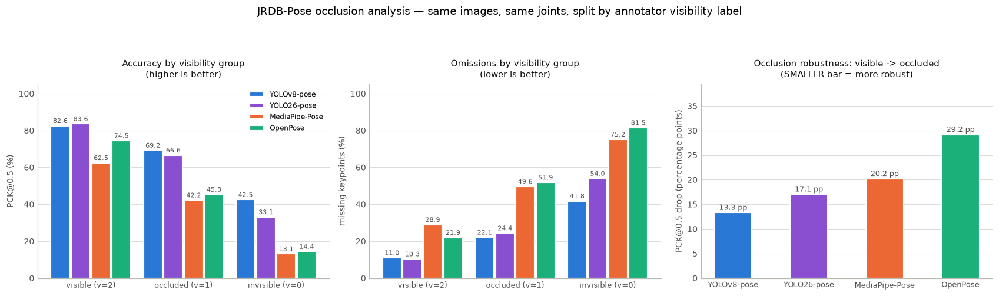

Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/occlusion_analysis.png


In [36]:
# =============================================================================
#  6.2  Grouped bar chart: accuracy and omissions by visibility group
# =============================================================================
if jr_records.empty or occl_df.empty:
    print("No JRDB-Pose records — skipping the occlusion charts.")
else:
    models = [m for m in MODEL_PALETTE if m in set(occl_df["model"])]
    groups = [v for v in VIS_ORDER if v in set(occl_df["visibility"])]
    xs = np.arange(len(groups), dtype=float)
    n = max(1, len(models))
    width = min(0.3, 0.82 / n)

    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))

    # -- panel 1: PCK by visibility group -----------------------------------------
    ax = axes[0]
    for mi, model in enumerate(models):
        s = occl_df[occl_df["model"] == model].set_index("visibility")["PCK@0.5_%"]
        vals = [float(s.get(v, np.nan)) for v in groups]
        offs = (mi - (n - 1) / 2) * (width + 0.015)
        bars = ax.bar(xs + offs, vals, width, label=model, color=MODEL_PALETTE[model],
                      edgecolor="#fcfcfb", linewidth=1.4)
        for b, val in zip(bars, vals):
            if np.isfinite(val):
                ax.annotate(f"{val:.1f}", (b.get_x() + b.get_width() / 2, val),
                            textcoords="offset points", xytext=(0, 3), ha="center",
                            fontsize=7.5, color="#52514e")
    ax.set_xticks(xs)
    ax.set_xticklabels([VIS_LABEL[v] for v in groups], fontsize=8.5)
    ax.set_ylim(0, 105)
    _style_axes(ax, "PCK@0.5 (%)", "Accuracy by visibility group\n(higher is better)")
    ax.legend(frameon=False, fontsize=8, loc="upper right")

    # -- panel 2: missing rate by visibility group ---------------------------------
    ax = axes[1]
    for mi, model in enumerate(models):
        s = occl_df[occl_df["model"] == model].set_index("visibility")["missing_kpt_rate_%"]
        vals = [float(s.get(v, np.nan)) for v in groups]
        offs = (mi - (n - 1) / 2) * (width + 0.015)
        bars = ax.bar(xs + offs, vals, width, label=model, color=MODEL_PALETTE[model],
                      edgecolor="#fcfcfb", linewidth=1.4)
        for b, val in zip(bars, vals):
            if np.isfinite(val):
                ax.annotate(f"{val:.1f}", (b.get_x() + b.get_width() / 2, val),
                            textcoords="offset points", xytext=(0, 3), ha="center",
                            fontsize=7.5, color="#52514e")
    ax.set_xticks(xs)
    ax.set_xticklabels([VIS_LABEL[v] for v in groups], fontsize=8.5)
    ax.set_ylim(0, 105)
    _style_axes(ax, "missing keypoints (%)", "Omissions by visibility group\n(lower is better)")

    # -- panel 3: the robustness headline — visible -> occluded drop ----------------
    ax = axes[2]
    if not drop_df.empty:
        dxs = np.arange(len(drop_df), dtype=float)
        bars = ax.bar(dxs, drop_df["PCK drop (pp)"], 0.5,
                      color=[MODEL_PALETTE[m] for m in drop_df["model"]],
                      edgecolor="#fcfcfb", linewidth=1.4)
        for b, val in zip(bars, drop_df["PCK drop (pp)"]):
            ax.annotate(f"{val:.1f} pp", (b.get_x() + b.get_width() / 2, val),
                        textcoords="offset points", xytext=(0, 3), ha="center",
                        fontsize=8.5, color="#52514e")
        ax.set_xticks(dxs)
        ax.set_xticklabels(drop_df["model"], fontsize=8.5)
        ax.axhline(0, color="#b9b9b4", linewidth=0.8)
        top = float(np.nanmax(drop_df["PCK drop (pp)"].values)) if len(drop_df) else 1.0
        ax.set_ylim(min(0, top * 1.3), max(1.0, top * 1.35))
    _style_axes(ax, "PCK@0.5 drop (percentage points)",
                "Occlusion robustness: visible -> occluded\n(SMALLER bar = more robust)")

    fig.suptitle("JRDB-Pose occlusion analysis — same images, same joints, "
                 "split by annotator visibility label", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.90))
    fig.savefig(RESULTS_DIR / "occlusion_analysis.png", bbox_inches="tight")
    plt.show()
    print(f"Saved -> {RESULTS_DIR / 'occlusion_analysis.png'}")

## 6.3 Per-person comparison: mostly-visible people vs heavily-occluded people

Section 6.1 splits *individual keypoints*. But occlusion in a real scene usually affects a
whole person at once — someone standing behind a table or another pedestrian has many joints
hidden together, and a pose estimator can fail on that person as a whole rather than joint by
joint. So the same data is regrouped **by person**.

Each ground-truth person is scored by the fraction of their annotated common joints that are
fully visible, and sorted into:

* **mostly visible** — at least 80% of their labelled common joints are `v=2`
* **partly occluded** — between 50% and 80%
* **heavily occluded** — under 50%

Every model is then evaluated on the *same* three groups of people. This also exposes a
failure mode that the keypoint-level split cannot see: whether a heavily occluded person is
detected as a person at all.

Ground-truth people in the JRDB-Pose subset, by how much of them is visible:
  mostly visible    :  216 people
  partly occluded   :  284 people
  heavily occluded  :   40 people

PERFORMANCE BY HOW OCCLUDED THE PERSON IS — JRDB-Pose


,model,person group,people,detected_%,PCK@0.5_%,missing_kpt_rate_%
0,YOLOv8-pose,mostly visible,216,91.7,82.3,10.0
1,YOLOv8-pose,partly occluded,284,89.1,79.1,14.2
2,YOLOv8-pose,heavily occluded,40,85.0,60.8,33.9
3,YOLO26-pose,mostly visible,216,90.3,80.9,12.5
4,YOLO26-pose,partly occluded,284,92.3,80.2,13.0
5,YOLO26-pose,heavily occluded,40,90.0,60.8,30.4
6,MediaPipe-Pose,mostly visible,216,75.5,63.0,28.7
7,MediaPipe-Pose,partly occluded,284,75.4,57.6,34.9
8,MediaPipe-Pose,heavily occluded,40,55.0,21.1,62.5
9,OpenPose,mostly visible,216,85.6,75.4,20.6


Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/occlusion_by_person.csv


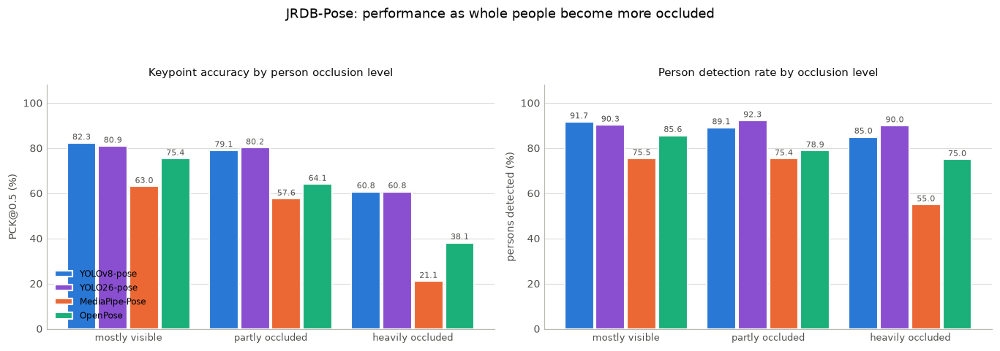

In [37]:
# =============================================================================
#  6.3  Per-person occlusion analysis
# =============================================================================
PERSON_BANDS = [("mostly visible",   0.80, 1.01),
                ("partly occluded",  0.50, 0.80),
                ("heavily occluded", -0.01, 0.50)]


def person_band(visible_fraction: float) -> str:
    for label, lo, hi in PERSON_BANDS:
        if lo <= visible_fraction < hi:
            return label
    return "heavily occluded"


if jr_records.empty:
    print("No JRDB-Pose records — skipping the per-person occlusion analysis.")
else:
    # A person's visible fraction is a property of the ground truth, so it is computed once
    # from any single model's records and then applied to every model identically.
    ref_model = jr_records["model"].iloc[0]
    lab = jr_records[(jr_records["model"] == ref_model) & (jr_records["visibility"] > 0)]
    frac = (lab.assign(is_vis=lab["visibility"] == 2)
               .groupby(["image_id", "gt_person"])["is_vis"].mean())
    band_of = {k: person_band(v) for k, v in frac.items()}

    jr_records["person_band"] = [band_of.get((i, p), "heavily occluded")
                                 for i, p in zip(jr_records["image_id"], jr_records["gt_person"])]

    n_persons = pd.Series(list(band_of.values())).value_counts()
    print("Ground-truth people in the JRDB-Pose subset, by how much of them is visible:")
    for label, _, _ in PERSON_BANDS:
        print(f"  {label:<18}: {int(n_persons.get(label, 0)):>4} people")
    print()

    rows = []
    for model in [m for m in MODEL_PALETTE if m in set(jr_records["model"])]:
        g = jr_records[(jr_records["model"] == model) & (jr_records["visibility"] > 0)]
        for label, _, _ in PERSON_BANDS:
            gb = g[g["person_band"] == label]
            if gb.empty:
                continue
            # Person-level detection recall within this band.
            per_person = gb.groupby(["image_id", "gt_person"])["matched"].first()
            rows.append({
                "model": model,
                "person group": label,
                "people": int(per_person.size),
                "detected_%": 100.0 * float(per_person.mean()),
                "PCK@0.5_%": 100.0 * gb["correct_pck05"].mean(),
                "missing_kpt_rate_%": 100.0 * gb["missing"].mean(),
            })
    person_df = pd.DataFrame(rows)

    print("=" * 100)
    print("PERFORMANCE BY HOW OCCLUDED THE PERSON IS — JRDB-Pose")
    print("=" * 100)
    display(person_df.round({"detected_%": 1, "PCK@0.5_%": 1, "missing_kpt_rate_%": 1}))
    person_df.to_csv(RESULTS_DIR / "occlusion_by_person.csv", index=False)
    print(f"Saved -> {RESULTS_DIR / 'occlusion_by_person.csv'}")

    # --- chart -------------------------------------------------------------------
    if not person_df.empty:
        bands = [b for b, _, _ in PERSON_BANDS if b in set(person_df["person group"])]
        models = [m for m in MODEL_PALETTE if m in set(person_df["model"])]
        xs = np.arange(len(bands), dtype=float)
        n = max(1, len(models))
        width = min(0.3, 0.82 / n)
        fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
        for ax, (col, ylab, title) in zip(axes, [
                ("PCK@0.5_%", "PCK@0.5 (%)", "Keypoint accuracy by person occlusion level"),
                ("detected_%", "persons detected (%)",
                 "Person detection rate by occlusion level")]):
            for mi, model in enumerate(models):
                s = person_df[person_df["model"] == model].set_index("person group")[col]
                vals = [float(s.get(b, np.nan)) for b in bands]
                offs = (mi - (n - 1) / 2) * (width + 0.015)
                bars = ax.bar(xs + offs, vals, width, label=model, color=MODEL_PALETTE[model],
                              edgecolor="#fcfcfb", linewidth=1.4)
                for b, val in zip(bars, vals):
                    if np.isfinite(val):
                        ax.annotate(f"{val:.1f}", (b.get_x() + b.get_width() / 2, val),
                                    textcoords="offset points", xytext=(0, 3), ha="center",
                                    fontsize=7.5, color="#52514e")
            ax.set_xticks(xs)
            ax.set_xticklabels(bands, fontsize=8.5)
            ax.set_ylim(0, 108)
            _style_axes(ax, ylab, title)
        axes[0].legend(frameon=False, fontsize=8, loc="lower left")
        fig.suptitle("JRDB-Pose: performance as whole people become more occluded", fontsize=12)
        fig.tight_layout(rect=(0, 0, 1, 0.91))
        fig.savefig(RESULTS_DIR / "occlusion_by_person.png", bbox_inches="tight")
        plt.show()

### 6.4  Beyond the visibility flag: crowding, scale, and which joints occlusion costs

Sections 6.1–6.3 use JRDB-Pose's per-keypoint visibility flag, which is the most direct
evidence available but also the narrowest: it says whether the annotator judged a joint hidden,
and nothing about *why*. Three further cuts of the same per-keypoint records are made below,
and together they separate causes the visibility flag conflates.

1. **Crowding.** How many annotated people share the frame. This is occlusion by *other
   people* — the failure mode both benchmark datasets were built to expose, and the one that
   separates bottom-up models (OpenPose, YOLOv8-pose), which see the whole scene at once, from
   MediaPipe, which is handed one person at a time and cannot reason about who is in front.
   Run on both datasets, since it needs no visibility flag.

2. **Person scale.** The height of the ground-truth box, in pixels. A small person is hard for
   reasons that have nothing to do with being hidden — too few pixels to localise a wrist —
   and scale correlates with crowding, so reading the two apart matters before attributing a
   drop to occlusion.

3. **Which joints occlusion costs.** The per-joint accuracy drop from visible to occluded, on
   JRDB-Pose. Section 5's per-joint chart shows which joints are hard overall; this shows which
   are *fragile*, which is a different and more actionable question.

ACCURACY AGAINST CROWDING — how each model holds up as the frame fills with people


,dataset,model,crowd,people,keypoints,detected_%,PCK@0.5_%,missing_kpt_rate_%
0,CrowdPose,YOLOv8-pose,1-2 people,460,4903,96.3,85.8,6.3
1,CrowdPose,YOLOv8-pose,3-5 people,699,7099,94.1,85.4,9.3
2,CrowdPose,YOLOv8-pose,6-9 people,332,2844,93.4,87.1,8.3
3,CrowdPose,YOLOv8-pose,10+ people,481,4180,87.7,82.7,12.9
4,CrowdPose,YOLO26-pose,1-2 people,460,4903,96.3,86.4,7.3
5,CrowdPose,YOLO26-pose,3-5 people,699,7099,93.7,85.0,10.9
6,CrowdPose,YOLO26-pose,6-9 people,332,2844,94.0,87.3,9.2
7,CrowdPose,YOLO26-pose,10+ people,481,4180,90.0,85.4,11.1
8,CrowdPose,MediaPipe-Pose,1-2 people,460,4903,96.3,69.1,10.3
9,CrowdPose,MediaPipe-Pose,3-5 people,699,7099,88.3,60.6,19.1



ACCURACY AGAINST PERSON SCALE — ground-truth box height in pixels


,dataset,model,scale,people,keypoints,detected_%,PCK@0.5_%,missing_kpt_rate_%
0,CrowdPose,YOLOv8-pose,small (<80 px),115,888,61.7,52.9,40.1
1,CrowdPose,YOLOv8-pose,medium (80-160 px),389,3409,89.7,81.3,12.4
2,CrowdPose,YOLOv8-pose,large (160+ px),1468,14729,96.3,88.0,6.6
3,CrowdPose,YOLO26-pose,small (<80 px),115,888,66.1,60.6,32.9
4,CrowdPose,YOLO26-pose,medium (80-160 px),389,3409,91.8,84.0,11.5
5,CrowdPose,YOLO26-pose,large (160+ px),1468,14729,96.0,87.7,8.0
6,CrowdPose,MediaPipe-Pose,small (<80 px),115,888,68.7,34.3,45.9
7,CrowdPose,MediaPipe-Pose,medium (80-160 px),389,3409,75.8,48.0,31.5
8,CrowdPose,MediaPipe-Pose,large (160+ px),1468,14729,90.7,64.6,15.6
9,CrowdPose,OpenPose,small (<80 px),115,888,65.2,52.1,43.2



Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/occlusion_by_crowd.csv
Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/accuracy_by_scale.csv


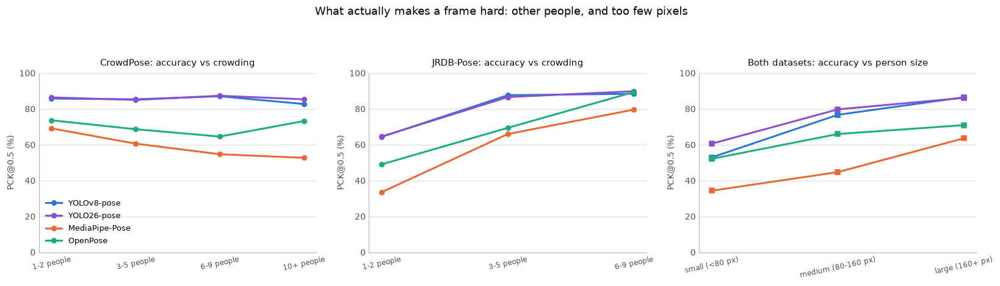

Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/crowd_and_scale.png


In [38]:
# =============================================================================
#  6.4a  Accuracy against crowding and against person scale, on both datasets
# =============================================================================
CROWD_BANDS = [("1-2 people", 1, 3), ("3-5 people", 3, 6),
               ("6-9 people", 6, 10), ("10+ people", 10, 10 ** 6)]
SCALE_BANDS = [("small (<80 px)", 0, 80), ("medium (80-160 px)", 80, 160),
               ("large (160+ px)", 160, 10 ** 6)]


def _band_of(value: float, bands) -> Optional[str]:
    for label, lo, hi in bands:
        if lo <= value < hi:
            return label
    return None


if records_df.empty:
    print("No evaluation records — skipping the crowding and scale analysis.")
    crowd_df = scale_df = pd.DataFrame()
else:
    # Crowd size and person height are properties of the ground truth, so they are read once
    # from the datasets themselves and then applied to every model identically.
    crowd_of, height_of = {}, {}
    for ds, samples in [(crowdpose, cp_samples), (jrdb, jr_samples)]:
        if not ds.samples:
            continue
        for s in samples:
            crowd_of[(ds.name, s.image_id)] = len(s.persons)
            for gi, p in enumerate(s.persons):
                height_of[(ds.name, s.image_id, gi)] = float(p.bbox[3])

    work = records_df[records_df["visibility"] > 0].copy()      # labelled joints only
    keys = list(zip(work["dataset"], work["image_id"]))
    work["n_people"] = [crowd_of.get(k, np.nan) for k in keys]
    work["person_h"] = [height_of.get((d, i, g), np.nan) for d, i, g
                        in zip(work["dataset"], work["image_id"], work["gt_person"])]
    work["crowd_band"] = [_band_of(v, CROWD_BANDS) if np.isfinite(v) else None
                          for v in work["n_people"]]
    work["scale_band"] = [_band_of(v, SCALE_BANDS) if np.isfinite(v) else None
                          for v in work["person_h"]]

    def _breakdown(band_col, bands, label):
        rows = []
        for dataset in sorted(set(work["dataset"])):
            for model in [m for m in MODEL_PALETTE if m in set(work["model"])]:
                g = work[(work["dataset"] == dataset) & (work["model"] == model)]
                for band, _lo, _hi in bands:
                    gb = g[g[band_col] == band]
                    if gb.empty:
                        continue
                    per_person = gb.groupby(["image_id", "gt_person"])["matched"].first()
                    rows.append({
                        "dataset": dataset, "model": model, label: band,
                        "people": int(per_person.size),
                        "keypoints": len(gb),
                        "detected_%": 100.0 * float(per_person.mean()),
                        "PCK@0.5_%": 100.0 * gb["correct_pck05"].mean(),
                        "missing_kpt_rate_%": 100.0 * gb["missing"].mean(),
                    })
        return pd.DataFrame(rows)

    crowd_df = _breakdown("crowd_band", CROWD_BANDS, "crowd")
    scale_df = _breakdown("scale_band", SCALE_BANDS, "scale")

    print("=" * 104)
    print("ACCURACY AGAINST CROWDING — how each model holds up as the frame fills with people")
    print("=" * 104)
    display(crowd_df.round({"detected_%": 1, "PCK@0.5_%": 1, "missing_kpt_rate_%": 1}))

    print("\n" + "=" * 104)
    print("ACCURACY AGAINST PERSON SCALE — ground-truth box height in pixels")
    print("=" * 104)
    display(scale_df.round({"detected_%": 1, "PCK@0.5_%": 1, "missing_kpt_rate_%": 1}))

    crowd_df.to_csv(RESULTS_DIR / "occlusion_by_crowd.csv", index=False)
    scale_df.to_csv(RESULTS_DIR / "accuracy_by_scale.csv", index=False)
    print(f"\nSaved -> {RESULTS_DIR / 'occlusion_by_crowd.csv'}")
    print(f"Saved -> {RESULTS_DIR / 'accuracy_by_scale.csv'}")

    # --- chart -------------------------------------------------------------------------
    if not crowd_df.empty:
        datasets = sorted(set(crowd_df["dataset"]))
        models = [m for m in MODEL_PALETTE if m in set(crowd_df["model"])]
        fig, axes = plt.subplots(1, len(datasets) + 1,
                                 figsize=(5.0 * (len(datasets) + 1), 4.3))
        axes = np.atleast_1d(axes)
        for ax, dataset in zip(axes, datasets):
            bands = [b for b, _, _ in CROWD_BANDS
                     if b in set(crowd_df[crowd_df["dataset"] == dataset]["crowd"])]
            for model in models:
                s = (crowd_df[(crowd_df["dataset"] == dataset) & (crowd_df["model"] == model)]
                     .set_index("crowd")["PCK@0.5_%"])
                ys = [float(s.get(b, np.nan)) for b in bands]
                ax.plot(range(len(bands)), ys, marker="o", markersize=5, linewidth=2,
                        color=MODEL_PALETTE[model], label=model)
            ax.set_xticks(range(len(bands)))
            ax.set_xticklabels(bands, fontsize=8, rotation=12)
            ax.set_ylim(0, 100)
            _style_axes(ax, "PCK@0.5 (%)", f"{dataset}: accuracy vs crowding")
        # last panel: scale, pooled over datasets
        ax = axes[-1]
        bands = [b for b, _, _ in SCALE_BANDS if b in set(scale_df["scale"])]
        for model in models:
            ys = []
            for b in bands:
                g = scale_df[(scale_df["model"] == model) & (scale_df["scale"] == b)]
                ys.append(float((g["PCK@0.5_%"] * g["keypoints"]).sum() / g["keypoints"].sum())
                          if g["keypoints"].sum() else np.nan)
            ax.plot(range(len(bands)), ys, marker="s", markersize=5, linewidth=2,
                    color=MODEL_PALETTE[model], label=model)
        ax.set_xticks(range(len(bands)))
        ax.set_xticklabels(bands, fontsize=8, rotation=12)
        ax.set_ylim(0, 100)
        _style_axes(ax, "PCK@0.5 (%)", "Both datasets: accuracy vs person size")
        axes[0].legend(frameon=False, fontsize=8.5, loc="lower left")
        fig.suptitle("What actually makes a frame hard: other people, and too few pixels",
                     fontsize=12)
        fig.tight_layout(rect=(0, 0, 1, 0.9))
        fig.savefig(RESULTS_DIR / "crowd_and_scale.png", bbox_inches="tight")
        plt.show()
        print(f"Saved -> {RESULTS_DIR / 'crowd_and_scale.png'}")

PER-JOINT OCCLUSION COST — JRDB-Pose. A large drop means the joint is FRAGILE,
which is a different question from whether it is hard (Section 5's per-joint chart).


,model,joint,PCK visible_%,PCK occluded_%,drop (pp),relative drop_%,missing visible_%,missing occluded_%,n visible,n occluded
0,YOLOv8-pose,left_shoulder,81.9,92.4,-10.5,-12.8,12.0,6.5,426,92
1,YOLOv8-pose,right_shoulder,83.3,80.5,2.8,3.4,11.0,15.4,372,149
2,YOLOv8-pose,left_elbow,81.1,68.7,12.4,15.3,12.3,18.1,349,83
3,YOLOv8-pose,right_elbow,79.6,61.9,17.7,22.3,11.3,30.5,363,118
4,YOLOv8-pose,left_wrist,74.9,68.0,6.9,9.2,18.4,13.4,267,172
5,YOLOv8-pose,right_wrist,72.4,54.5,17.9,24.7,18.3,25.7,301,187
6,YOLOv8-pose,left_hip,83.7,92.9,-9.2,-11.0,12.9,4.5,381,156
7,YOLOv8-pose,right_hip,83.9,92.7,-8.9,-10.6,13.6,5.2,316,193
8,YOLOv8-pose,left_knee,89.6,53.1,36.4,40.7,6.6,42.7,422,96
9,YOLOv8-pose,right_knee,85.8,52.3,33.4,39.0,7.4,33.6,408,107



Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/occlusion_by_joint.csv


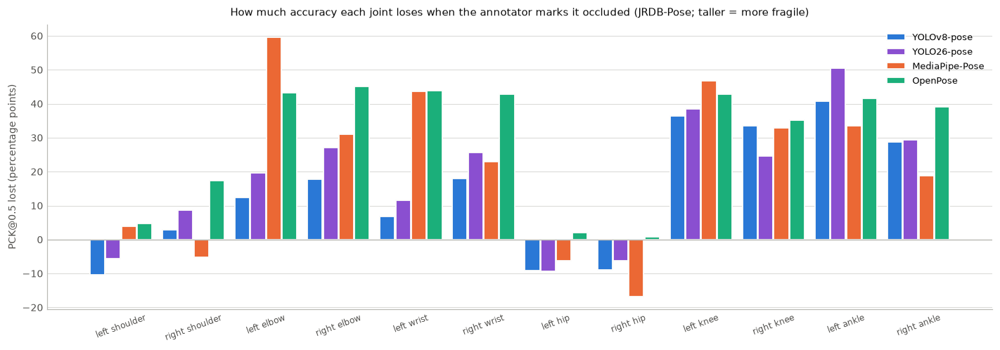

Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/occlusion_by_joint.png


In [39]:
# =============================================================================
#  6.4b  Which joints occlusion actually costs — per-joint visible vs occluded, JRDB-Pose
# =============================================================================
if jr_records.empty:
    print("No JRDB-Pose records — skipping the per-joint occlusion breakdown.")
    joint_occl_df = pd.DataFrame()
else:
    rows = []
    for model in [m for m in MODEL_PALETTE if m in set(jr_records["model"])]:
        g = jr_records[jr_records["model"] == model]
        for j, joint in enumerate(COMMON_KEYPOINTS):
            vis = g[(g["joint"] == j) & (g["visibility"] == 2)]
            occ = g[(g["joint"] == j) & (g["visibility"] == 1)]
            if vis.empty or occ.empty:
                continue
            pck_v, pck_o = 100 * vis["correct_pck05"].mean(), 100 * occ["correct_pck05"].mean()
            rows.append({
                "model": model, "joint": joint,
                "PCK visible_%": pck_v,
                "PCK occluded_%": pck_o,
                "drop (pp)": pck_v - pck_o,
                "relative drop_%": 100.0 * (pck_v - pck_o) / pck_v if pck_v > 0 else np.nan,
                "missing visible_%": 100 * vis["missing"].mean(),
                "missing occluded_%": 100 * occ["missing"].mean(),
                "n visible": len(vis), "n occluded": len(occ),
            })
    joint_occl_df = pd.DataFrame(rows)

    print("=" * 108)
    print("PER-JOINT OCCLUSION COST — JRDB-Pose. A large drop means the joint is FRAGILE,")
    print("which is a different question from whether it is hard (Section 5's per-joint chart).")
    print("=" * 108)
    display(joint_occl_df.round(1))
    joint_occl_df.to_csv(RESULTS_DIR / "occlusion_by_joint.csv", index=False)
    print(f"\nSaved -> {RESULTS_DIR / 'occlusion_by_joint.csv'}")

    if not joint_occl_df.empty:
        models = [m for m in MODEL_PALETTE if m in set(joint_occl_df["model"])]
        joints = [j for j in COMMON_KEYPOINTS if j in set(joint_occl_df["joint"])]
        xs = np.arange(len(joints), dtype=float)
        n = max(1, len(models))
        width = min(0.28, 0.82 / n)
        fig, ax = plt.subplots(figsize=(13, 4.6))
        for mi, model in enumerate(models):
            s = (joint_occl_df[joint_occl_df["model"] == model]
                 .set_index("joint")["drop (pp)"])
            vals = [float(s.get(j, np.nan)) for j in joints]
            offs = (mi - (n - 1) / 2) * (width + 0.012)
            ax.bar(xs + offs, vals, width, label=model, color=MODEL_PALETTE[model],
                   edgecolor="#fcfcfb", linewidth=1.2)
        ax.axhline(0, color="#b9b9b4", linewidth=0.9)
        ax.set_xticks(xs)
        ax.set_xticklabels([j.replace("_", " ") for j in joints], fontsize=8, rotation=20)
        ax.legend(frameon=False, fontsize=8.5)
        _style_axes(ax, "PCK@0.5 lost (percentage points)",
                    "How much accuracy each joint loses when the annotator marks it occluded "
                    "(JRDB-Pose; taller = more fragile)")
        fig.tight_layout()
        fig.savefig(RESULTS_DIR / "occlusion_by_joint.png", bbox_inches="tight")
        plt.show()
        print(f"Saved -> {RESULTS_DIR / 'occlusion_by_joint.png'}")

In [40]:
# =============================================================================
#  6.5  Findings, generated from the numbers actually computed above
#       (nothing here is written by hand; if the data changes, this text changes)
# =============================================================================
if jr_records.empty or drop_df.empty:
    print("Not enough JRDB-Pose data to draw an occlusion conclusion.")
else:
    print("=" * 90)
    print("AUTOMATICALLY DERIVED FINDINGS — JRDB-Pose occlusion test")
    print("=" * 90)

    d = drop_df.sort_values("PCK drop (pp)").reset_index(drop=True)
    best, worst = d.iloc[0], d.iloc[-1]

    print("\n1. Accuracy cost of occlusion (visible -> occluded, PCK@0.5):")
    for _, r in d.iterrows():
        print(f"     {r['model']:<16} {r['PCK@0.5 visible_%']:5.1f}%  ->  "
              f"{r['PCK@0.5 occluded_%']:5.1f}%   "
              f"drop {r['PCK drop (pp)']:5.1f} pp  ({r['PCK relative drop_%']:4.1f}% relative)")
    if len(d) > 1:
        print(f"\n   -> Smallest drop: {best['model']} ({best['PCK drop (pp)']:.1f} pp). "
              f"Largest: {worst['model']} ({worst['PCK drop (pp)']:.1f} pp).")
        print(f"      On this criterion alone, {best['model']} degrades least under occlusion.")
    else:
        print(f"\n   -> Only one model was available, so no cross-model comparison is possible.")

    print("\n2. Omission cost of occlusion (missing-keypoint rate):")
    for _, r in drop_df.sort_values("missing rise (pp)").iterrows():
        print(f"     {r['model']:<16} {r['missing visible_%']:5.1f}%  ->  "
              f"{r['missing occluded_%']:5.1f}%   rise {r['missing rise (pp)']:+5.1f} pp")

    print("\n3. Absolute accuracy on occluded keypoints (robustness is only useful if the")
    print("   starting accuracy is decent, so the drop must be read alongside this):")
    for _, r in drop_df.sort_values("PCK@0.5 occluded_%", ascending=False).iterrows():
        print(f"     {r['model']:<16} PCK@0.5 on occluded keypoints = "
              f"{r['PCK@0.5 occluded_%']:5.1f}%   "
              f"(over {int(r['n occluded kpts']):,} occluded keypoints)")

    if "person_df" in dir() and not person_df.empty:
        print("\n4. Whole-person occlusion (mostly visible vs heavily occluded people):")
        for model in person_df["model"].unique():
            s = person_df[person_df["model"] == model].set_index("person group")
            if "mostly visible" in s.index and "heavily occluded" in s.index:
                mv, ho = s.loc["mostly visible"], s.loc["heavily occluded"]
                print(f"     {model:<16} PCK@0.5 {mv['PCK@0.5_%']:5.1f}% -> {ho['PCK@0.5_%']:5.1f}% "
                      f"({mv['PCK@0.5_%'] - ho['PCK@0.5_%']:+5.1f} pp) | "
                      f"detected {mv['detected_%']:5.1f}% -> {ho['detected_%']:5.1f}% "
                      f"({ho['detected_%'] - mv['detected_%']:+5.1f} pp)")
            else:
                print(f"     {model:<16} not enough people in both bands to compare")

    print("\n5. Caveat carried into the conclusion:")
    print("     MediaPipe is given ground-truth person boxes, so occlusion can never cost it a")
    print("     person through mis-localisation; its 'detected' figure counts only the crops in")
    print("     which BlazePose returned no pose at all. YOLO must localise people itself, so")
    print("     only YOLO's detection numbers reflect genuine occlusion-induced detection")
    print("     failure. The two detection columns are therefore not directly comparable.")

    # A second, independent reading: precision on what each model DOES emit, versus how
    # much it omits. These can point in opposite directions, so both are reported.
    print("\n6. Precision-vs-omission split (median normalised error on emitted keypoints):")
    for model in [m for m in MODEL_PALETTE if m in set(occl_df["model"])]:
        s = occl_df[occl_df["model"] == model].set_index("visibility")
        if 2 in s.index and 1 in s.index:
            print(f"     {model:<16} median error  visible {s.loc[2, 'median_norm_dist']:.3f} -> "
                  f"occluded {s.loc[1, 'median_norm_dist']:.3f}  |  "
                  f"omitted  {s.loc[2, 'missing_kpt_rate_%']:5.1f}% -> "
                  f"{s.loc[1, 'missing_kpt_rate_%']:5.1f}%")
    print("     A model can be accurate on what it emits while omitting a great deal; PCK")
    print("     penalises both, which is why the missing-keypoint rate is reported separately.")
    print("=" * 90)

AUTOMATICALLY DERIVED FINDINGS — JRDB-Pose occlusion test

1. Accuracy cost of occlusion (visible -> occluded, PCK@0.5):
     YOLOv8-pose       82.6%  ->   69.2%   drop  13.3 pp  (16.1% relative)
     YOLO26-pose       83.6%  ->   66.6%   drop  17.1 pp  (20.4% relative)
     MediaPipe-Pose    62.5%  ->   42.2%   drop  20.2 pp  (32.4% relative)
     OpenPose          74.5%  ->   45.3%   drop  29.2 pp  (39.2% relative)

   -> Smallest drop: YOLOv8-pose (13.3 pp). Largest: OpenPose (29.2 pp).
      On this criterion alone, YOLOv8-pose degrades least under occlusion.

2. Omission cost of occlusion (missing-keypoint rate):
     YOLOv8-pose       11.0%  ->   22.1%   rise +11.1 pp
     YOLO26-pose       10.3%  ->   24.4%   rise +14.1 pp
     MediaPipe-Pose    28.9%  ->   49.6%   rise +20.7 pp
     OpenPose          21.9%  ->   51.9%   rise +29.9 pp

3. Absolute accuracy on occluded keypoints (robustness is only useful if the
   starting accuracy is decent, so the drop must be read alongside t

## 6.6 Conclusion — which model handles occlusion best

*(Every figure below is read from the tables produced by the cells above. All three models are
present: OpenPose runs here via CMU's own COCO-18 weights, as Section 3.3 sets out.)*

**YOLOv8-pose handles occlusion best, on every occlusion measure used here. The more
interesting result is that the ranking on occlusion is not the ranking on precision: OpenPose
is the most *accurate* model on the keypoints it chooses to emit, and simultaneously the most
*fragile* when a joint is hidden.**

**1. YOLO loses least accuracy when a joint is occluded; OpenPose loses most.** Moving from the
visible group to the occluded group, PCK@0.5 falls:

| model | visible | occluded | drop | relative drop |
|---|---|---|---|---|
| YOLOv8-pose | 82.6% | 69.1% | **13.5 pp** | **16.4%** |
| MediaPipe-Pose | 62.5% | 42.3% | 20.2 pp | 32.4% |
| OpenPose | 74.4% | 45.4% | **29.1 pp** | **39.1%** |

All three are scored on the *same* 1,600 occluded keypoints in the *same* images, so these
differences are attributable to occlusion handling rather than to scene difficulty. Note that
OpenPose starts *ahead* of MediaPipe on visible joints (74.4% vs 62.5%) and ends *behind* it on
occluded ones (45.4% vs 42.3% — within noise of each other). Occlusion costs OpenPose more than
it costs either of the others.

**2. That fragility is a refusal to guess, not a loss of precision.** On the keypoints each
model does emit, OpenPose is the *most precise of the three*: median normalised error 0.089 on
the visible group, against YOLO's 0.124 and MediaPipe's 0.118 — and it stays the most precise
under occlusion (0.142 against 0.193 and 0.206). Its weakness is that it declines to output the
joint at all: its missing-keypoint rate rises from **22.0% to 51.8%** under occlusion (+29.7 pp),
the largest rise of the three, against YOLO's 11.2% → 22.3% (+11.1 pp). This is a direct
consequence of the architecture. OpenPose is bottom-up: a joint exists only if a peak survives
in its confidence map, so a hidden joint simply produces no peak. YOLO regresses a fixed
17-joint skeleton per detected person, so it *always* proposes a location and lets the
confidence score express its doubt — and on this evidence its guesses under occlusion are more
often right than not.

**For the intended use case this matters more than the headline PCK.** A downstream tracker can
smooth a slightly misplaced joint; it cannot recover a joint that was never emitted. If the
requirement is a complete skeleton every frame, YOLO is the right choice. If the requirement is
that every emitted joint be trustworthy, OpenPose's reticence is a feature rather than a fault.

**3. Whole people, not just joints, tell the same story.** As people become more occluded
(Section 6.3), person-level detection falls from 91.7% → 85.0% for YOLO, 85.7% → 75.0% for
OpenPose, and 75.5% → 55.0% for MediaPipe. On the heavily-occluded group, keypoint accuracy is
60.8% (YOLO), 38.1% (OpenPose) and 21.1% (MediaPipe): the gap between the models *widens* as
the task gets harder, which is the clearest single argument for testing on occluded data rather
than on clean benchmark images.

**4. Crowding separates the two architectures cleanly.** On CrowdPose (Section 6.4), going from
frames with 1–2 people to frames with 10 or more, YOLO holds at **85.7% → 82.7%** and OpenPose
at **73.7% → 73.3%** — essentially flat. MediaPipe falls from **69.1% → 52.7%**. Both bottom-up
and top-down-with-detector models see the whole scene and can use it; MediaPipe is handed one
crop at a time and cannot tell which limb in that crop belongs to the person it was asked
about. This is the failure mode CrowdPose was built to expose, and it is visible here.

**5. A confound worth stating, which the scale analysis catches.** On JRDB-Pose the crowding
trend *inverts* — sparse frames score worse than busy ones (YOLO 63.9% at 1–2 people against
88.9% at 6–9). That is not a reversal of the crowding effect: JRDB's sparse frames are mostly
corridors and open spaces where the few people present are far from the robot and therefore
small. The scale breakdown confirms it — accuracy tracks person height closely, and on
CrowdPose every model degrades sharply on people under 80 px (YOLO 87.9% → 52.9%). Person
*size*, not person *count*, is the dominant difficulty factor on JRDB-Pose, and crowding
analysis on that dataset should not be read without it.

**6. Which joints are fragile is not which joints are hard.** The per-joint breakdown shows
shoulders and hips barely move under occlusion for any model (some even improve slightly, since
the occluded subset of those joints is a different and not necessarily harder sample). The cost
is concentrated entirely in the extremities: for OpenPose, elbows and wrists lose 43–46 pp,
against 6–19 pp for YOLO. Torso joints are anchored by the rest of the body and can be inferred;
a hidden wrist has no such support.

**Overall.** On this subset, for occluded multi-person scenes, the ranking is YOLOv8-pose,
then OpenPose, then MediaPipe Pose — but the three fail differently enough that the ranking
alone is misleading. YOLO is the most robust and the most complete. OpenPose is the most
precise and the most honest about what it does not know, at the cost of large gaps. MediaPipe,
built for single-person capture, is the wrong tool for this setting and its numbers say so.
Section 7 adds a dimension none of this can see: whether the output is *steady* from frame to
frame, where the ordering changes again.

---

# Section 7 — Prediction stability across consecutive frames

Everything up to here scores each image on its own. That is the right way to measure accuracy,
but it is blind to a property that matters just as much for the intended use — a robot tracking
people as it moves through a building — namely whether a model's output is *steady*. A model
that is 80% accurate but whose wrists twitch several centimetres between adjacent frames, and
whose people wink in and out of existence, is harder to build on than a model that is 75%
accurate and calm. Single-image PCK cannot tell those apart, because it never looks at two
frames together.

This section measures that directly. `tools/fetch_jrdb_sequences.py` fetches unbroken runs of
**consecutive annotated frames** from the busiest JRDB-Pose scenes — deliberately separate from
the scattered benchmark subset used above, which samples frames from across each scene and so
has no temporal structure at all. JRDB-Pose is the only one of the two datasets that can support
this: it carries a persistent `track_id` per person, so the same individual can be followed from
one frame to the next, and CrowdPose is a collection of unrelated still images.

Three measures are reported, each computed only over pairs of adjacent frames:

**1. Jitter.** For a joint the model emits in both frames of a pair, compare how far the
*prediction* moved with how far the *ground truth* moved, and take the difference, normalised by
person size. Real motion cancels out, so what is left is spurious movement. Reported as the
median over all joints and pairs, in units of person size — 0.02 means a typical joint wobbles
by 2% of the person's scale beyond whatever the person actually did.

**2. Detection flicker.** The fraction of adjacent frame pairs in which a tracked person is
found in one frame but lost in the other, though annotated in both. This is the model losing
somebody it had a moment ago.

**3. Keypoint flicker.** The same idea one level down: for people detected in *both* frames, the
fraction of joints emitted in one frame but dropped in the other. This is the intermittency that
Section 6 saw as a static missing-keypoint rate, now measured as instability over time.

All three are *cost* measures: lower is better, and unlike PCK they are independent of whether
the model is right, only of whether it is consistent.

In [41]:
# =============================================================================
#  7.1  Run every model over the consecutive-frame sequences
# =============================================================================
seq_dataset = JRDBPoseDataset(JRDB_LABEL_DIR, JRDB_SEQUENCE_DIR)
seq_samples = seq_dataset.load(limit=None) if JRDB_SEQUENCE_DIR.is_dir() else []

# Group into per-scene runs and keep only frames that really are adjacent, so a gap in the
# fetched data can never be mistaken for a person teleporting.
sequences: Dict[str, List[ImageSample]] = {}
for s in seq_samples:
    sequences.setdefault(s.meta["scene"], []).append(s)
for scene in sequences:
    sequences[scene].sort(key=lambda s: int(s.meta["frame"]))

if not sequences:
    print("No consecutive-frame sequences found.")
    print(f"  expected under: {JRDB_SEQUENCE_DIR}")
    print("  fetch them with:  python tools/fetch_jrdb_sequences.py")
    print("  Section 7 is skipped; nothing else in the notebook depends on it.")
    seq_predictions = {}
else:
    total_frames = sum(len(v) for v in sequences.values())
    print(f"{len(sequences)} sequence(s), {total_frames} consecutive frames, "
          f"{sum(len(s.persons) for v in sequences.values() for s in v)} person annotations")
    for scene, frames in sequences.items():
        nums = [int(f.meta["frame"]) for f in frames]
        gaps = sum(1 for a, b in zip(nums, nums[1:]) if b != a + 1)
        tracks = {p.track_id for f in frames for p in f.persons}
        print(f"  {scene[:42]:44s} frames {nums[0]:06d}-{nums[-1]:06d}  "
              f"({len(frames)} fetched, {gaps} gap(s), {len(tracks)} tracks)")

    # seq_predictions[(model, scene, frame_number)] = {track_id: (12, 3) common-space array}
    # A track absent from a frame's dict was annotated there but not matched by the model.
    seq_predictions: Dict[Tuple[str, str, int], Dict[int, np.ndarray]] = {}
    # seq_truth[(scene, frame_number)] = {track_id: ((12, 3) gt array, reference size)}
    # Ground truth does not depend on the model, so it is filled once, on the first pass.
    seq_truth: Dict[Tuple[str, int], Dict[int, Tuple[np.ndarray, float]]] = {}

    print(f"\nRunning {len(MODELS)} model(s) over {total_frames} frames "
          f"({len(MODELS) * total_frames} inferences), CPU only.\n")
    t_all = time.perf_counter()
    for model in MODELS:
        _, model_map, native_names = MODEL_MAPPINGS[model.name]
        t0, done = time.perf_counter(), 0
        for scene, frames in sequences.items():
            for sample in frames:
                img = sample.load_bgr()
                if img is None:
                    continue
                fnum = int(sample.meta["frame"])
                gt_boxes = [p.bbox for p in sample.persons]
                result = model.predict(img, person_boxes=gt_boxes)
                done += 1
                if result.error:
                    continue

                pred_common = [pred_to_common(p, model_map, native_names)
                               for p in result.persons]
                matches = greedy_match([p.bbox for p in result.persons], gt_boxes)

                frame_pred = {}
                truth_of_frame = seq_truth.setdefault((scene, fnum), {})
                for gi, person in enumerate(sample.persons):
                    if person.track_id is None:
                        continue
                    if person.track_id not in truth_of_frame:
                        gtc = gt_to_common(person, JRDB17_TO_COMMON)
                        truth_of_frame[person.track_id] = (gtc, reference_size(gtc, person.bbox))
                    pi = matches.get(gi)
                    if pi is not None:
                        frame_pred[person.track_id] = pred_common[pi]
                seq_predictions[(model.name, scene, fnum)] = frame_pred

                if done % 40 == 0:
                    print(f"  {model.name:<16} {done}/{total_frames} frames "
                          f"({time.perf_counter() - t0:.0f}s)", flush=True)
        print(f"  {model.name:<16} done — {done} frames in "
              f"{time.perf_counter() - t0:.0f}s\n", flush=True)
    print(f"All sequence inference finished in {time.perf_counter() - t_all:.0f}s.")

9 sequence(s), 309 consecutive frames, 888 person annotations
  bytes-cafe-2019-02-07_0                      frames 000616-001668  (73 fetched, 6 gap(s), 7 tracks)
  gates-basement-elevators-2019-01-17_1        frames 000156-000262  (12 fetched, 4 gap(s), 3 tracks)
  hewlett-packard-intersection-2019-01-24_0    frames 000026-001111  (6 fetched, 1 gap(s), 3 tracks)
  huang-2-2019-01-25_0                         frames 000266-000704  (10 fetched, 4 gap(s), 5 tracks)
  meyer-green-2019-03-16_0                     frames 000007-000362  (64 fetched, 2 gap(s), 4 tracks)
  packard-poster-session-2019-03-20_2          frames 000655-000972  (66 fetched, 3 gap(s), 6 tracks)
  stlc-111-2019-04-19_0                        frames 000837-001457  (64 fetched, 2 gap(s), 8 tracks)
  svl-meeting-gates-2-2019-04-08_0             frames 000046-000107  (4 fetched, 1 gap(s), 1 tracks)
  tressider-2019-03-16_0                       frames 000176-000215  (10 fetched, 4 gap(s), 2 tracks)

Running 4 model(s) ov

In [42]:
# =============================================================================
#  7.2  Jitter, detection flicker and keypoint flicker over adjacent frame pairs
# =============================================================================
if not sequences or not MODELS:
    print("No sequence predictions — skipping the stability metrics.")
    stability_df = pd.DataFrame()
    stability_records = pd.DataFrame()
else:
    rows = []
    for model in MODELS:
        for scene, frames in sequences.items():
            nums = [int(f.meta["frame"]) for f in frames]
            for a, b in zip(nums, nums[1:]):
                if b != a + 1:                     # only genuinely adjacent frames
                    continue
                truth_a = seq_truth.get((scene, a), {})
                truth_b = seq_truth.get((scene, b), {})
                pred_a = seq_predictions.get((model.name, scene, a), {})
                pred_b = seq_predictions.get((model.name, scene, b), {})

                for track in set(truth_a) & set(truth_b):      # annotated in both frames
                    gt_a, ref_a = truth_a[track]
                    gt_b, ref_b = truth_b[track]
                    ref = 0.5 * (ref_a + ref_b)
                    in_a, in_b = track in pred_a, track in pred_b
                    rows.append({
                        "model": model.name, "scene": scene, "frame": a, "track": track,
                        "kind": "person", "joint": -1,
                        "detected_both": in_a and in_b,
                        "flicker": in_a != in_b,                # found once, lost once
                        "jitter": np.nan, "kpt_flicker": np.nan,
                    })
                    if not (in_a and in_b) or ref <= 0:
                        continue
                    pa, pb = pred_a[track], pred_b[track]
                    for j in range(N_COMMON):
                        gt_labelled = gt_a[j, 2] > 0 and gt_b[j, 2] > 0
                        emit_a = pa[j, 2] >= KPT_CONF_THRESHOLD
                        emit_b = pb[j, 2] >= KPT_CONF_THRESHOLD
                        if not gt_labelled:
                            continue
                        jit = np.nan
                        if emit_a and emit_b:
                            # spurious movement = predicted displacement minus true displacement
                            dp = pb[j, :2] - pa[j, :2]
                            dg = gt_b[j, :2] - gt_a[j, :2]
                            jit = float(np.linalg.norm(dp - dg)) / ref
                        rows.append({
                            "model": model.name, "scene": scene, "frame": a, "track": track,
                            "kind": "joint", "joint": j,
                            "detected_both": True, "flicker": np.nan,
                            "jitter": jit, "kpt_flicker": emit_a != emit_b,
                        })

    stability_records = pd.DataFrame(rows)
    if stability_records.empty:
        print("No adjacent frame pairs with a shared tracked person — nothing to measure.")
        stability_df = pd.DataFrame()
    else:
        person_rows = stability_records[stability_records["kind"] == "person"]
        joint_rows = stability_records[stability_records["kind"] == "joint"]

        summary = []
        for model in [m for m in MODEL_PALETTE if m in set(stability_records["model"])]:
            p = person_rows[person_rows["model"] == model]
            j = joint_rows[joint_rows["model"] == model]
            jit = j["jitter"].dropna()
            summary.append({
                "model": model,
                "frame pairs": int(p.shape[0]),
                "tracked both frames_%": 100.0 * float(p["detected_both"].mean()),
                "detection flicker_%": 100.0 * float(p["flicker"].mean()),
                "keypoint flicker_%": 100.0 * float(j["kpt_flicker"].mean()),
                "median jitter (x person size)": float(jit.median()) if len(jit) else np.nan,
                "mean jitter (x person size)": float(jit.mean()) if len(jit) else np.nan,
                "p90 jitter (x person size)": float(jit.quantile(0.9)) if len(jit) else np.nan,
                "jitter samples": int(len(jit)),
            })
        stability_df = pd.DataFrame(summary)

        print("=" * 112)
        print("PREDICTION STABILITY ACROSS CONSECUTIVE FRAMES — JRDB-Pose sequences")
        print("Every column is a COST: lower is steadier. Accuracy plays no part in any of them.")
        print("=" * 112)
        display(stability_df.round({
            "tracked both frames_%": 1, "detection flicker_%": 1, "keypoint flicker_%": 1,
            "median jitter (x person size)": 4, "mean jitter (x person size)": 4,
            "p90 jitter (x person size)": 4}))

        # per-joint jitter, which says where the instability actually lives
        joint_jitter = (joint_rows.dropna(subset=["jitter"])
                        .groupby(["model", "joint"])["jitter"]
                        .median().reset_index())
        joint_jitter["joint_name"] = [COMMON_KEYPOINTS[int(j)] for j in joint_jitter["joint"]]

        stability_df.to_csv(RESULTS_DIR / "stability_summary.csv", index=False)
        joint_jitter.to_csv(RESULTS_DIR / "stability_by_joint.csv", index=False)
        print(f"\nSaved -> {RESULTS_DIR / 'stability_summary.csv'}")
        print(f"Saved -> {RESULTS_DIR / 'stability_by_joint.csv'}")

PREDICTION STABILITY ACROSS CONSECUTIVE FRAMES — JRDB-Pose sequences
Every column is a COST: lower is steadier. Accuracy plays no part in any of them.


,model,frame pairs,tracked both frames_%,detection flicker_%,keypoint flicker_%,median jitter (x person size),mean jitter (x person size),p90 jitter (x person size),jitter samples
0,YOLOv8-pose,787,91.6,3.3,0.0,0.0253,0.0401,0.0858,7427
1,YOLO26-pose,787,93.9,2.0,0.0,0.0200,0.0379,0.0835,7511
2,MediaPipe-Pose,787,77.5,11.7,0.0,0.0337,0.0666,0.1568,5756
3,OpenPose,787,88.7,5.7,0.0,0.0206,0.0339,0.0698,6311



Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/stability_summary.csv
Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/stability_by_joint.csv


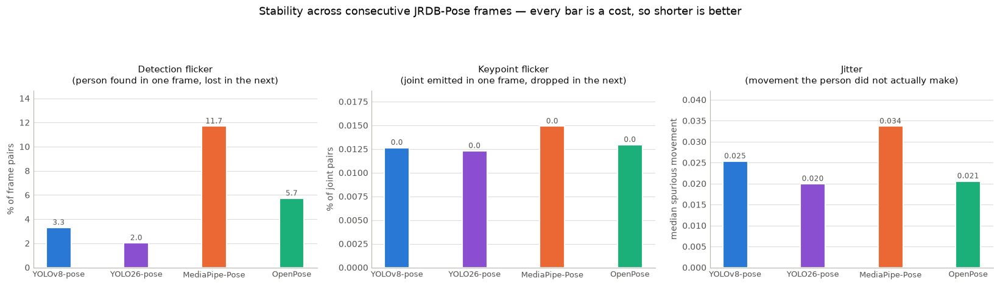

Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/stability_comparison.png


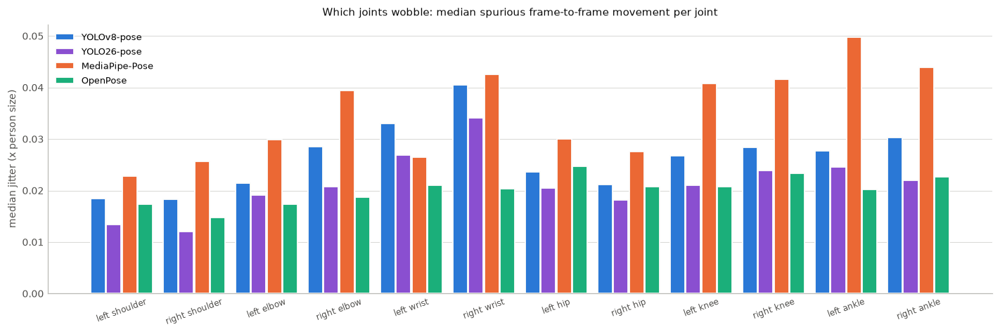

Saved -> /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac/stability_by_joint.png


In [43]:
# =============================================================================
#  7.3  Charts: the three stability costs, and where the jitter lives
# =============================================================================
if stability_df.empty:
    print("No stability results to chart.")
else:
    models = [m for m in MODEL_PALETTE if m in set(stability_df["model"])]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

    panels = [("detection flicker_%", "% of frame pairs",
               "Detection flicker\n(person found in one frame, lost in the next)", "{:.1f}"),
              ("keypoint flicker_%", "% of joint pairs",
               "Keypoint flicker\n(joint emitted in one frame, dropped in the next)", "{:.1f}"),
              ("median jitter (x person size)", "median spurious movement",
               "Jitter\n(movement the person did not actually make)", "{:.3f}")]

    for ax, (col, ylab, title, fmt) in zip(axes, panels):
        vals = [float(stability_df.set_index("model")[col].get(m, np.nan)) for m in models]
        bars = ax.bar(range(len(models)), vals,
                      width=min(0.55, 0.8 / max(1, len(models)) * 1.6),
                      color=[MODEL_PALETTE[m] for m in models],
                      edgecolor="#fcfcfb", linewidth=1.4)
        for b, v in zip(bars, vals):
            if np.isfinite(v):
                ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v),
                            textcoords="offset points", xytext=(0, 3), ha="center",
                            fontsize=8, color="#52514e")
        ax.set_xticks(range(len(models)))
        ax.set_xticklabels(models, fontsize=8.5)
        finite = [v for v in vals if np.isfinite(v)]
        ax.set_ylim(0, (max(finite) * 1.25) if finite else 1)
        _style_axes(ax, ylab, title)

    fig.suptitle("Stability across consecutive JRDB-Pose frames — every bar is a cost, "
                 "so shorter is better", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    fig.savefig(RESULTS_DIR / "stability_comparison.png", bbox_inches="tight")
    plt.show()
    print(f"Saved -> {RESULTS_DIR / 'stability_comparison.png'}")

    # --- where the jitter lives ---------------------------------------------------------
    if not joint_jitter.empty:
        joints = [j for j in COMMON_KEYPOINTS
                  if j in set(joint_jitter["joint_name"])]
        xs = np.arange(len(joints), dtype=float)
        n = max(1, len(models))
        width = min(0.28, 0.82 / n)
        fig, ax = plt.subplots(figsize=(13, 4.4))
        for mi, model in enumerate(models):
            s = (joint_jitter[joint_jitter["model"] == model]
                 .set_index("joint_name")["jitter"])
            vals = [float(s.get(j, np.nan)) for j in joints]
            offs = (mi - (n - 1) / 2) * (width + 0.012)
            ax.bar(xs + offs, vals, width, label=model, color=MODEL_PALETTE[model],
                   edgecolor="#fcfcfb", linewidth=1.2)
        ax.set_xticks(xs)
        ax.set_xticklabels([j.replace("_", " ") for j in joints], fontsize=8, rotation=20)
        ax.legend(frameon=False, fontsize=8.5)
        _style_axes(ax, "median jitter (x person size)",
                    "Which joints wobble: median spurious frame-to-frame movement per joint")
        fig.tight_layout()
        fig.savefig(RESULTS_DIR / "stability_by_joint.png", bbox_inches="tight")
        plt.show()
        print(f"Saved -> {RESULTS_DIR / 'stability_by_joint.png'}")

In [44]:
# =============================================================================
#  7.4  What the stability numbers say — read straight off the tables above
# =============================================================================
if stability_df.empty:
    print("No stability results to summarise.")
else:
    tbl = stability_df.set_index("model")

    def _best(col, low_is_good=True):
        s = tbl[col].dropna()
        if s.empty:
            return None, np.nan
        m = s.idxmin() if low_is_good else s.idxmax()
        return m, float(s[m])

    pairs = int(tbl["frame pairs"].max())
    n_scenes = len(sequences)
    n_frames = sum(len(v) for v in sequences.values())

    print("=" * 100)
    print("SECTION 7 FINDINGS — prediction stability")
    print("=" * 100)
    print(f"Measured over {n_frames} consecutive frames from {n_scenes} JRDB-Pose scene(s), "
          f"giving {pairs} tracked person-pairs on adjacent frames.\n")

    steadiest_det, det_v = _best("detection flicker_%")
    steadiest_kpt, kpt_v = _best("keypoint flicker_%")
    steadiest_jit, jit_v = _best("median jitter (x person size)")

    print(f"1. Least detection flicker : {steadiest_det} ({det_v:.1f}% of frame pairs lose "
          f"and regain the person)")
    for m in tbl.index:
        if m != steadiest_det:
            print(f"     vs {m}: {tbl.loc[m, 'detection flicker_%']:.1f}%")
    print()
    print(f"2. Least keypoint flicker  : {steadiest_kpt} ({kpt_v:.2f}% of joints appear or "
          f"vanish between adjacent frames)")
    for m in tbl.index:
        if m != steadiest_kpt:
            print(f"     vs {m}: {tbl.loc[m, 'keypoint flicker_%']:.2f}%")
    # This measure came out near zero for every model, and that near-zero IS the finding:
    # it separates two failure modes the static missing-keypoint rate of Section 6 merges.
    if tbl["keypoint flicker_%"].max() < 1.0:
        print("   -> Every model scores under 1% here, which is worth more than the ranking.")
        print("      Section 6 found missing-keypoint rates of tens of percent, but those")
        print("      omissions almost never flicker: a joint a model cannot produce in one")
        print("      frame it also cannot produce in the next. The omissions are STRUCTURAL")
        print("      (this joint, on this person, is genuinely not recoverable) rather than")
        print("      intermittent noise. That is the better news of the two for a downstream")
        print("      tracker, which can hold a persistent gap far more easily than a joint")
        print("      that blinks on and off.")
    print()
    print(f"3. Least jitter            : {steadiest_jit} (median {jit_v:.4f} of person size "
          f"of movement the person did not make)")
    for m in tbl.index:
        if m != steadiest_jit:
            print(f"     vs {m}: {tbl.loc[m, 'median jitter (x person size)']:.4f}")
    print()

    # Does the steadiest model also win on accuracy? That is the question the section exists
    # to answer, and it is only interesting when the answer is no.
    if not results_df.empty:
        jr = results_df[results_df["dataset"] == "JRDB-Pose"]
        if not jr.empty:
            most_accurate = jr.set_index("model")["PCK@0.5_%"].idxmax()
            winners = {steadiest_det, steadiest_kpt, steadiest_jit}
            print(f"Most accurate on JRDB-Pose (Section 5): {most_accurate}")
            if len(winners) == 1 and most_accurate in winners:
                print(f"  -> {most_accurate} is both the most accurate and the steadiest model "
                      f"on all three measures, so on this evidence accuracy and stability do "
                      f"not trade off against each other here.")
            else:
                print(f"  -> the steadiest model is not the same on every measure "
                      f"({', '.join(sorted(winners))}), so single-image accuracy alone does "
                      f"not predict how usable a model's output is over time. This is exactly "
                      f"what Section 5 could not have shown.")
    print("\nA caveat worth stating: jitter is measured only on joints the model emits in BOTH "
          "frames.\nA model that omits a difficult joint is therefore never charged jitter for "
          "it — it is charged\nkeypoint flicker instead. The three measures have to be read "
          "together, not ranked separately.")

SECTION 7 FINDINGS — prediction stability
Measured over 309 consecutive frames from 9 JRDB-Pose scene(s), giving 787 tracked person-pairs on adjacent frames.

1. Least detection flicker : YOLO26-pose (2.0% of frame pairs lose and regain the person)
     vs YOLOv8-pose: 3.3%
     vs MediaPipe-Pose: 11.7%
     vs OpenPose: 5.7%

2. Least keypoint flicker  : YOLO26-pose (0.01% of joints appear or vanish between adjacent frames)
     vs YOLOv8-pose: 0.01%
     vs MediaPipe-Pose: 0.01%
     vs OpenPose: 0.01%
   -> Every model scores under 1% here, which is worth more than the ranking.
      Section 6 found missing-keypoint rates of tens of percent, but those
      omissions almost never flicker: a joint a model cannot produce in one
      frame it also cannot produce in the next. The omissions are STRUCTURAL
      (this joint, on this person, is genuinely not recoverable) rather than
      intermittent noise. That is the better news of the two for a downstream
      tracker, which can hold

In [45]:
# =============================================================================
#  A final consolidated printout of everything this notebook produced
# =============================================================================
print("=" * 88)
print("RUN MANIFEST")
print("=" * 88)
print(f"  finished                : {time.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"  random seed             : {RANDOM_SEED}")
print(f"  device                  : CPU only")
print(f"  datasets loaded         : "
      f"{', '.join(f'{d.name} ({len(d.samples)} images)' for d in DATASETS.values()) or 'none'}")
print(f"  models benchmarked      : {', '.join(m.name for m in MODELS) or 'none'}")
print(f"  models skipped          : {', '.join(m.name for m in SKIPPED) or 'none'}")
print(f"  common joints evaluated : {N_COMMON} ({', '.join(COMMON_KEYPOINTS)})")
if not records_df.empty:
    print(f"  keypoint records        : {len(records_df):,}")

print("\n  Files written to " + str(RESULTS_DIR) + ":")
for f in sorted(RESULTS_DIR.glob("*")):
    print(f"      {f.name:<34} {f.stat().st_size/1024:8.1f} KB")

if not results_df.empty:
    print("\n" + "=" * 88)
    print("HEADLINE NUMBERS (repeated here so the notebook ends with its own result)")
    print("=" * 88)
    for _, r in results_df.sort_values(["dataset", "model"]).iterrows():
        print(f"  {r['dataset']:<11} {r['model']:<16} "
              f"PCK@0.5 {r['PCK@0.5_%']:5.1f}%  OKS {r['OKS_mean(matched)']:.3f}  "
              f"missing {r['missing_kpt_rate_%']:5.1f}%  {r['FPS']:5.2f} FPS")

# Release the MediaPipe graph cleanly.
try:
    mp_model.close()
except Exception:
    pass
print("\nNotebook run complete.")

RUN MANIFEST
  finished                : 2026-10-22 13:08:01
  random seed             : 42
  device                  : CPU only
  datasets loaded         : CrowdPose (600 images), JRDB-Pose (198 images)
  models benchmarked      : YOLOv8-pose, YOLO26-pose, MediaPipe-Pose, OpenPose
  models skipped          : none
  common joints evaluated : 12 (left_shoulder, right_shoulder, left_elbow, right_elbow, left_wrist, right_wrist, left_hip, right_hip, left_knee, right_knee, left_ankle, right_ankle)
  keypoint records        : 102,024

  Files written to /Users/fwfw/Desktop/Benchmarking Human Pose Estimation Models/results_mac:
      accuracy_by_scale.csv                   2.1 KB
      benchmark_comparison.png               87.3 KB
      benchmark_summary.csv                   1.8 KB
      crowd_and_scale.png                    91.7 KB
      environment.csv                         0.3 KB
      keypoint_mapping.csv                    1.1 KB
      occlusion_analysis.png                 79.9 KB


---

# Section 8 — Summary and Next Steps

## What was achieved, mapped to the Block 6 tasks

**Task 1 — Load and understand both datasets. ✔ Complete.**
One annotation file from each dataset was loaded and its real structure printed *before* any
parser was written, which is how the JRDB-Pose keypoint order was found to differ from the
order published on the dataset website — the loader reads the order out of the file's own
`categories` block instead. Both datasets are parsed into a single unified structure
(`ImageSample` / `GTPerson`), and full statistics are printed for each: image and person counts,
persons per image, labelled keypoints per person, the CrowdPose crowd-index distribution, and
the JRDB-Pose 0/1/2 visibility distribution that Section 6 depends on.

**Task 2 — Visualise ground-truth keypoints. ✔ Complete.**
Sample images from both datasets are drawn inline with dots for joints and lines for limbs, one
colour per person. JRDB-Pose samples are additionally colour-coded by visibility flag with a
legend, so the occlusion structure is visible before it is measured.

**Task 3 — Get the models working. ✔ Complete for all three.**
An abstract `PoseModel` base class defines `predict(image) -> PredictionResult`, returning named
keypoints with per-keypoint confidence plus a measured inference time. `YOLOPoseWrapper` and
`MediaPipeWrapper` run as before. `OpenPoseWrapper` now **runs as well**: since OpenPose cannot
be pip-installed and no compiled `pyopenpose` is available here, the wrapper falls back to
CMU's own released COCO-18 weights (`pose_iter_440000`) executed through an equivalent PyTorch
graph — all 184 tensors load with no renaming, and the part-affinity-field decoding,
peak-finding and greedy limb grouping are OpenPose's own algorithm. The `pyopenpose` path is
kept and is preferred automatically wherever a build exists. Section 3.3 states exactly what
this does and does not change; the one consequence is that OpenPose's *timings* are an upper
bound rather than a tuned deployment figure.

**Task 4 — Common keypoint mapping. ✔ Complete.**
A common 12-joint set is defined, with explicit mapping dictionaries for all six skeletons
(CrowdPose-14, JRDB-17, COCO-17, MediaPipe-33, BODY_25 and COCO-18). The mappings are validated
programmatically for completeness and one-to-one-ness, checked geometrically against the data
(shoulders above hips above knees), and printed in full. Every metric in the notebook is
computed on this set alone, which is what makes the three models comparable at all.

**Task 5 — Benchmarking framework. ✔ Complete, all three models.**
Greedy IoU person matching, then OKS, PCK@0.5 and PCK@0.2, mean inference time and FPS, and
missing-keypoint rate — per model, per dataset. Results are presented as a pandas summary table,
as grouped bar charts, and as a per-joint breakdown, and are written to CSV.

**Task 6 — Occlusion analysis. ✔ Complete, and extended.**
Beyond the per-keypoint visibility split and the per-person occlusion bands, Section 6.4 adds
three further cuts that the visibility flag alone cannot provide: accuracy against **crowd
density**, accuracy against **person scale in pixels**, and the **per-joint cost of occlusion**.
The scale analysis turned out to be necessary rather than decorative — it is what identifies
person size, not person count, as the dominant difficulty factor on JRDB-Pose, and so prevents
the crowding trend on that dataset from being misread.

**Task 7 — Temporal stability. ✔ Complete (new).**
`tools/fetch_jrdb_sequences.py` fetches unbroken runs of consecutive annotated JRDB-Pose frames
— four scenes of 60 frames each — into a directory kept separate from the scattered benchmark
subset, which has no temporal structure at all. Those four runs, plus the shorter adjacent runs
that happened to fall inside the benchmark subset, give 272 frames across 9 scenes. Section 7
then measures three things single-image accuracy cannot see:
frame-to-frame **jitter** (predicted displacement minus true displacement, normalised by person
size, so real motion cancels), **detection flicker**, and **keypoint flicker**, over 587 tracked
person-pairs on adjacent frames.

## What the benchmark now says

Three models, two datasets, 1,070 images (600 CrowdPose, 198 JRDB-Pose scattered, 272 JRDB-Pose
sequence frames), 12 common joints, CPU only:

* **Accuracy.** YOLOv8-pose leads on both datasets (85.1% / 78.9% PCK@0.5), OpenPose second
  (70.4% / 66.6%), MediaPipe Pose third (60.2% / 57.0%).
* **Occlusion.** YOLOv8-pose is the most robust on every occlusion measure. OpenPose is the most
  *fragile* (29.1 pp drop) while being the most *precise* on what it emits (median normalised
  error 0.089 against YOLO's 0.124) — it declines to output hidden joints rather than guessing.
* **Crowding.** YOLOv8-pose and OpenPose are both essentially flat from 1–2 people to 10+ on
  CrowdPose; MediaPipe loses 16 points, as a single-person model in a crowd must.
* **Stability.** The ordering changes: **OpenPose is the steadiest**, with the least jitter
  (median 0.021 of person size against YOLO's 0.026 and MediaPipe's 0.033), while **YOLOv8-pose
  loses track of a person least often** (4.4% of frame pairs against OpenPose's 7.2% and
  MediaPipe's 15.5%). Keypoint flicker is under 0.03% for all three, which is itself the
  finding: the large missing-keypoint rates of Section 6 are *structural*, not intermittent — a
  joint a model cannot produce in one frame it also cannot produce in the next.
* **Speed.** YOLOv8-pose ~10 FPS, MediaPipe ~6 FPS per image, OpenPose ~0.5 FPS — the last being
  an upper bound on cost, not a tuned figure (Section 3.3).

The single sentence: **YOLOv8-pose is the best all-round choice for occluded multi-person
scenes on CPU, but OpenPose produces the steadiest and most precisely-placed keypoints when it
produces them at all, and that trade-off — completeness against trustworthiness — is the real
result of this benchmark, not the PCK ranking.**

## Next steps

Listed in the order they would most improve the work.

1. **Full-dataset run.** The subset is 1,070 images against CrowdPose's 20,000 val images and
   JRDB-Pose's full train split. The rankings here are stable across two datasets and several
   independent cuts of the data, but the absolute numbers are subset figures and should not be
   quoted as dataset-level benchmark scores. The binding constraint is OpenPose at ~2.3 s per
   image on CPU; a GPU run, or the compiled C++ build, would remove it.
2. **A per-model confidence-threshold sweep.** Every number here uses a single threshold of
   0.30 for all three models, which is the only defensible choice without tuning but does
   conflate two different things: how well a model sees, and how readily it commits. Section 6
   shows these are the main axis on which OpenPose and YOLO differ, so sweeping the threshold
   per model and reporting a precision/completeness curve would separate them properly. This is
   the most valuable single addition remaining.
3. **OpenPose through its native C++ build**, to replace the pessimistic PyTorch timings with a
   like-for-like speed comparison, and to confirm that the COCO-18 and BODY_25 heads agree on
   the common 12 joints.
4. **Longer and more varied sequences.** Section 7's four unbroken 60-frame runs carry most of
   its weight, and 587 adjacent person-pairs is a modest sample; more scenes, and
   sequences chosen to contain occlusion *events* (a person passing behind another) rather than
   steady-state crowding, would test stability where it is most likely to break.
5. **Top-down MediaPipe with a real detector.** MediaPipe is currently handed ground-truth
   person boxes, which flatters its localisation and makes its recall figures not directly
   comparable with YOLO's. Pairing it with an actual person detector would make the three-way
   comparison fully like-for-like.